In [1]:
import torch
import torchvision
from torch import nn, optim
from torch.nn import functional as F
import matplotlib.pyplot as plt
from pylab import rcParams
import numpy as np
import os
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Set up plotting parameters
rcParams['figure.figsize'] = 8, 8
plt.ion()  # Interactive plotting

print("✅ All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


✅ All libraries imported successfully!
PyTorch version: 2.15.0+cu132
Using device: CUDA


In [2]:
# Training configuration
BATCH_SIZE = 128        # How many data points to process at once
EPOCHS = 100           # How many times to see the entire dataset
LOG_INTERVAL = 50      # How often to print progress updates

# Model architecture
INPUT_DIM = 28 * 28
NOISE_DIM = 16
GENERATOR_FEATURE_MAPS = 128
DISCRIMINATOR_FEATURE_MAPS = 128

# GAN-specific hyperparameters
LR_G = 4e-4           # Learning rate for Generator
LR_D = 2e-4           # Learning rate for Discriminator
BETA1 = 0.5           # Beta1 for Adam optimizer

# Visualization settings
SAVE_PLT_INTERVAL = 5   # How often to save plots (every 5 epochs)

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Batch size: {BATCH_SIZE}")
print(f"Epochs: {EPOCHS}")
print(f"Generator feature maps: {GENERATOR_FEATURE_MAPS}")
print(f"Discriminator feature maps: {DISCRIMINATOR_FEATURE_MAPS}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Device: {device}")


Batch size: 128
Epochs: 100
Generator feature maps: 128
Discriminator feature maps: 128
Generator learning rate: 0.0004
Discriminator learning rate: 0.0002
Device: cuda


In [3]:
train_data = torchvision.datasets.MNIST(
    root='data/',
    train=True,
    download=True,
    transform=torchvision.transforms.ToTensor()
)
test_data = torchvision.datasets.MNIST(
    root='data/',
    train=False,
    download=True,
    transform=torchvision.transforms.ToTensor()
)

print(f"Training data shape: {train_data.data.shape}")
print(f"Test data shape: {test_data.data.shape}")

Training data shape: torch.Size([60000, 28, 28])
Test data shape: torch.Size([10000, 28, 28])


In [4]:
# Set up data loaders
# pin_memory=True speeds up data transfer to GPU (if available)
kwargs = {'num_workers': 4, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = torch.utils.data.DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

test_loader = torch.utils.data.DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

print(f"Batch size: {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")

Batch size: 128
Training batches: 469
Test batches: 79


In [5]:
class Generator(nn.Module):
    """Generate grayscale MNIST images from random noise using convolutions."""

    def __init__(self, noise_dim, feature_maps):
        super().__init__()

        self.net = nn.Sequential(
            nn.Unflatten(1, (noise_dim, 1, 1)),

            nn.ConvTranspose2d(noise_dim, feature_maps * 2, kernel_size=7, bias=False),
            nn.BatchNorm2d(feature_maps * 2),
            nn.ReLU(),

            nn.ConvTranspose2d(feature_maps * 2, feature_maps, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(feature_maps),
            nn.ReLU(),

            nn.ConvTranspose2d(feature_maps, 1, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid(),
        )

    def forward(self, noise):
        """
        Args:
            noise: Random noise of shape (batch_size, noise_dim).

        Returns:
            Images of shape (batch_size, 1, 28, 28) with values in [0, 1].
        """
        return self.net(noise)



In [6]:
class Discriminator(nn.Module):
    """Classify grayscale MNIST images as real or fake using convolutions."""

    def __init__(self, feature_maps):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(1, feature_maps, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),

            nn.Conv2d(feature_maps, feature_maps * 2, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(feature_maps * 2),
            nn.LeakyReLU(0.2),

            nn.Conv2d(feature_maps * 2, 1, kernel_size=7),
            nn.Flatten(1),
            nn.Sigmoid(),
        )

    def forward(self, data):
        """
        Args:
            data: Images of shape (batch_size, 1, 28, 28).

        Returns:
            Real-data probabilities of shape (batch_size, 1).
        """
        return self.net(data)



In [7]:
# Initialize models
generator = Generator(NOISE_DIM, GENERATOR_FEATURE_MAPS)
discriminator = Discriminator(DISCRIMINATOR_FEATURE_MAPS)

# Move models to device and ensure correct dtype
generator = generator.to(device).float()
discriminator = discriminator.to(device).float()

# Set up optimizers for both networks
# We use different optimizers for Generator and Discriminator
optimizer_G = torch.optim.Adam(generator.parameters(), lr=LR_G, betas=(BETA1, 0.999))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=LR_D, betas=(BETA1, 0.999))

# Loss function for GAN training
criterion = nn.BCELoss()  # Binary Cross Entropy Loss

print(f"Generator parameters: {sum(p.numel() for p in generator.parameters()):,}")
print(f"Discriminator parameters: {sum(p.numel() for p in discriminator.parameters()):,}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Models moved to device: {device}")
print(f"Models dtype: {next(generator.parameters()).dtype}")

# Let's see what our models look like
print("\nGenerator architecture:")
print(generator)
print("\nDiscriminator architecture:")
print(discriminator)


Generator parameters: 727,809
Discriminator parameters: 539,521
Generator learning rate: 0.0004
Discriminator learning rate: 0.0002
Models moved to device: cuda
Models dtype: torch.float32

Generator architecture:
Generator(
  (net): Sequential(
    (0): Unflatten(dim=1, unflattened_size=(16, 1, 1))
    (1): ConvTranspose2d(16, 256, kernel_size=(7, 7), stride=(1, 1), bias=False)
    (2): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ReLU()
    (4): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): ConvTranspose2d(128, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (8): Sigmoid()
  )
)

Discriminator architecture:
Discriminator(
  (net): Sequential(
    (0): Conv2d(1, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2

In [8]:
# Complete visualization function with validation support
def visualize_training_progress_complete(epoch, train_d_losses, train_g_losses, val_d_losses=None, val_g_losses=None):
    """
    Complete visualization function for GAN training progress with validation support.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        val_d_losses: List of discriminator validation losses (optional)
        val_g_losses: List of generator validation losses (optional)
    """
    # Generate samples
    fake_samples = generate_samples(train_data.shape[0])
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))
    
    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(train_data[:, 0], train_data[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Real Training Data\\n(Moons + Circles)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.6)
    plt.title(f'Generated Samples (Epoch {epoch})')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(train_data[:2000, 0], train_data[:2000, 1], c='blue', s=1, alpha=0.3, label='Real')
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Comparison (Real vs Generated)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > skip_epochs and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > 0 and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()


In [9]:
# Ensure train_discriminator function is defined (in case cells weren't executed in order)
def train_discriminator(real_data, batch_size):
    """
    Train the Discriminator to distinguish between real and fake data.
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    # Clear gradients
    optimizer_D.zero_grad()
    
    # Ensure data is on correct device and dtype
    real_data = real_data.to(device).float()
    
    # Train on real data
    # Create labels for real data (all should be 1)
    real_labels = torch.ones(batch_size, 1, dtype=torch.float32).to(device)
    
    # Get discriminator predictions on real data
    real_output = discriminator(real_data)
    
    # Compute loss for real data (we want high probability)
    real_loss = criterion(real_output, real_labels)
    
    # Train on fake data
    # Generate fake data using the generator
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (all should be 0)
    fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data.detach())  # detach() prevents gradients flowing to generator
    
    # Compute loss for fake data (we want low probability)
    fake_loss = criterion(fake_output, fake_labels)
    
    # Total discriminator loss
    d_loss = real_loss + fake_loss
    
    # Backpropagate and update discriminator
    d_loss.backward()
    optimizer_D.step()
    
    return d_loss.item()

def evaluate_discriminator(real_data, batch_size):
    """
    Evaluate the Discriminator on validation data (no training).
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    with torch.no_grad():
        # Ensure data is on correct device and dtype
        real_data = real_data.to(device).float()
        
        # Evaluate on real data
        real_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        real_output = discriminator(real_data)
        real_loss = criterion(real_output, real_labels)
        
        # Evaluate on fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
        fake_output = discriminator(fake_data)
        fake_loss = criterion(fake_output, fake_labels)
        
        # Total discriminator loss
        d_loss = real_loss + fake_loss
        
    return d_loss.item()

In [10]:
def train_generator(batch_size):
    """
    Train the Generator to create data that fools the Discriminator.
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    # Clear gradients
    optimizer_G.zero_grad()
    
    # Generate fake data
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (we want discriminator to think it's real)
    fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data)
    
    # Compute generator loss (we want discriminator to output high probability)
    g_loss = criterion(fake_output, fake_labels)
    
    # Backpropagate and update generator
    g_loss.backward()
    optimizer_G.step()
    
    return g_loss.item()

def evaluate_generator(batch_size):
    """
    Evaluate the Generator on validation data (no training).
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    with torch.no_grad():
        # Generate fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        
        # Create labels for fake data (we want discriminator to think it's real)
        fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        
        # Get discriminator predictions on fake data
        fake_output = discriminator(fake_data)
        
        # Compute generator loss (we want discriminator to output high probability)
        g_loss = criterion(fake_output, fake_labels)
        
    return g_loss.item()


In [11]:
def train_epoch_with_validation(epoch):
    """
    Train both Generator and Discriminator for one epoch with validation.
    
    Args:
        epoch: Current epoch number
    
    Returns:
        avg_d_loss: Average discriminator training loss for this epoch
        avg_g_loss: Average generator training loss for this epoch
        val_d_loss: Average discriminator validation loss
        val_g_loss: Average generator validation loss
    """
    # Set models to training mode
    generator.train()
    discriminator.train()
    
    # Track losses
    d_losses = []
    g_losses = []
    
    for batch_idx, (data, labels) in enumerate(train_loader):
        batch_size = data.size(0)
        data = data.to(device)
        
        # Train Discriminator
        d_loss = train_discriminator(data, batch_size)
        d_losses.append(d_loss)

        # Train Generator
        g_loss = train_generator(batch_size)
        g_losses.append(g_loss)
        
        # Print progress
        if batch_idx % LOG_INTERVAL == 0:
            print('Epoch: {} [{}/{} ({:.0f}%)]\tD_loss: {:.6f}\tG_loss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), d_loss, g_loss))
    
    # Calculate average training losses
    avg_d_loss = sum(d_losses) / len(d_losses)
    avg_g_loss = sum(g_losses) / len(g_losses)
    
    # Evaluate on validation set
    generator.eval()
    discriminator.eval()
    
    val_d_losses = []
    val_g_losses = []
    
    for batch_idx, (data, labels) in enumerate(test_loader):
        batch_size = data.size(0)
        
        # Evaluate Discriminator
        val_d_loss = evaluate_discriminator(data, batch_size)
        val_d_losses.append(val_d_loss)
        
        # Evaluate Generator
        val_g_loss = evaluate_generator(batch_size)
        val_g_losses.append(val_g_loss)
    
    # Calculate average validation losses
    val_d_loss = sum(val_d_losses) / len(val_d_losses)
    val_g_loss = sum(val_g_losses) / len(val_g_losses)
    
    print('====> Epoch: {} Train D_loss: {:.4f}, Train G_loss: {:.4f}'.format(
        epoch, avg_d_loss, avg_g_loss))
    print('====> Epoch: {} Val D_loss: {:.4f}, Val G_loss: {:.4f}'.format(
        epoch, val_d_loss, val_g_loss))
    
    return avg_d_loss, avg_g_loss, val_d_loss, val_g_loss


In [12]:
def generate_samples(num_samples=1000):
    """
    Generate fake samples using the current Generator.
    
    Args:
        num_samples: Number of samples to generate
    
    Returns:
        fake_samples: Flattened images as a numpy array of shape (num_samples, INPUT_DIM)
    """
    generator.eval()  # Set to evaluation mode
    
    with torch.no_grad():  # Don't compute gradients
        # Generate in batches to limit convolutional activation memory.
        samples = []
        for start in range(0, num_samples, BATCH_SIZE):
            batch_size = min(BATCH_SIZE, num_samples - start)
            noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
            # Flatten only for PCA and the existing image visualizations.
            samples.append(generator(noise).flatten(1).cpu())
        fake_samples = torch.cat(samples).numpy()
    
    return fake_samples


def pca_fit(data):
    pipeline = Pipeline([
        ('scaling', StandardScaler()),
        ('pca', PCA(n_components=2))
    ])
    pipeline.fit(data)

    return pipeline

In [13]:
# Simplified visualization function without validation
def visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses):
    """
    Visualize the current state of our GAN training with loss plots.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        save_plot: Whether to save the plot to disk
    """
    # Generate samples
    generated_samples = generate_samples(2000)
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))

    train_data_reshaped = np.reshape(train_data.data[:2000], [2000, INPUT_DIM])
    data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
    x_transformed = pca_fit(generated_samples).transform(generated_samples)

    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Original Training Data')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
    plt.title('Generated Samples')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Overlay Comparison')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    plt.show()

    plt.figure(figsize=(20, 10))

    for i in range(20):
        plt.subplot(4, 5,  i + 1)
        plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


🎯 Starting GAN training...
📊 Initial state (before training):

📊 Epoch 1/100
----------------------------------------
Epoch: 1 [0/60000 (0%)]	D_loss: 1.431157	G_loss: 1.324895
Epoch: 1 [6400/60000 (11%)]	D_loss: 1.065743	G_loss: 1.504207
Epoch: 1 [12800/60000 (21%)]	D_loss: 1.144981	G_loss: 1.111229
Epoch: 1 [19200/60000 (32%)]	D_loss: 1.217403	G_loss: 1.600040
Epoch: 1 [25600/60000 (43%)]	D_loss: 1.297569	G_loss: 0.543629
Epoch: 1 [32000/60000 (53%)]	D_loss: 1.138657	G_loss: 0.792432
Epoch: 1 [38400/60000 (64%)]	D_loss: 1.141063	G_loss: 0.986409
Epoch: 1 [44800/60000 (75%)]	D_loss: 1.145810	G_loss: 0.692290
Epoch: 1 [51200/60000 (85%)]	D_loss: 1.388531	G_loss: 0.808844
Epoch: 1 [57600/60000 (96%)]	D_loss: 1.073940	G_loss: 1.122470
====> Epoch: 1 Train D_loss: 1.1381, Train G_loss: 1.1546
====> Epoch: 1 Val D_loss: 1.3910, Val G_loss: 0.4459
📈 Epoch 1 Summary:
   Train D Loss: 1.1381, Val D Loss: 1.3910
   Train G Loss: 1.1546, Val G Loss: 0.4459

📊 Epoch 2/100
------------------------

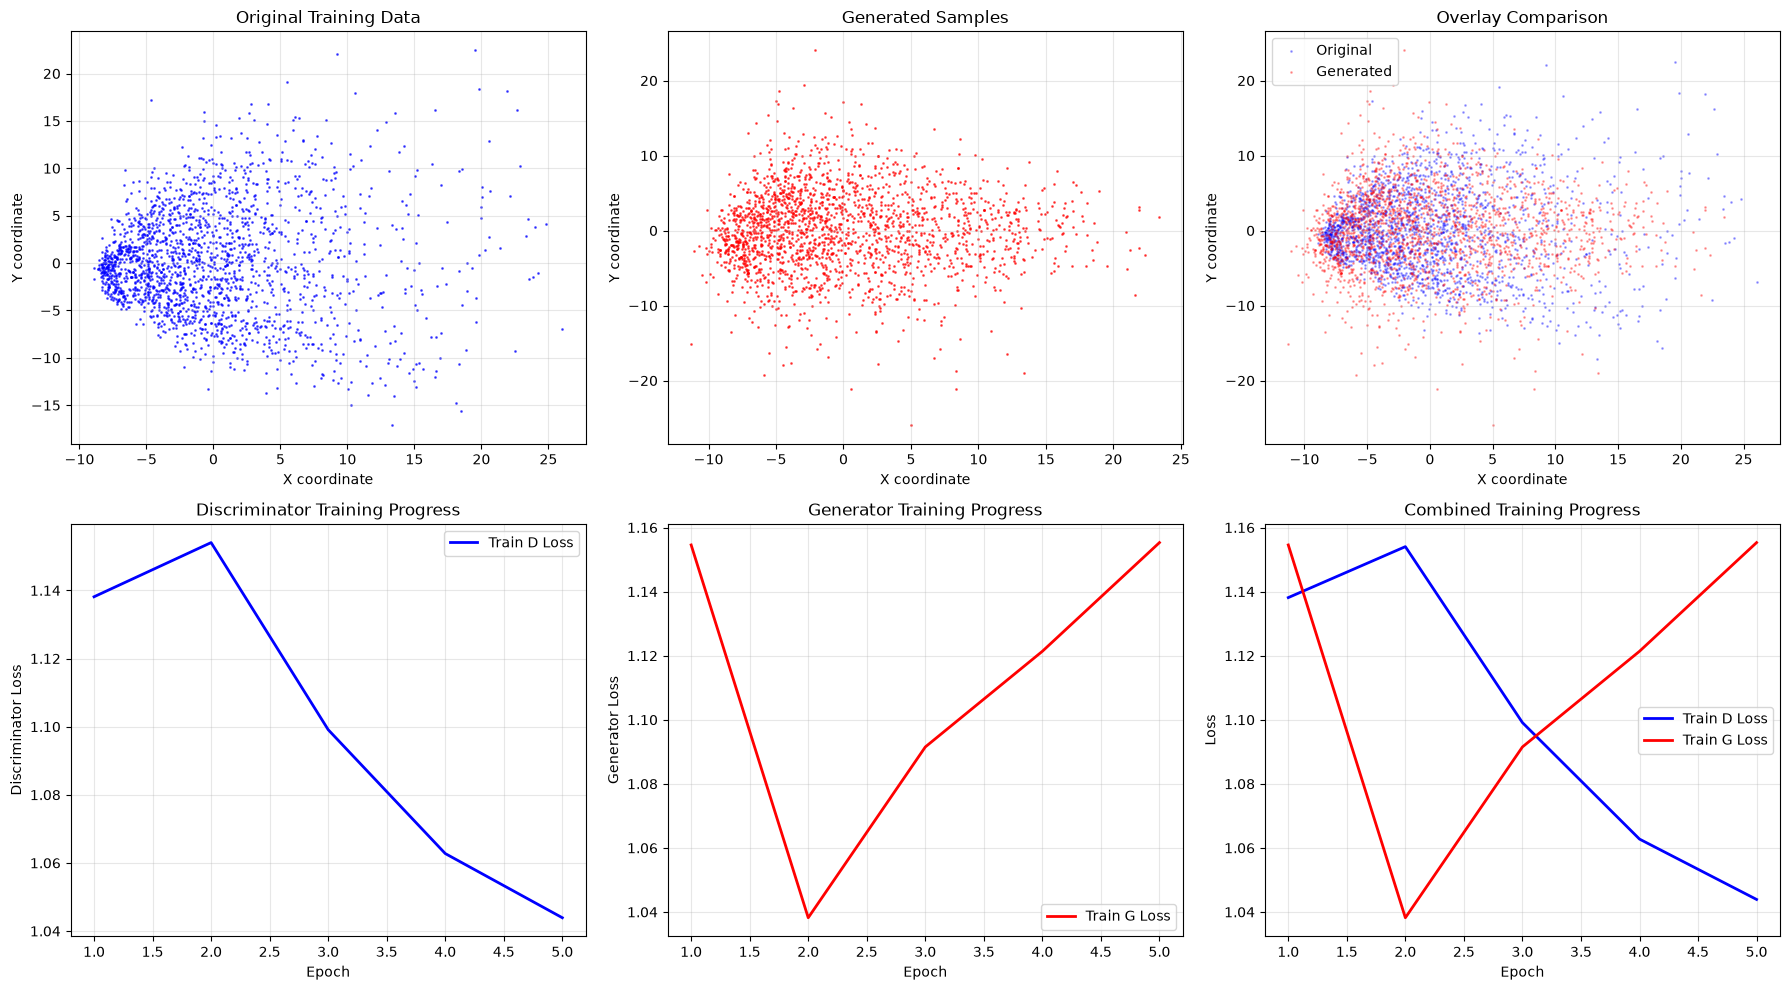

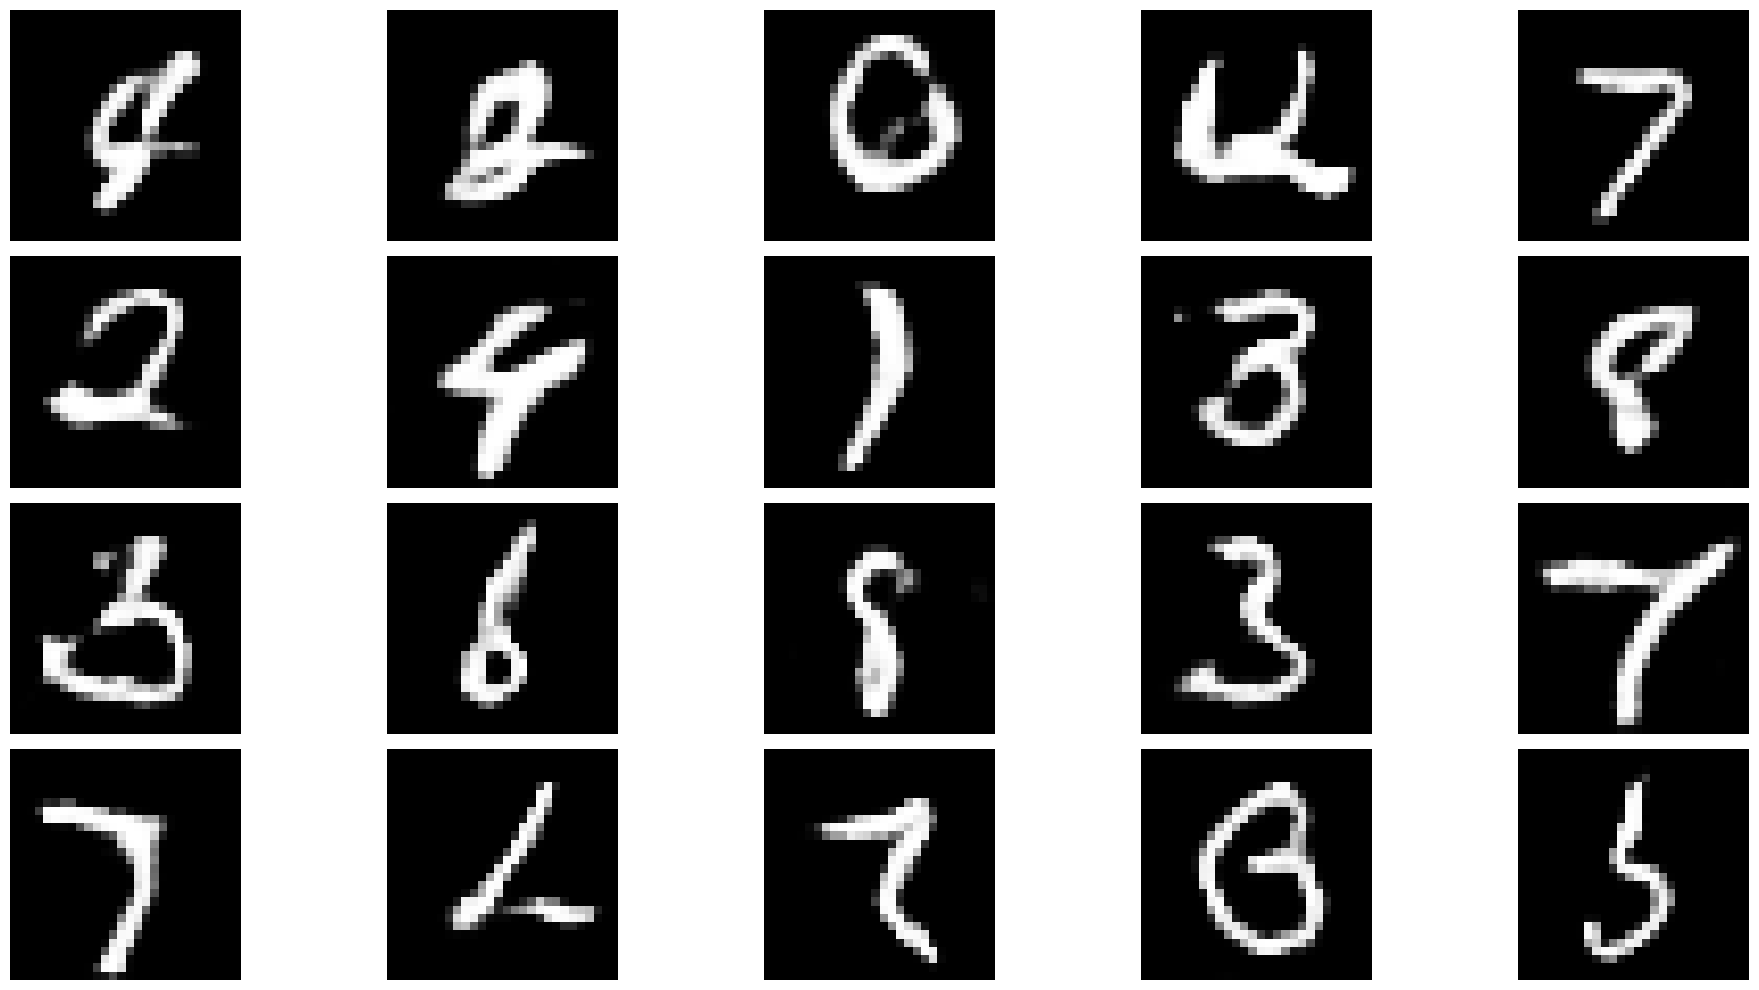

📈 Epoch 5 Summary:
   Train D Loss: 1.0439, Val D Loss: 1.1161
   Train G Loss: 1.1553, Val G Loss: 0.8213

📊 Epoch 6/100
----------------------------------------
Epoch: 6 [0/60000 (0%)]	D_loss: 1.061548	G_loss: 1.606201
Epoch: 6 [6400/60000 (11%)]	D_loss: 0.981185	G_loss: 1.268135
Epoch: 6 [12800/60000 (21%)]	D_loss: 0.929517	G_loss: 0.946166
Epoch: 6 [19200/60000 (32%)]	D_loss: 1.696936	G_loss: 2.031403
Epoch: 6 [25600/60000 (43%)]	D_loss: 1.001833	G_loss: 1.099938
Epoch: 6 [32000/60000 (53%)]	D_loss: 0.955008	G_loss: 1.651477
Epoch: 6 [38400/60000 (64%)]	D_loss: 1.116452	G_loss: 1.739458
Epoch: 6 [44800/60000 (75%)]	D_loss: 0.987773	G_loss: 1.356997
Epoch: 6 [51200/60000 (85%)]	D_loss: 0.981883	G_loss: 0.598236
Epoch: 6 [57600/60000 (96%)]	D_loss: 1.024598	G_loss: 1.033968
====> Epoch: 6 Train D_loss: 1.0383, Train G_loss: 1.1837
====> Epoch: 6 Val D_loss: 1.1245, Val G_loss: 1.1912
📈 Epoch 6 Summary:
   Train D Loss: 1.0383, Val D Loss: 1.1245
   Train G Loss: 1.1837, Val G Loss: 1

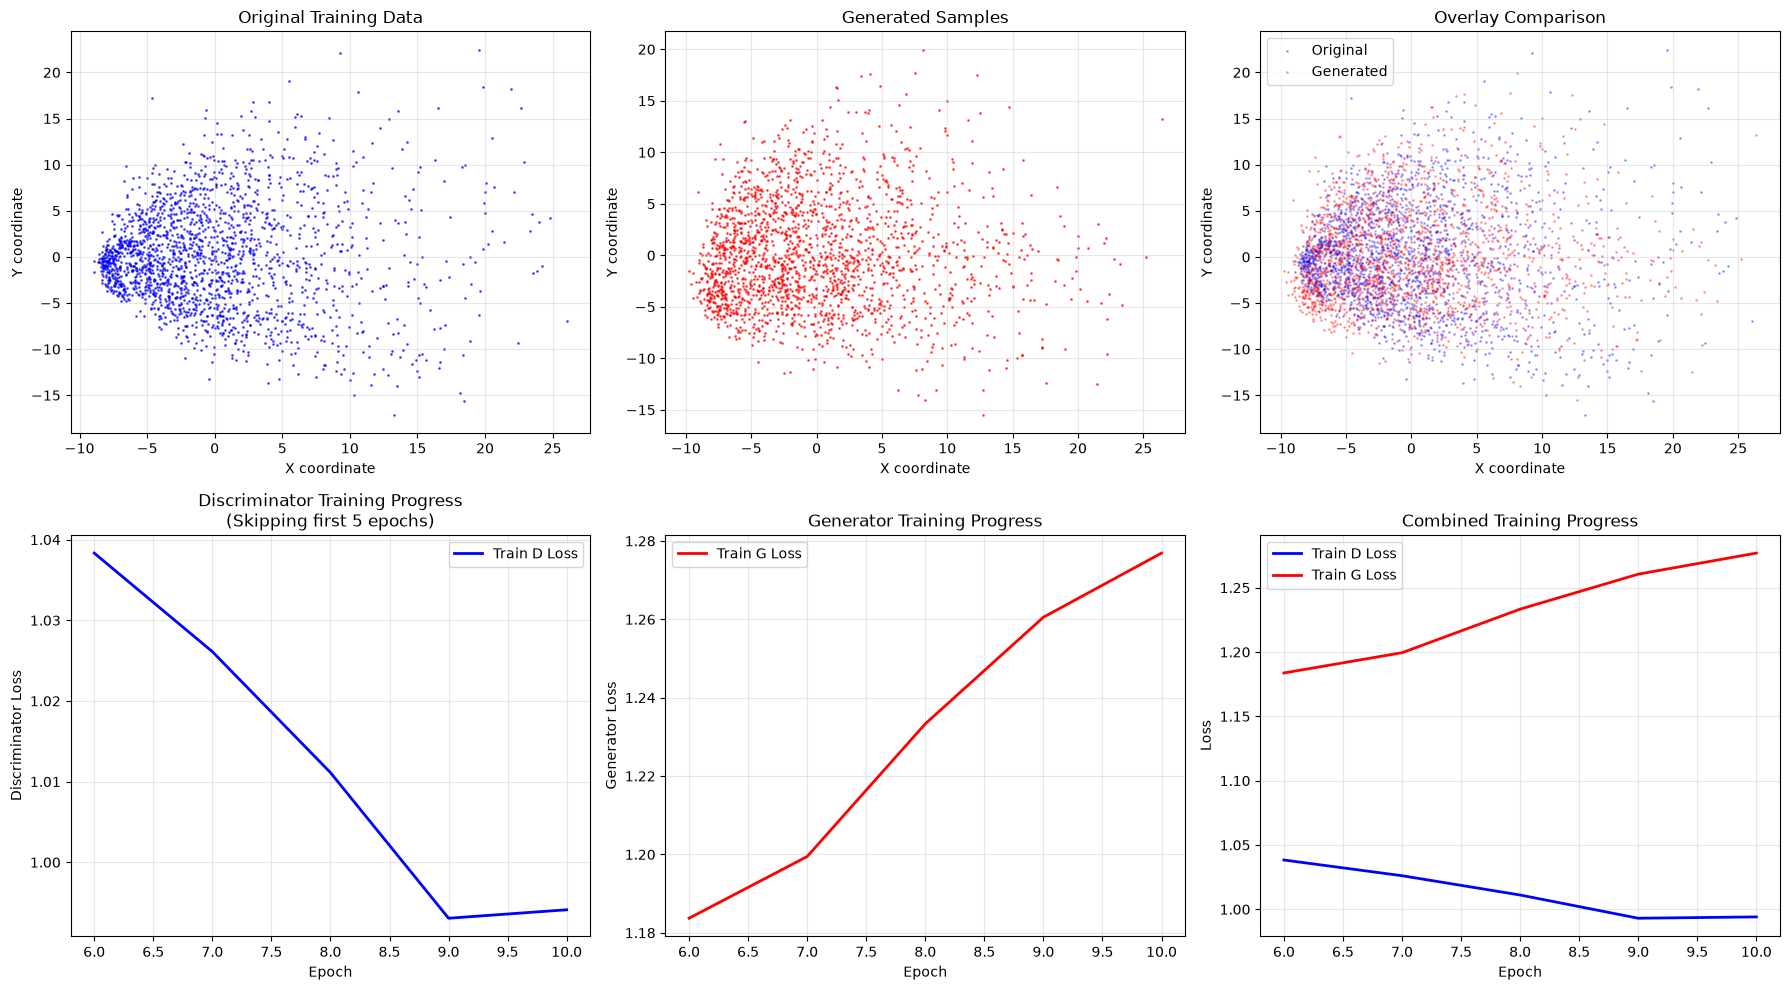

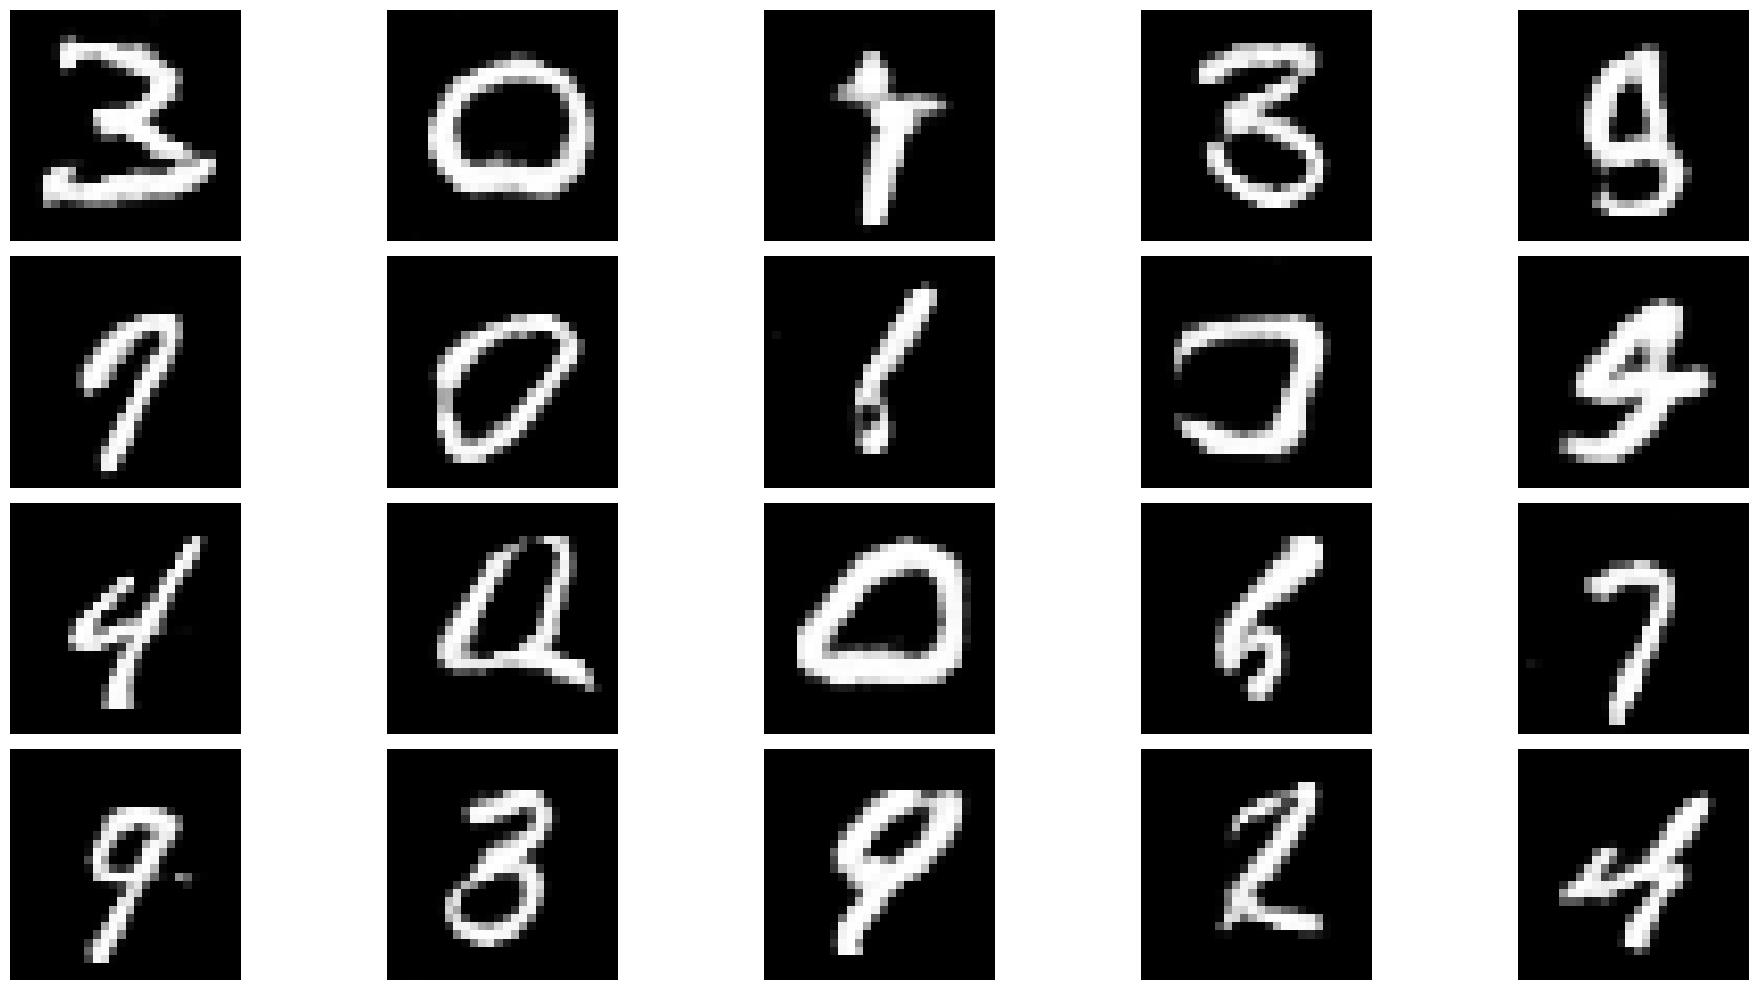

📈 Epoch 10 Summary:
   Train D Loss: 0.9941, Val D Loss: 1.1633
   Train G Loss: 1.2769, Val G Loss: 1.1755

📊 Epoch 11/100
----------------------------------------
Epoch: 11 [0/60000 (0%)]	D_loss: 1.031060	G_loss: 1.393783
Epoch: 11 [6400/60000 (11%)]	D_loss: 1.176173	G_loss: 1.745297
Epoch: 11 [12800/60000 (21%)]	D_loss: 0.908222	G_loss: 1.284063
Epoch: 11 [19200/60000 (32%)]	D_loss: 0.873928	G_loss: 1.246103
Epoch: 11 [25600/60000 (43%)]	D_loss: 0.968186	G_loss: 0.912672
Epoch: 11 [32000/60000 (53%)]	D_loss: 0.959532	G_loss: 0.840619
Epoch: 11 [38400/60000 (64%)]	D_loss: 0.951764	G_loss: 0.789486
Epoch: 11 [44800/60000 (75%)]	D_loss: 0.938142	G_loss: 1.573823
Epoch: 11 [51200/60000 (85%)]	D_loss: 1.011666	G_loss: 1.105354
Epoch: 11 [57600/60000 (96%)]	D_loss: 0.986975	G_loss: 1.713048
====> Epoch: 11 Train D_loss: 0.9714, Train G_loss: 1.2982
====> Epoch: 11 Val D_loss: 1.3799, Val G_loss: 1.9837
📈 Epoch 11 Summary:
   Train D Loss: 0.9714, Val D Loss: 1.3799
   Train G Loss: 1.2982

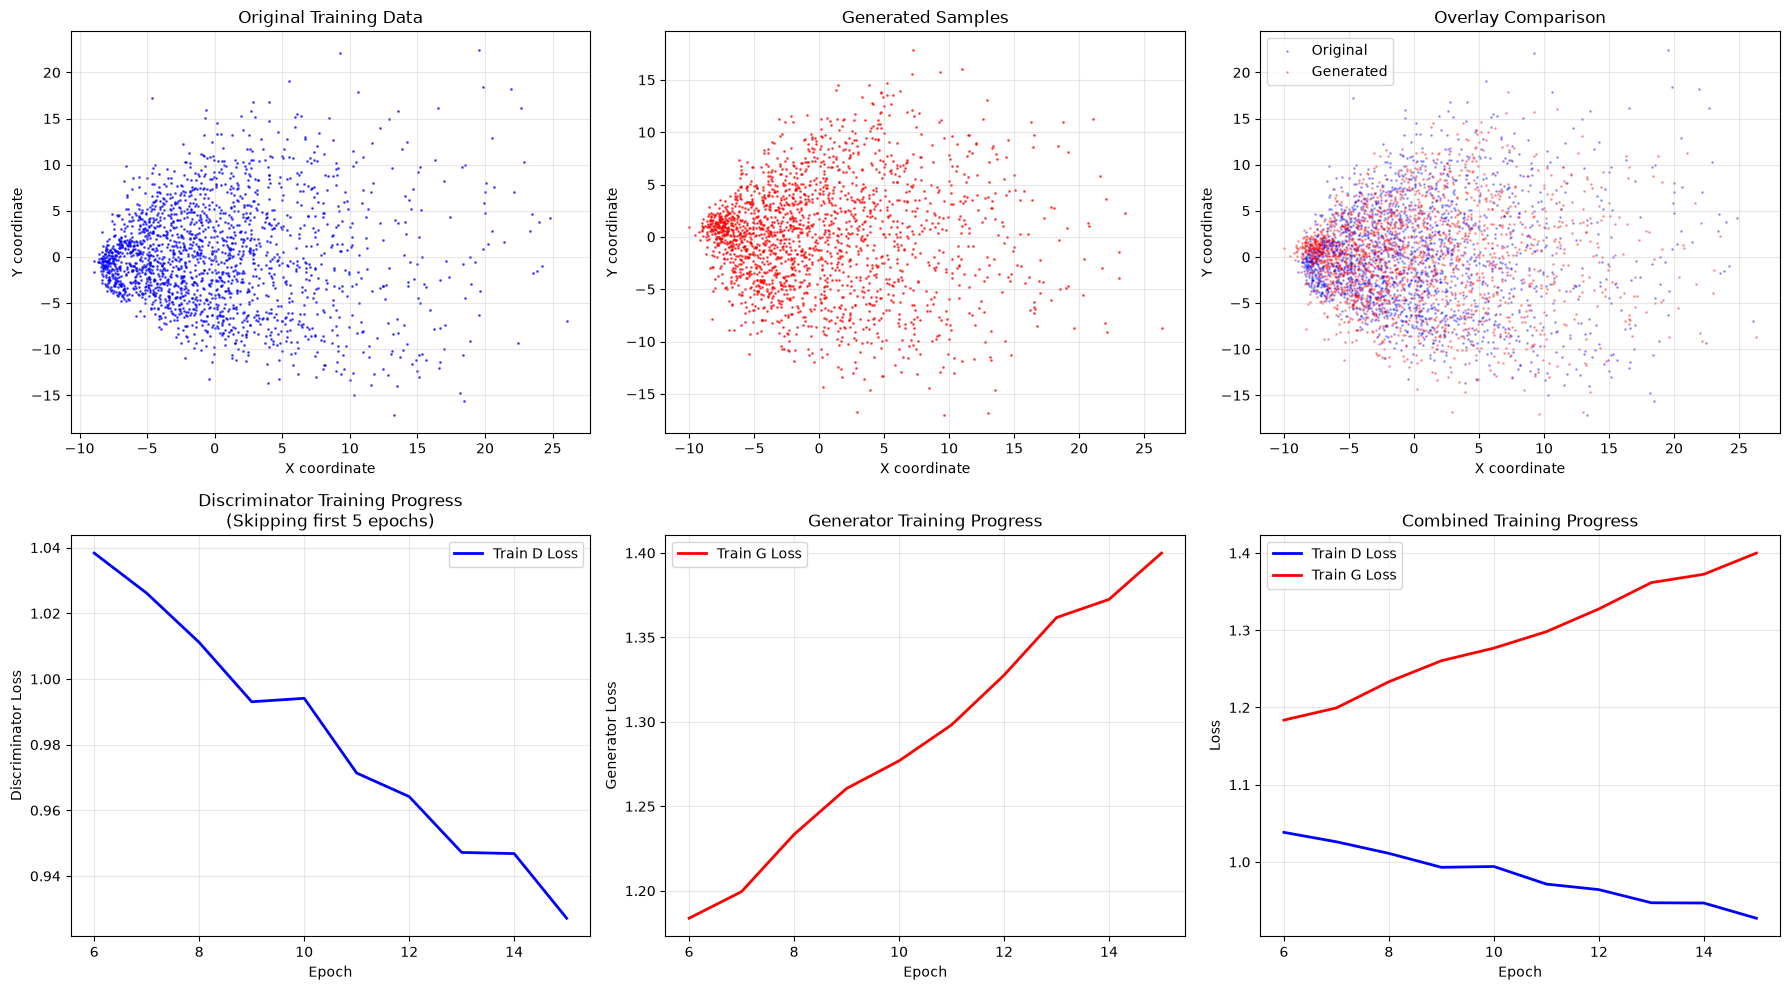

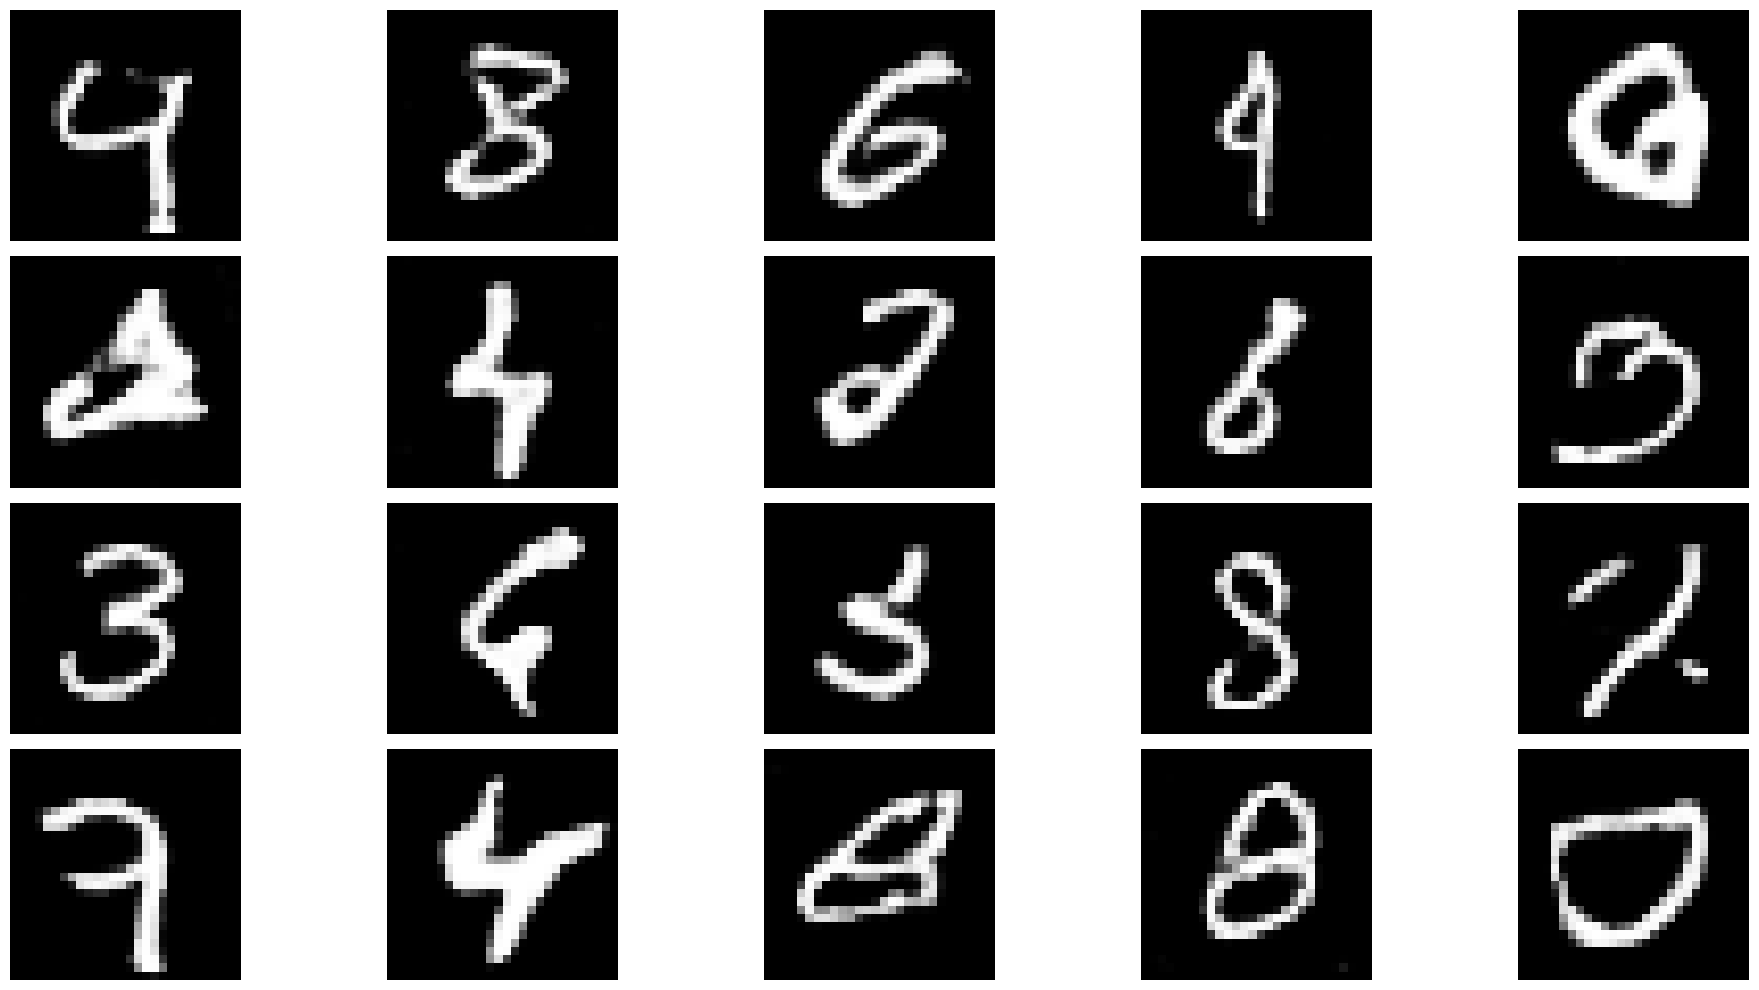

📈 Epoch 15 Summary:
   Train D Loss: 0.9271, Val D Loss: 1.3596
   Train G Loss: 1.3999, Val G Loss: 2.0770

📊 Epoch 16/100
----------------------------------------
Epoch: 16 [0/60000 (0%)]	D_loss: 0.910204	G_loss: 0.683849
Epoch: 16 [6400/60000 (11%)]	D_loss: 0.864690	G_loss: 1.510369
Epoch: 16 [12800/60000 (21%)]	D_loss: 0.958565	G_loss: 1.187180
Epoch: 16 [19200/60000 (32%)]	D_loss: 0.980568	G_loss: 0.786433
Epoch: 16 [25600/60000 (43%)]	D_loss: 0.896013	G_loss: 1.412624
Epoch: 16 [32000/60000 (53%)]	D_loss: 0.873763	G_loss: 1.585344
Epoch: 16 [38400/60000 (64%)]	D_loss: 0.912394	G_loss: 1.651223
Epoch: 16 [44800/60000 (75%)]	D_loss: 1.041329	G_loss: 0.981993
Epoch: 16 [51200/60000 (85%)]	D_loss: 0.961757	G_loss: 0.820536
Epoch: 16 [57600/60000 (96%)]	D_loss: 0.837664	G_loss: 1.320314
====> Epoch: 16 Train D_loss: 0.9385, Train G_loss: 1.3933
====> Epoch: 16 Val D_loss: 1.0950, Val G_loss: 1.1926
📈 Epoch 16 Summary:
   Train D Loss: 0.9385, Val D Loss: 1.0950
   Train G Loss: 1.3933

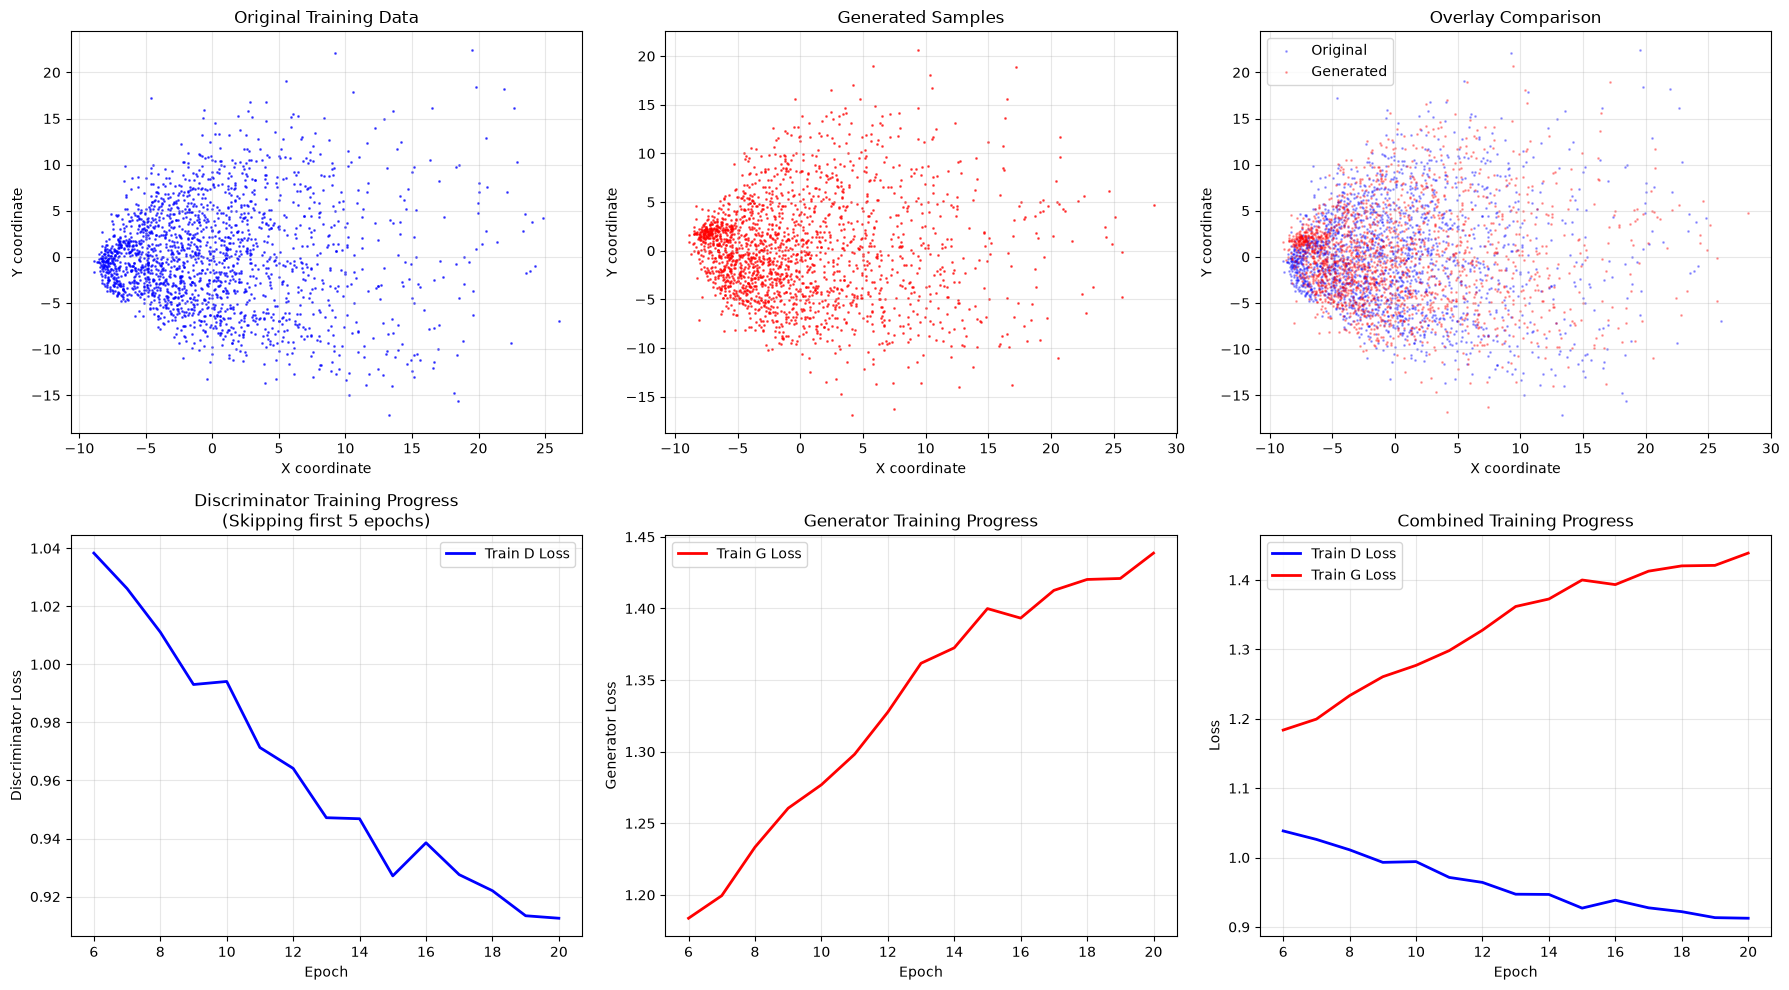

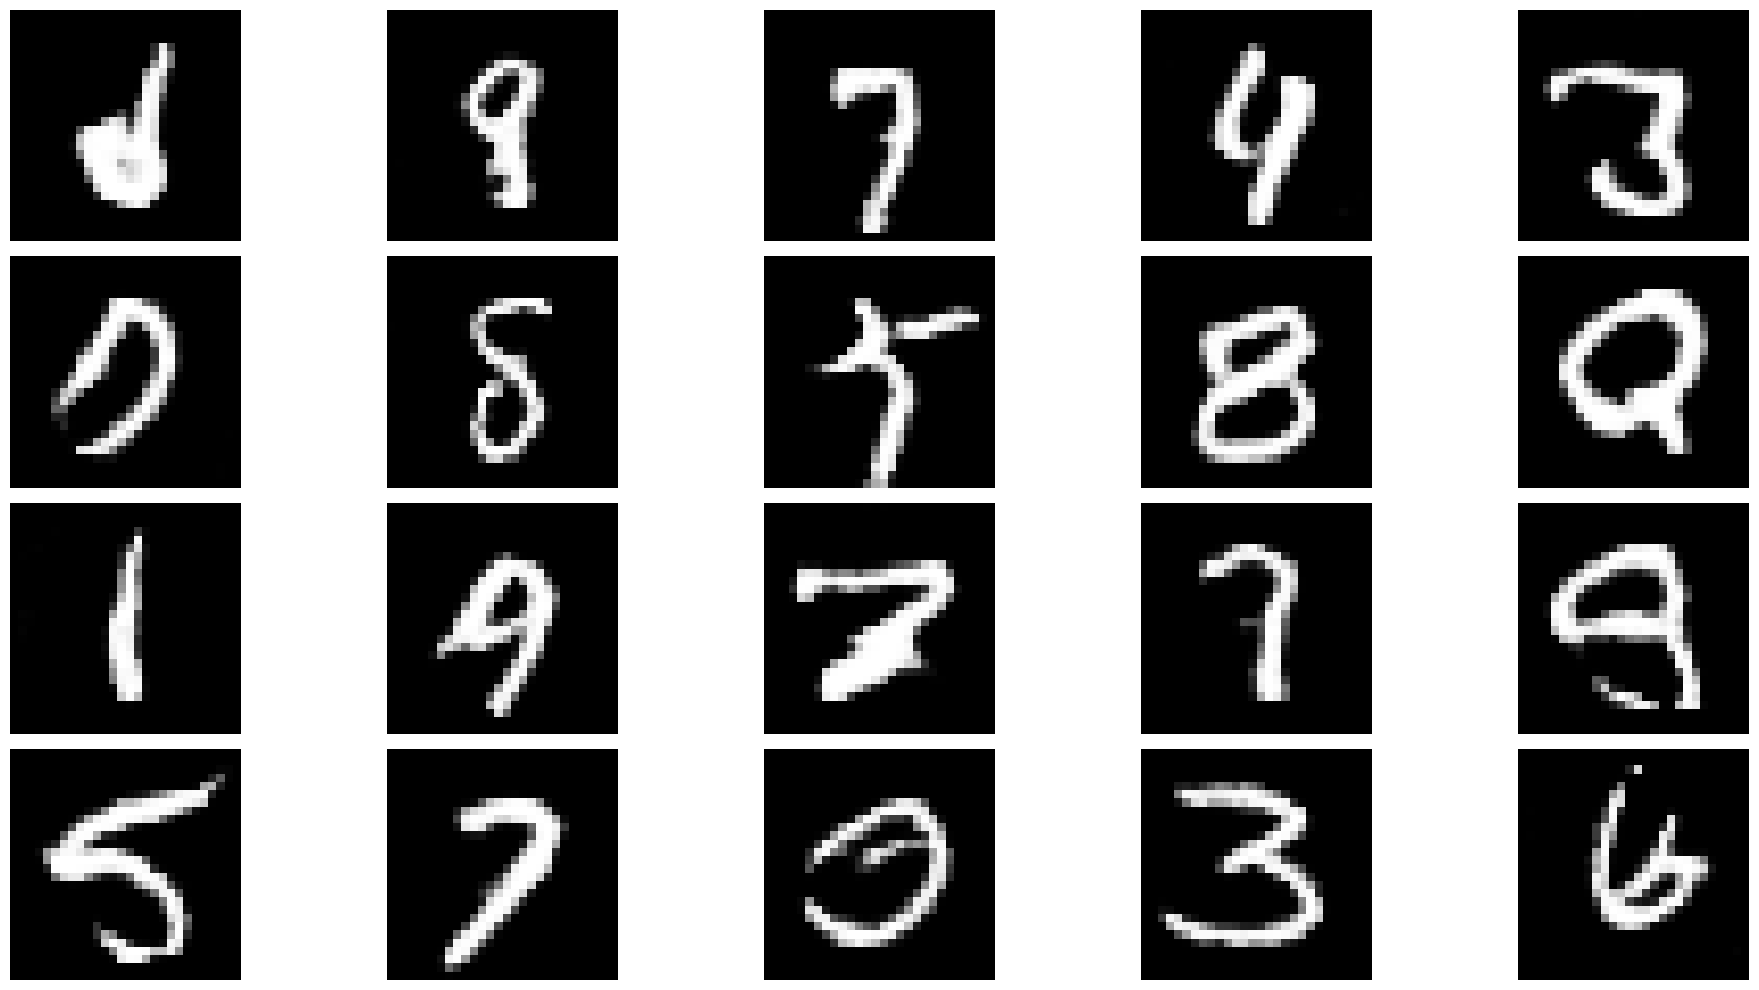

📈 Epoch 20 Summary:
   Train D Loss: 0.9125, Val D Loss: 1.1092
   Train G Loss: 1.4387, Val G Loss: 1.5552

📊 Epoch 21/100
----------------------------------------
Epoch: 21 [0/60000 (0%)]	D_loss: 0.738144	G_loss: 1.568696
Epoch: 21 [6400/60000 (11%)]	D_loss: 0.855764	G_loss: 1.362095
Epoch: 21 [12800/60000 (21%)]	D_loss: 0.773605	G_loss: 1.349869
Epoch: 21 [19200/60000 (32%)]	D_loss: 0.968502	G_loss: 1.428797
Epoch: 21 [25600/60000 (43%)]	D_loss: 0.932203	G_loss: 0.927667
Epoch: 21 [32000/60000 (53%)]	D_loss: 1.279042	G_loss: 0.349226
Epoch: 21 [38400/60000 (64%)]	D_loss: 0.811768	G_loss: 1.748029
Epoch: 21 [44800/60000 (75%)]	D_loss: 1.140438	G_loss: 2.765452
Epoch: 21 [51200/60000 (85%)]	D_loss: 0.920960	G_loss: 1.403894
Epoch: 21 [57600/60000 (96%)]	D_loss: 0.935078	G_loss: 1.490334
====> Epoch: 21 Train D_loss: 0.9129, Train G_loss: 1.4500
====> Epoch: 21 Val D_loss: 1.1457, Val G_loss: 0.8221
📈 Epoch 21 Summary:
   Train D Loss: 0.9129, Val D Loss: 1.1457
   Train G Loss: 1.4500

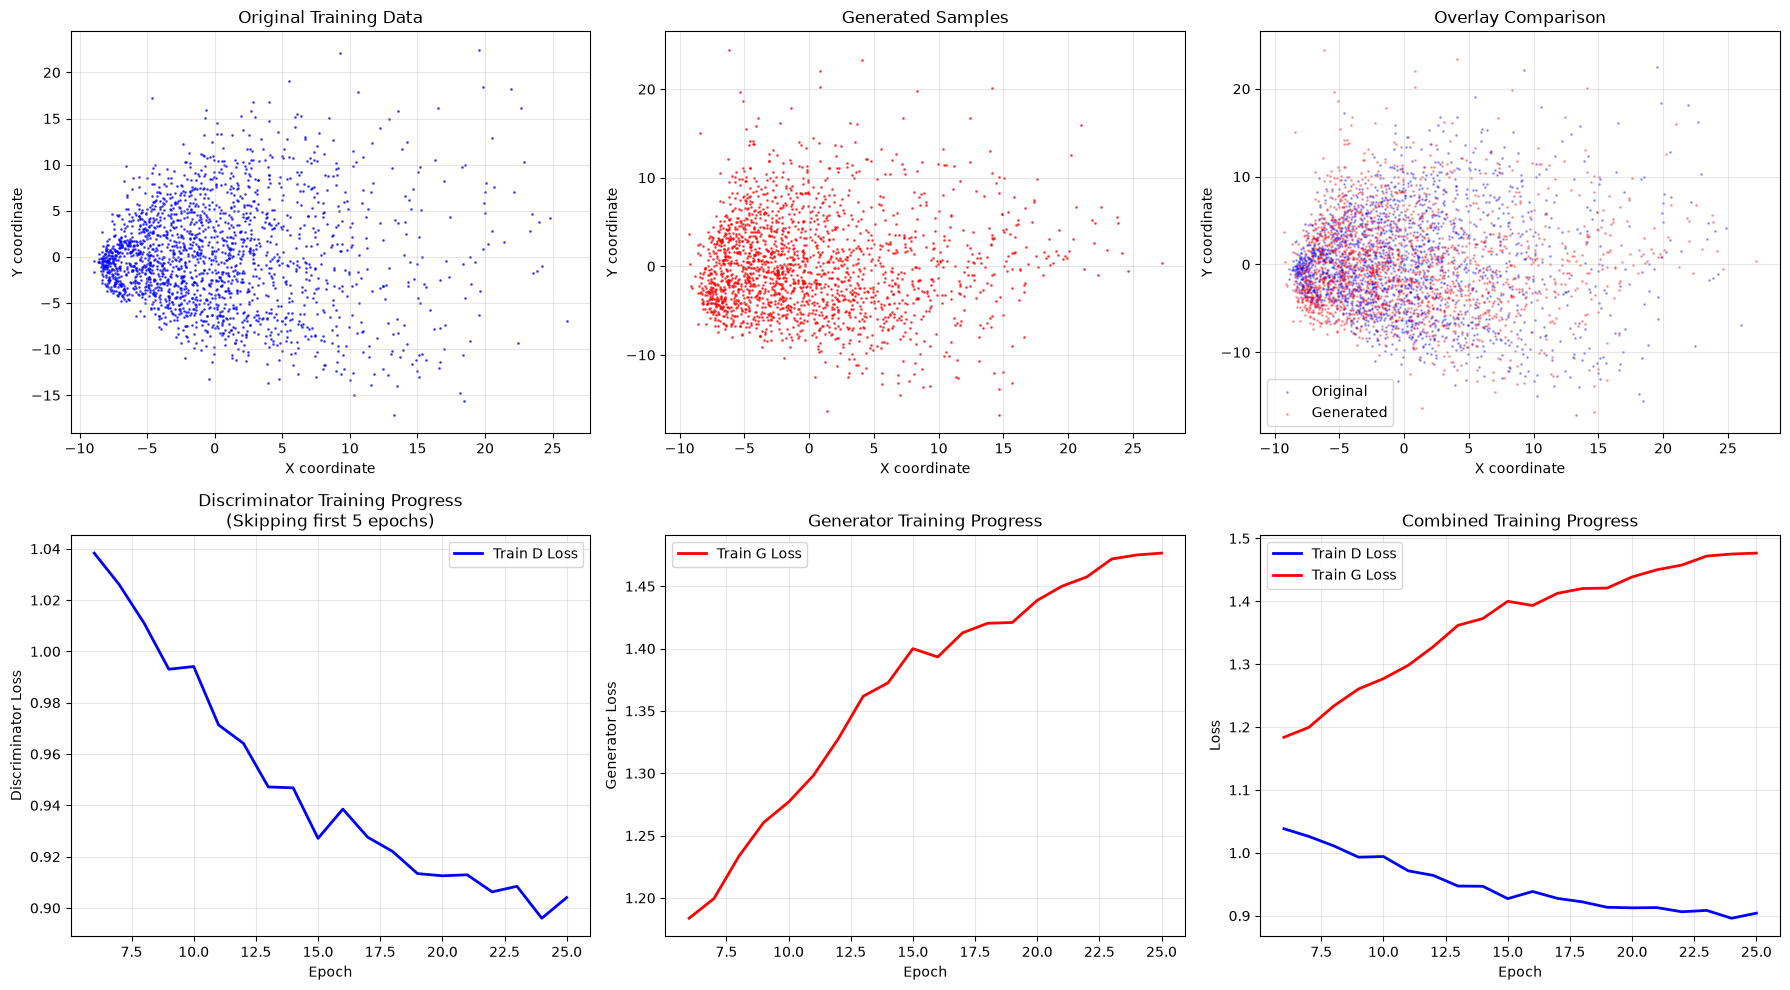

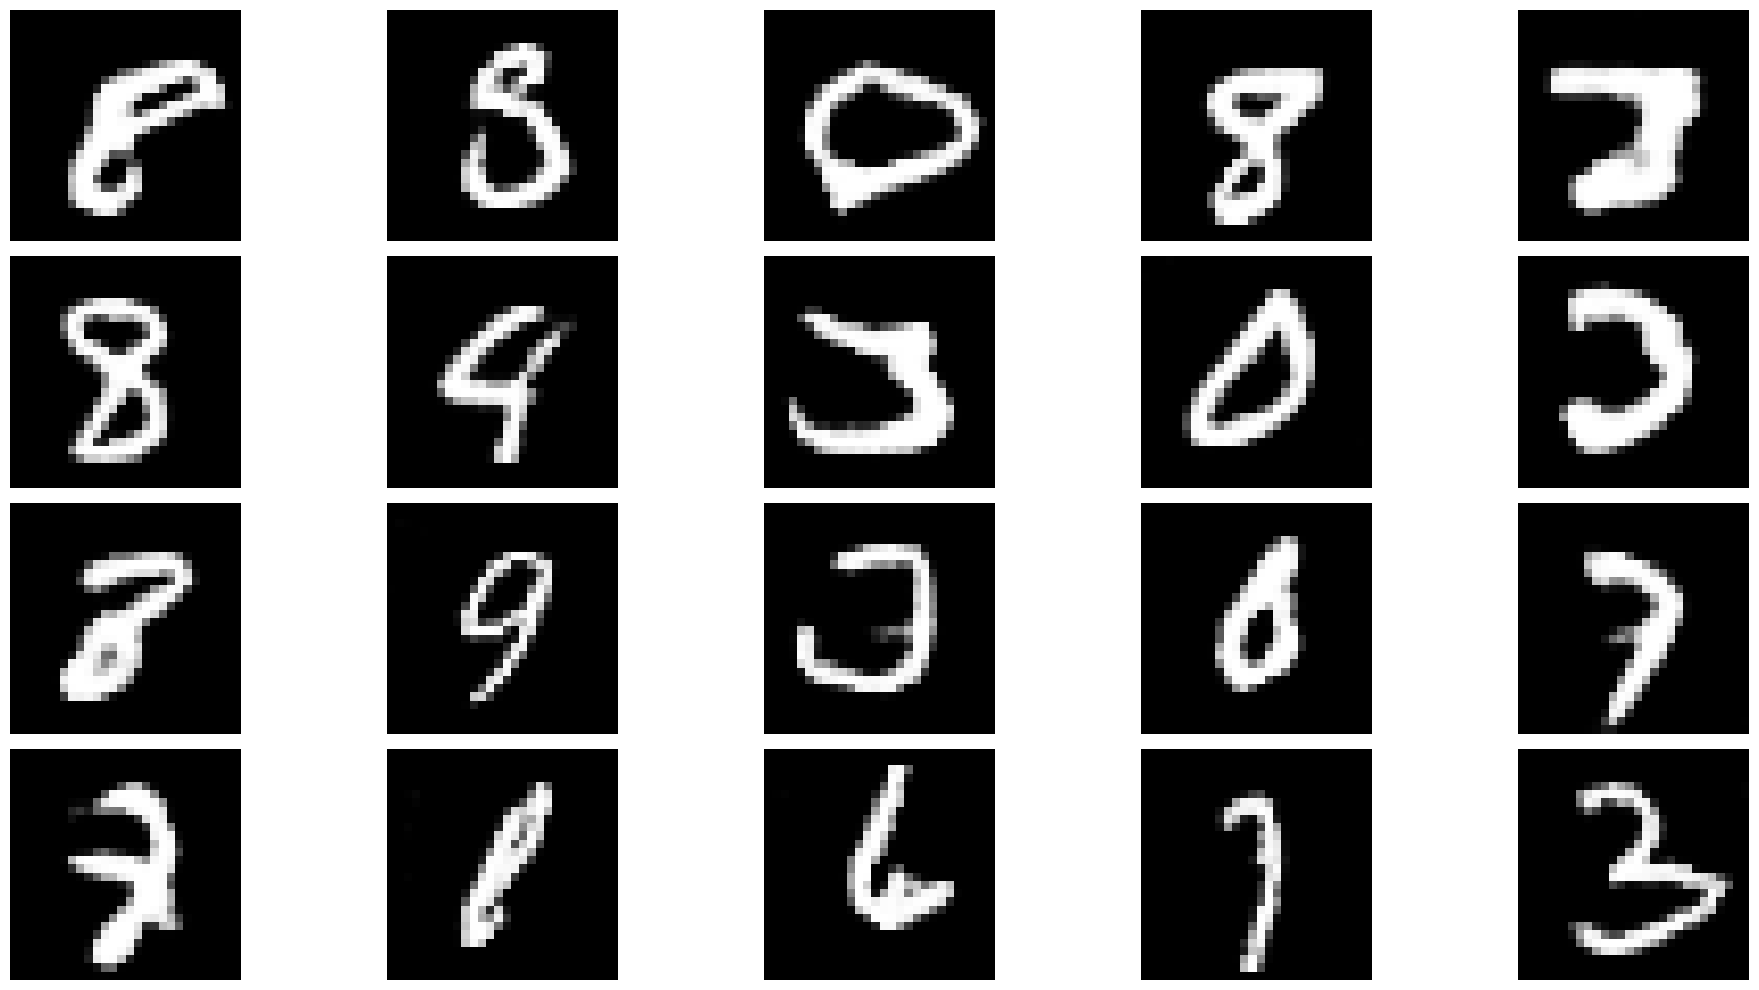

📈 Epoch 25 Summary:
   Train D Loss: 0.9041, Val D Loss: 1.3811
   Train G Loss: 1.4766, Val G Loss: 2.0297

📊 Epoch 26/100
----------------------------------------
Epoch: 26 [0/60000 (0%)]	D_loss: 0.919324	G_loss: 1.109869
Epoch: 26 [6400/60000 (11%)]	D_loss: 0.826196	G_loss: 1.413759
Epoch: 26 [12800/60000 (21%)]	D_loss: 0.836344	G_loss: 0.892440
Epoch: 26 [19200/60000 (32%)]	D_loss: 0.826370	G_loss: 0.913617
Epoch: 26 [25600/60000 (43%)]	D_loss: 1.079703	G_loss: 0.793788
Epoch: 26 [32000/60000 (53%)]	D_loss: 0.958676	G_loss: 1.237390
Epoch: 26 [38400/60000 (64%)]	D_loss: 0.922107	G_loss: 1.496447
Epoch: 26 [44800/60000 (75%)]	D_loss: 0.756583	G_loss: 1.294602
Epoch: 26 [51200/60000 (85%)]	D_loss: 0.744045	G_loss: 1.635590
Epoch: 26 [57600/60000 (96%)]	D_loss: 0.783623	G_loss: 1.575581
====> Epoch: 26 Train D_loss: 0.9004, Train G_loss: 1.4926
====> Epoch: 26 Val D_loss: 1.3937, Val G_loss: 0.6029
📈 Epoch 26 Summary:
   Train D Loss: 0.9004, Val D Loss: 1.3937
   Train G Loss: 1.4926

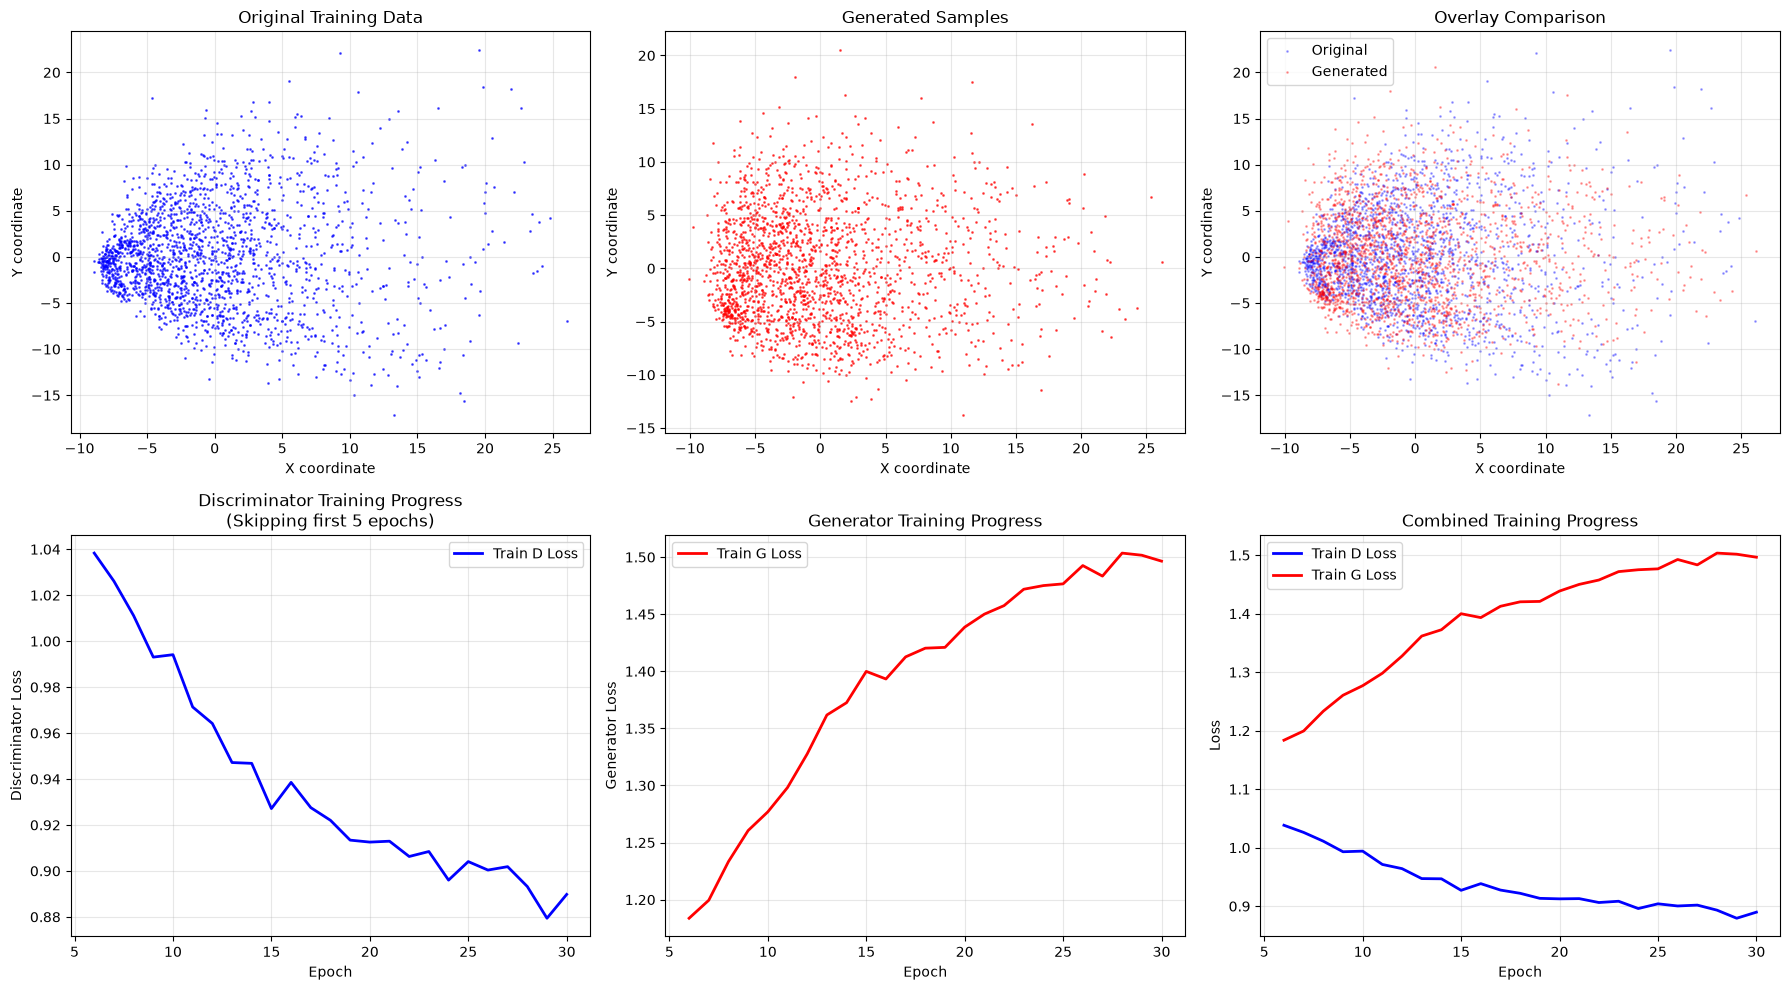

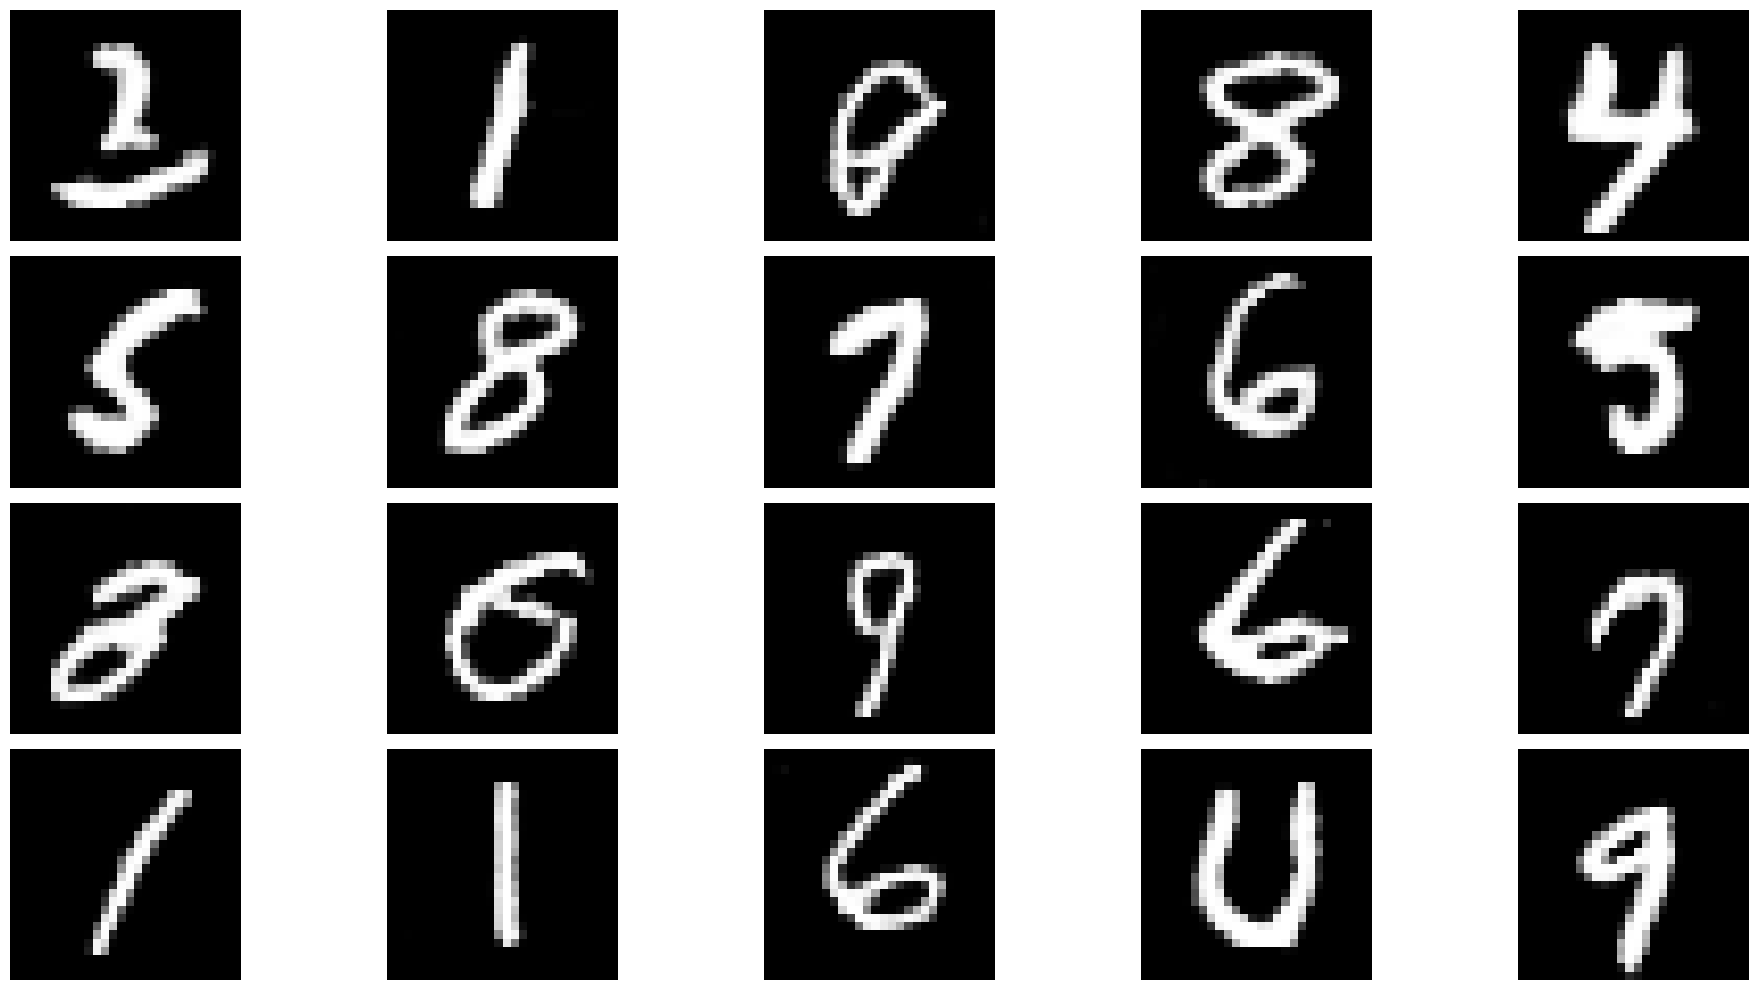

📈 Epoch 30 Summary:
   Train D Loss: 0.8898, Val D Loss: 1.0770
   Train G Loss: 1.4965, Val G Loss: 1.0886

📊 Epoch 31/100
----------------------------------------
Epoch: 31 [0/60000 (0%)]	D_loss: 0.736305	G_loss: 2.120814
Epoch: 31 [6400/60000 (11%)]	D_loss: 1.205006	G_loss: 2.208138
Epoch: 31 [12800/60000 (21%)]	D_loss: 0.846864	G_loss: 1.017077
Epoch: 31 [19200/60000 (32%)]	D_loss: 0.767511	G_loss: 1.246145
Epoch: 31 [25600/60000 (43%)]	D_loss: 0.848153	G_loss: 1.407426
Epoch: 31 [32000/60000 (53%)]	D_loss: 0.918767	G_loss: 1.725031
Epoch: 31 [38400/60000 (64%)]	D_loss: 0.950325	G_loss: 2.992069
Epoch: 31 [44800/60000 (75%)]	D_loss: 0.884033	G_loss: 1.870444
Epoch: 31 [51200/60000 (85%)]	D_loss: 0.729513	G_loss: 1.545569
Epoch: 31 [57600/60000 (96%)]	D_loss: 0.884722	G_loss: 2.231340
====> Epoch: 31 Train D_loss: 0.8877, Train G_loss: 1.5133
====> Epoch: 31 Val D_loss: 1.1719, Val G_loss: 1.7430
📈 Epoch 31 Summary:
   Train D Loss: 0.8877, Val D Loss: 1.1719
   Train G Loss: 1.5133

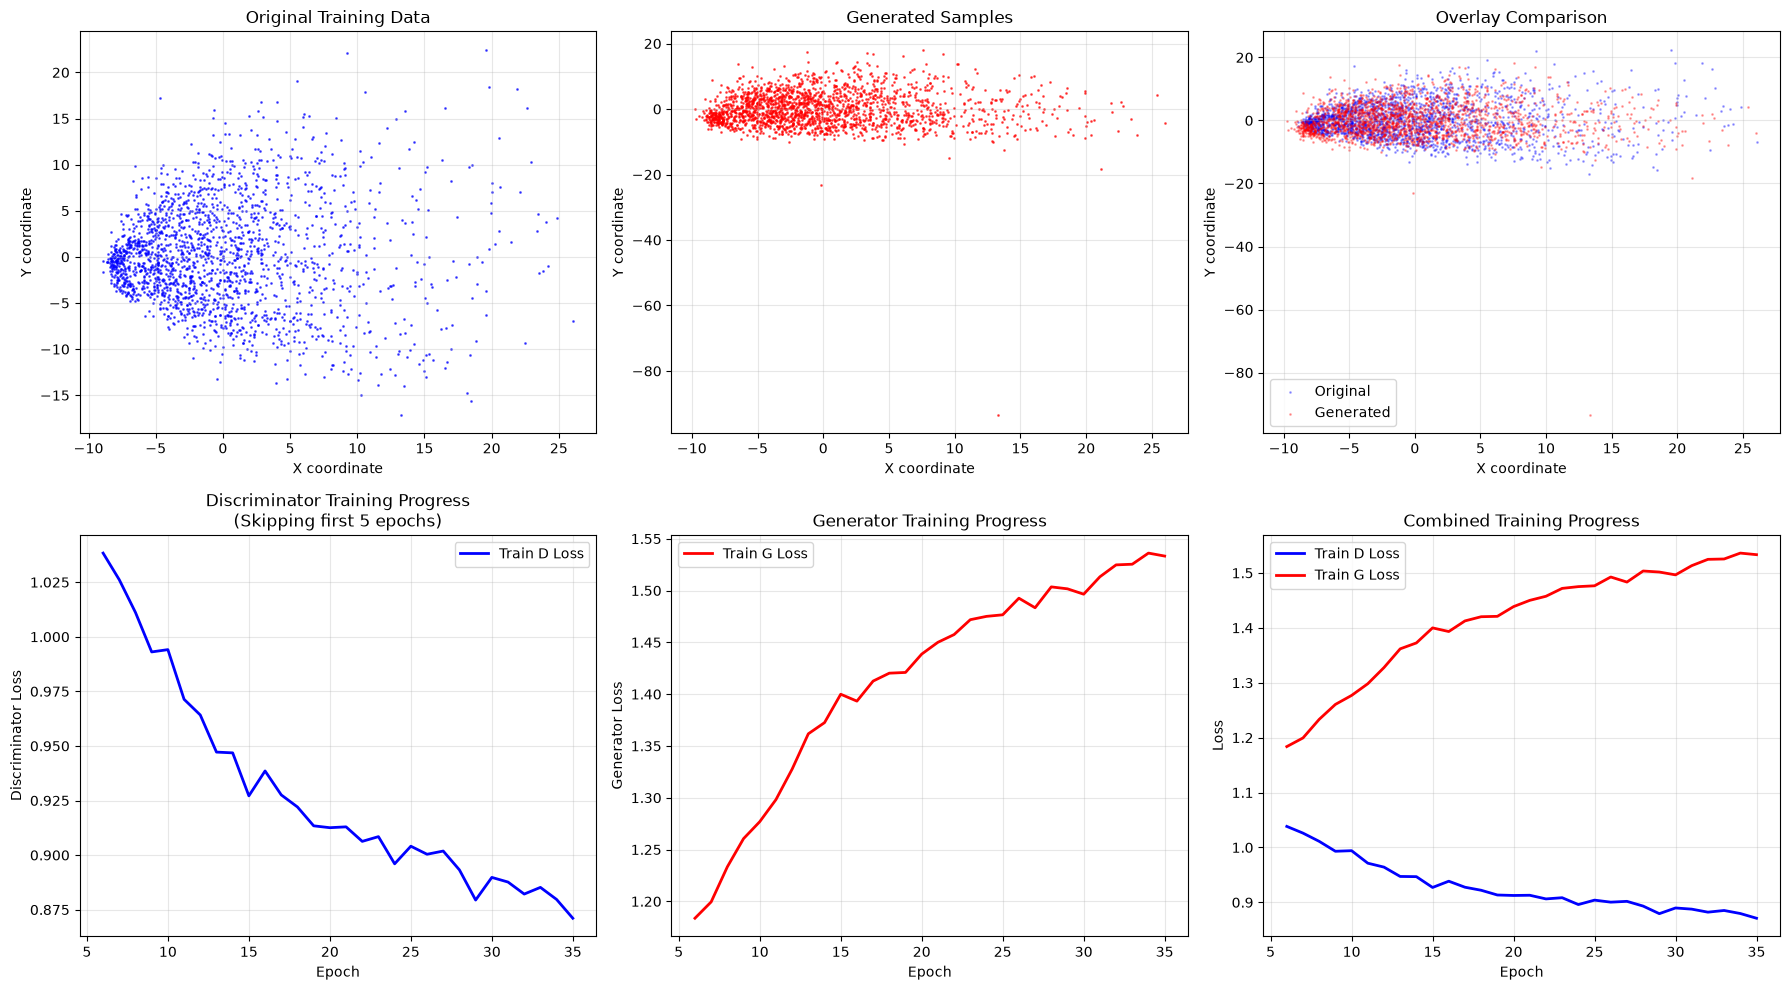

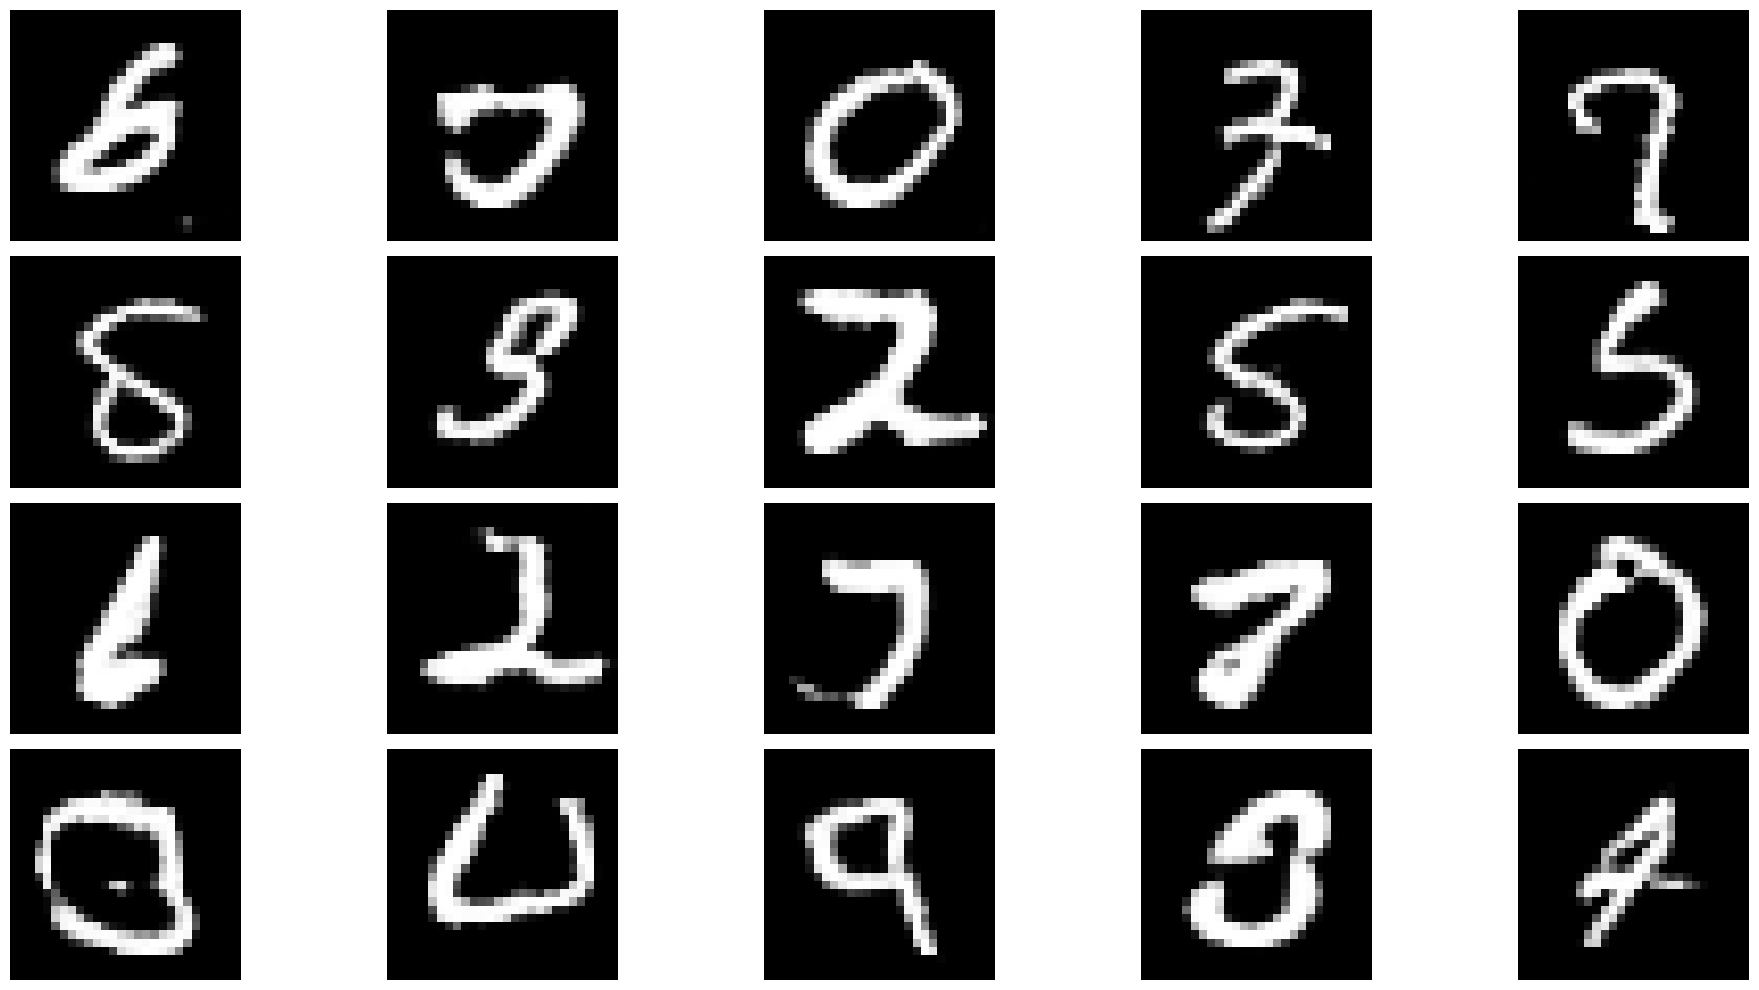

📈 Epoch 35 Summary:
   Train D Loss: 0.8711, Val D Loss: 1.2951
   Train G Loss: 1.5333, Val G Loss: 1.9264

📊 Epoch 36/100
----------------------------------------
Epoch: 36 [0/60000 (0%)]	D_loss: 0.899479	G_loss: 1.087695
Epoch: 36 [6400/60000 (11%)]	D_loss: 0.740498	G_loss: 1.475759
Epoch: 36 [12800/60000 (21%)]	D_loss: 0.851341	G_loss: 1.103470
Epoch: 36 [19200/60000 (32%)]	D_loss: 0.734055	G_loss: 1.512564
Epoch: 36 [25600/60000 (43%)]	D_loss: 0.853934	G_loss: 1.356726
Epoch: 36 [32000/60000 (53%)]	D_loss: 0.782386	G_loss: 1.259455
Epoch: 36 [38400/60000 (64%)]	D_loss: 0.669356	G_loss: 1.791581
Epoch: 36 [44800/60000 (75%)]	D_loss: 0.812235	G_loss: 1.575388
Epoch: 36 [51200/60000 (85%)]	D_loss: 0.837941	G_loss: 1.733680
Epoch: 36 [57600/60000 (96%)]	D_loss: 0.691350	G_loss: 1.824481
====> Epoch: 36 Train D_loss: 0.8758, Train G_loss: 1.5476
====> Epoch: 36 Val D_loss: 1.4636, Val G_loss: 2.2587
📈 Epoch 36 Summary:
   Train D Loss: 0.8758, Val D Loss: 1.4636
   Train G Loss: 1.5476

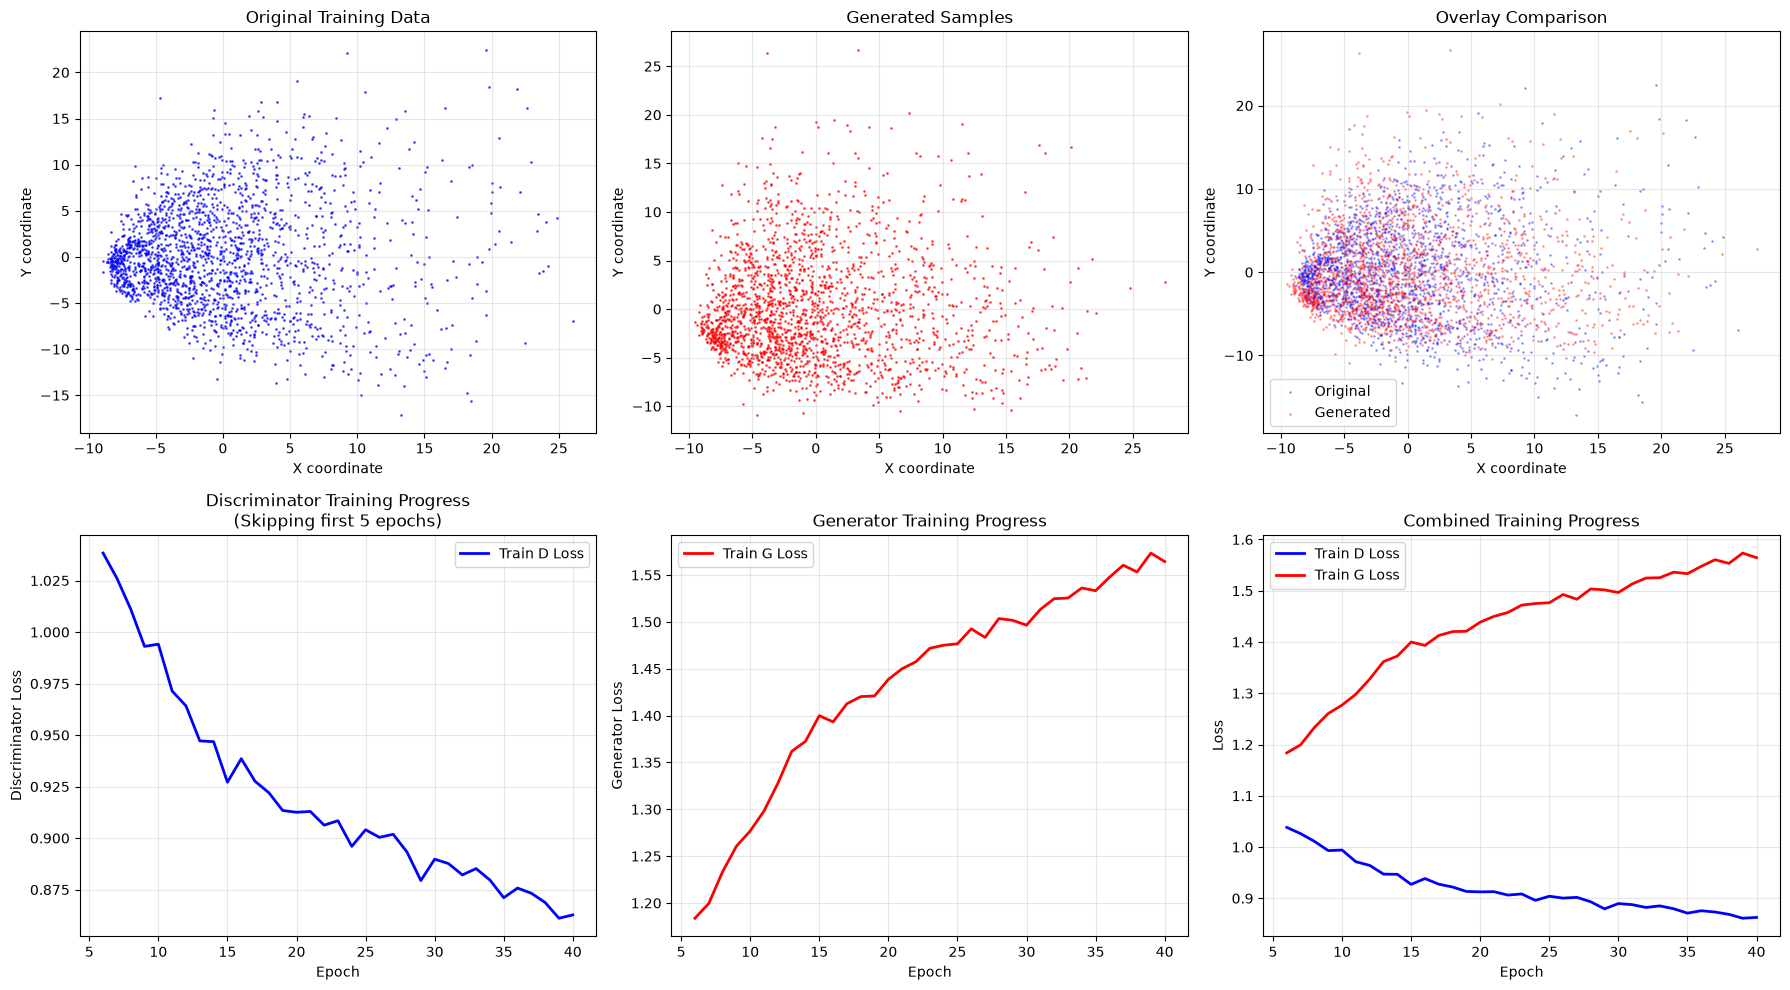

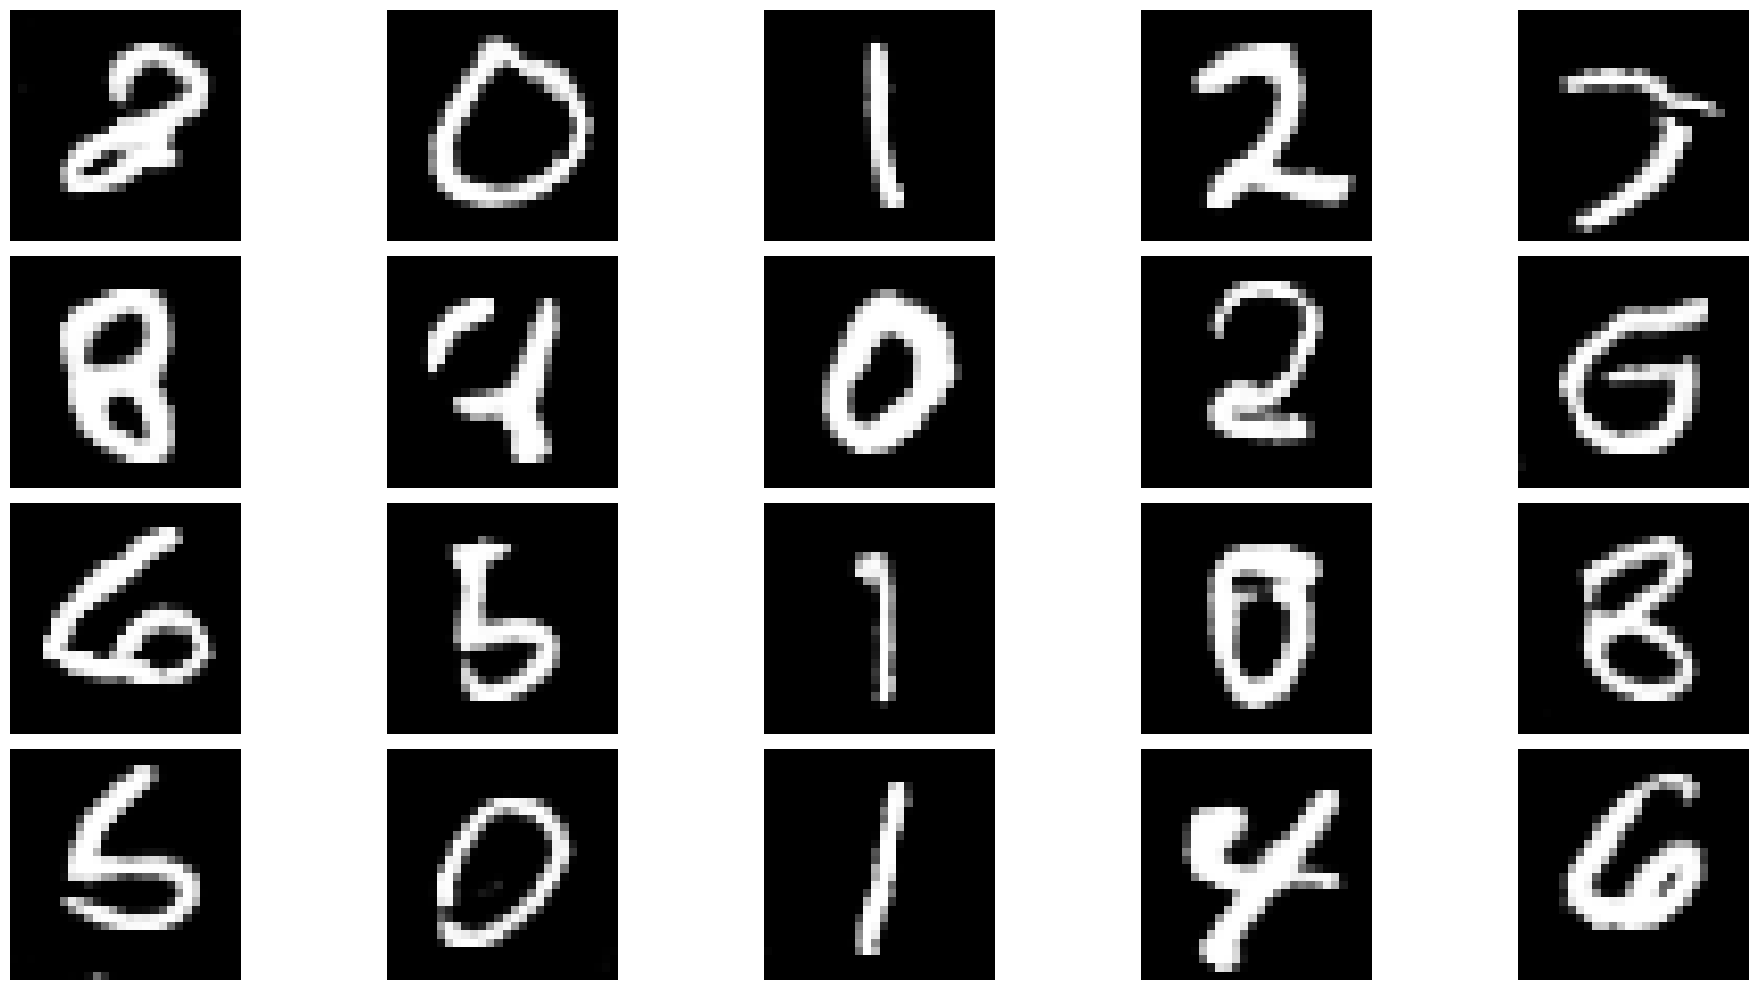

📈 Epoch 40 Summary:
   Train D Loss: 0.8627, Val D Loss: 1.1799
   Train G Loss: 1.5644, Val G Loss: 1.5830

📊 Epoch 41/100
----------------------------------------
Epoch: 41 [0/60000 (0%)]	D_loss: 0.844858	G_loss: 1.679102
Epoch: 41 [6400/60000 (11%)]	D_loss: 0.862351	G_loss: 1.555682
Epoch: 41 [12800/60000 (21%)]	D_loss: 0.745066	G_loss: 1.992988
Epoch: 41 [19200/60000 (32%)]	D_loss: 0.885267	G_loss: 1.528237
Epoch: 41 [25600/60000 (43%)]	D_loss: 0.791461	G_loss: 1.683605
Epoch: 41 [32000/60000 (53%)]	D_loss: 0.824246	G_loss: 1.798690
Epoch: 41 [38400/60000 (64%)]	D_loss: 0.979262	G_loss: 1.497605
Epoch: 41 [44800/60000 (75%)]	D_loss: 0.914801	G_loss: 1.522387
Epoch: 41 [51200/60000 (85%)]	D_loss: 0.808069	G_loss: 1.356969
Epoch: 41 [57600/60000 (96%)]	D_loss: 0.851427	G_loss: 2.428420
====> Epoch: 41 Train D_loss: 0.8640, Train G_loss: 1.5758
====> Epoch: 41 Val D_loss: 1.4055, Val G_loss: 0.5633
📈 Epoch 41 Summary:
   Train D Loss: 0.8640, Val D Loss: 1.4055
   Train G Loss: 1.5758

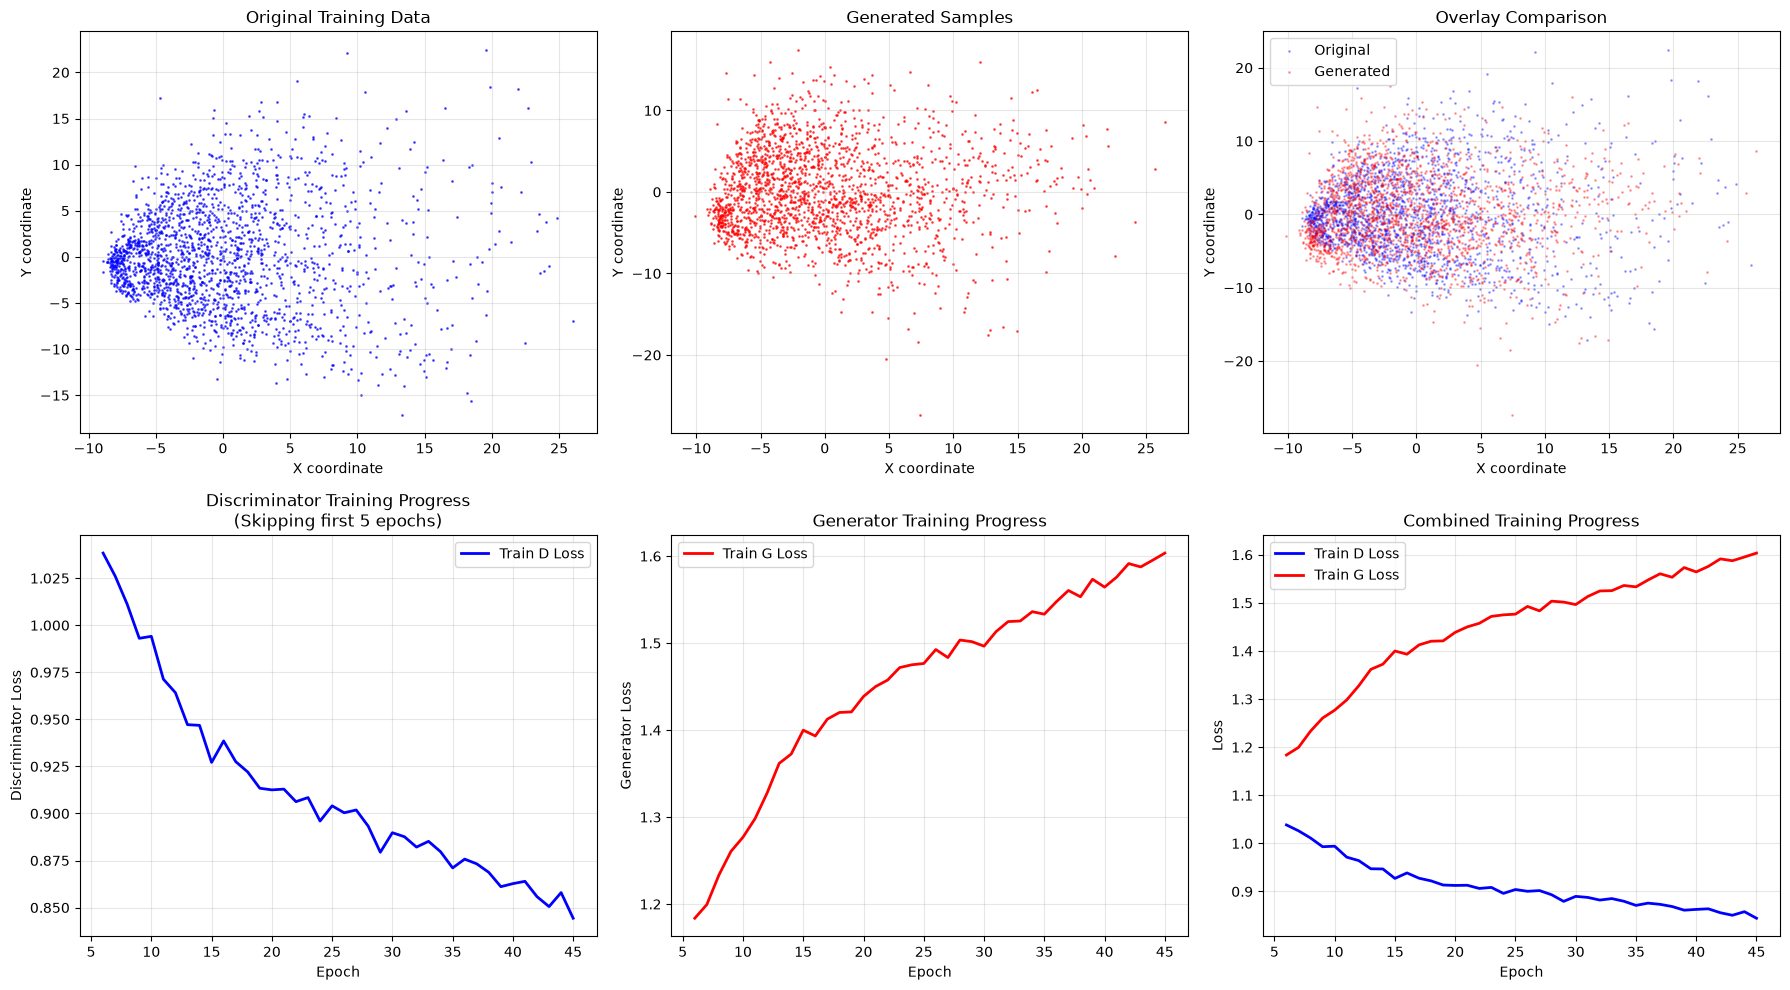

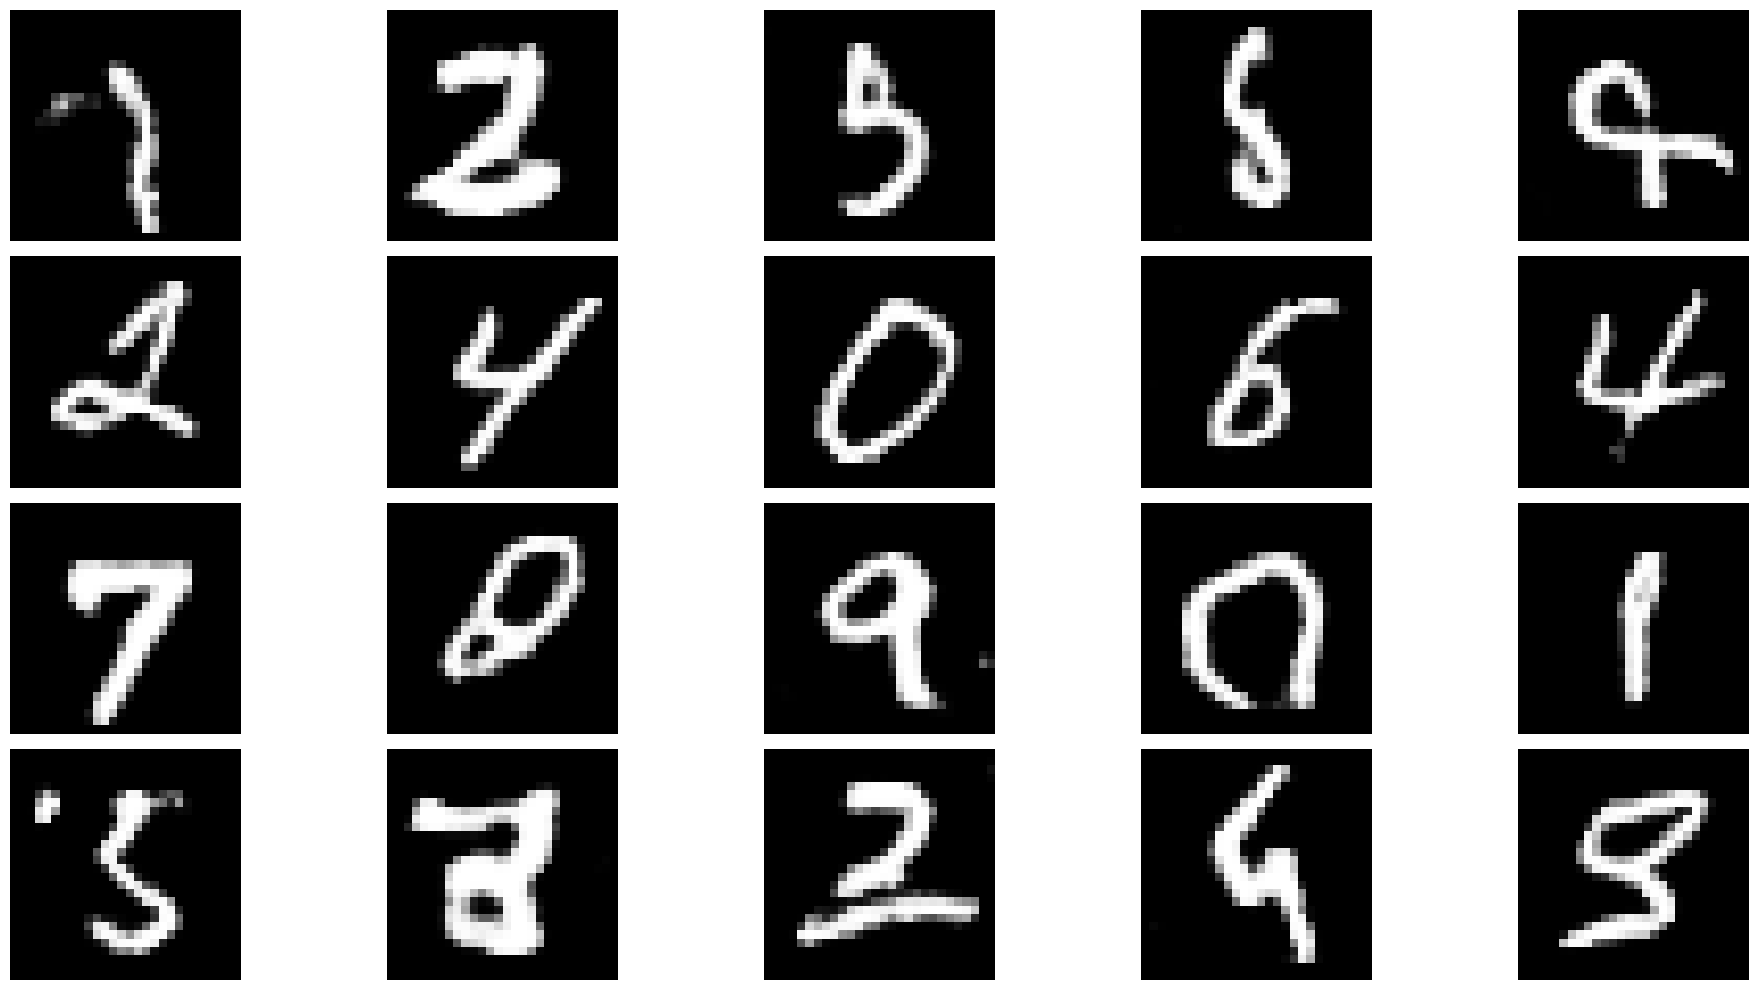

📈 Epoch 45 Summary:
   Train D Loss: 0.8443, Val D Loss: 1.0876
   Train G Loss: 1.6035, Val G Loss: 1.3491

📊 Epoch 46/100
----------------------------------------
Epoch: 46 [0/60000 (0%)]	D_loss: 0.790475	G_loss: 1.230229
Epoch: 46 [6400/60000 (11%)]	D_loss: 0.810744	G_loss: 2.195537
Epoch: 46 [12800/60000 (21%)]	D_loss: 0.955683	G_loss: 0.709670
Epoch: 46 [19200/60000 (32%)]	D_loss: 0.750922	G_loss: 1.565875
Epoch: 46 [25600/60000 (43%)]	D_loss: 1.011630	G_loss: 2.433900
Epoch: 46 [32000/60000 (53%)]	D_loss: 0.794253	G_loss: 1.375898
Epoch: 46 [38400/60000 (64%)]	D_loss: 1.095425	G_loss: 3.425537
Epoch: 46 [44800/60000 (75%)]	D_loss: 0.778133	G_loss: 1.965754
Epoch: 46 [51200/60000 (85%)]	D_loss: 0.884173	G_loss: 2.500757
Epoch: 46 [57600/60000 (96%)]	D_loss: 0.967789	G_loss: 2.111193
====> Epoch: 46 Train D_loss: 0.8628, Train G_loss: 1.6134
====> Epoch: 46 Val D_loss: 1.1114, Val G_loss: 1.1031
📈 Epoch 46 Summary:
   Train D Loss: 0.8628, Val D Loss: 1.1114
   Train G Loss: 1.6134

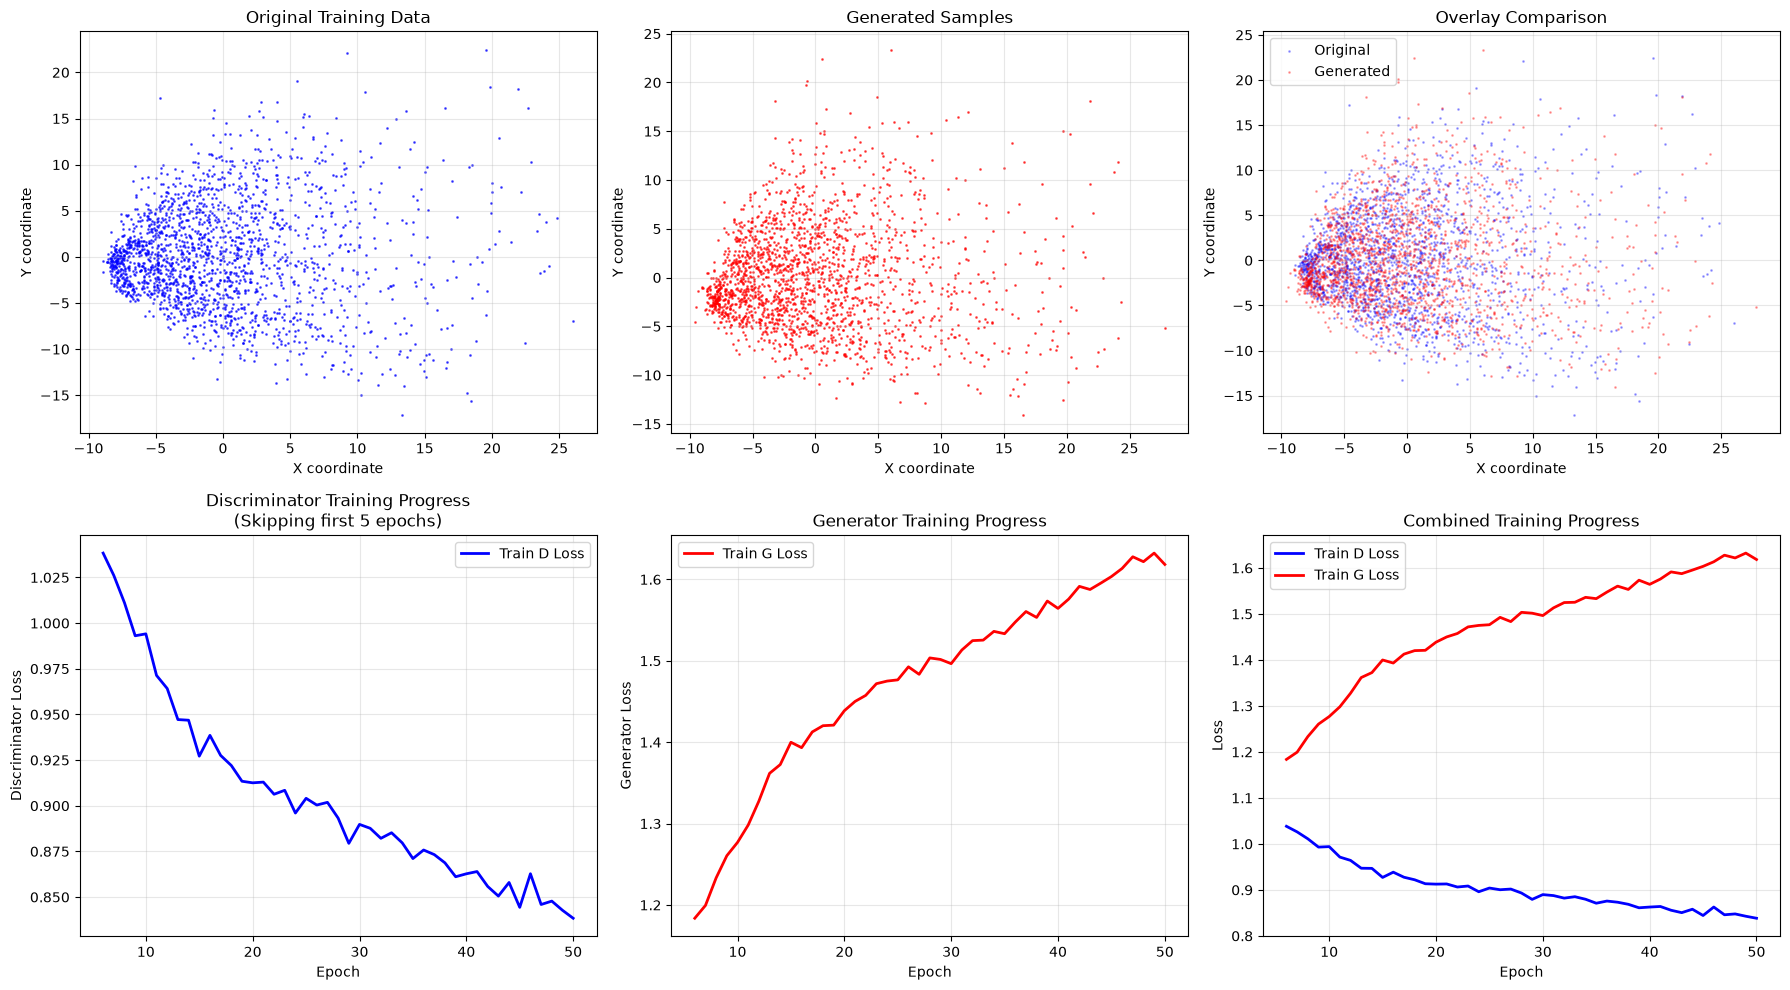

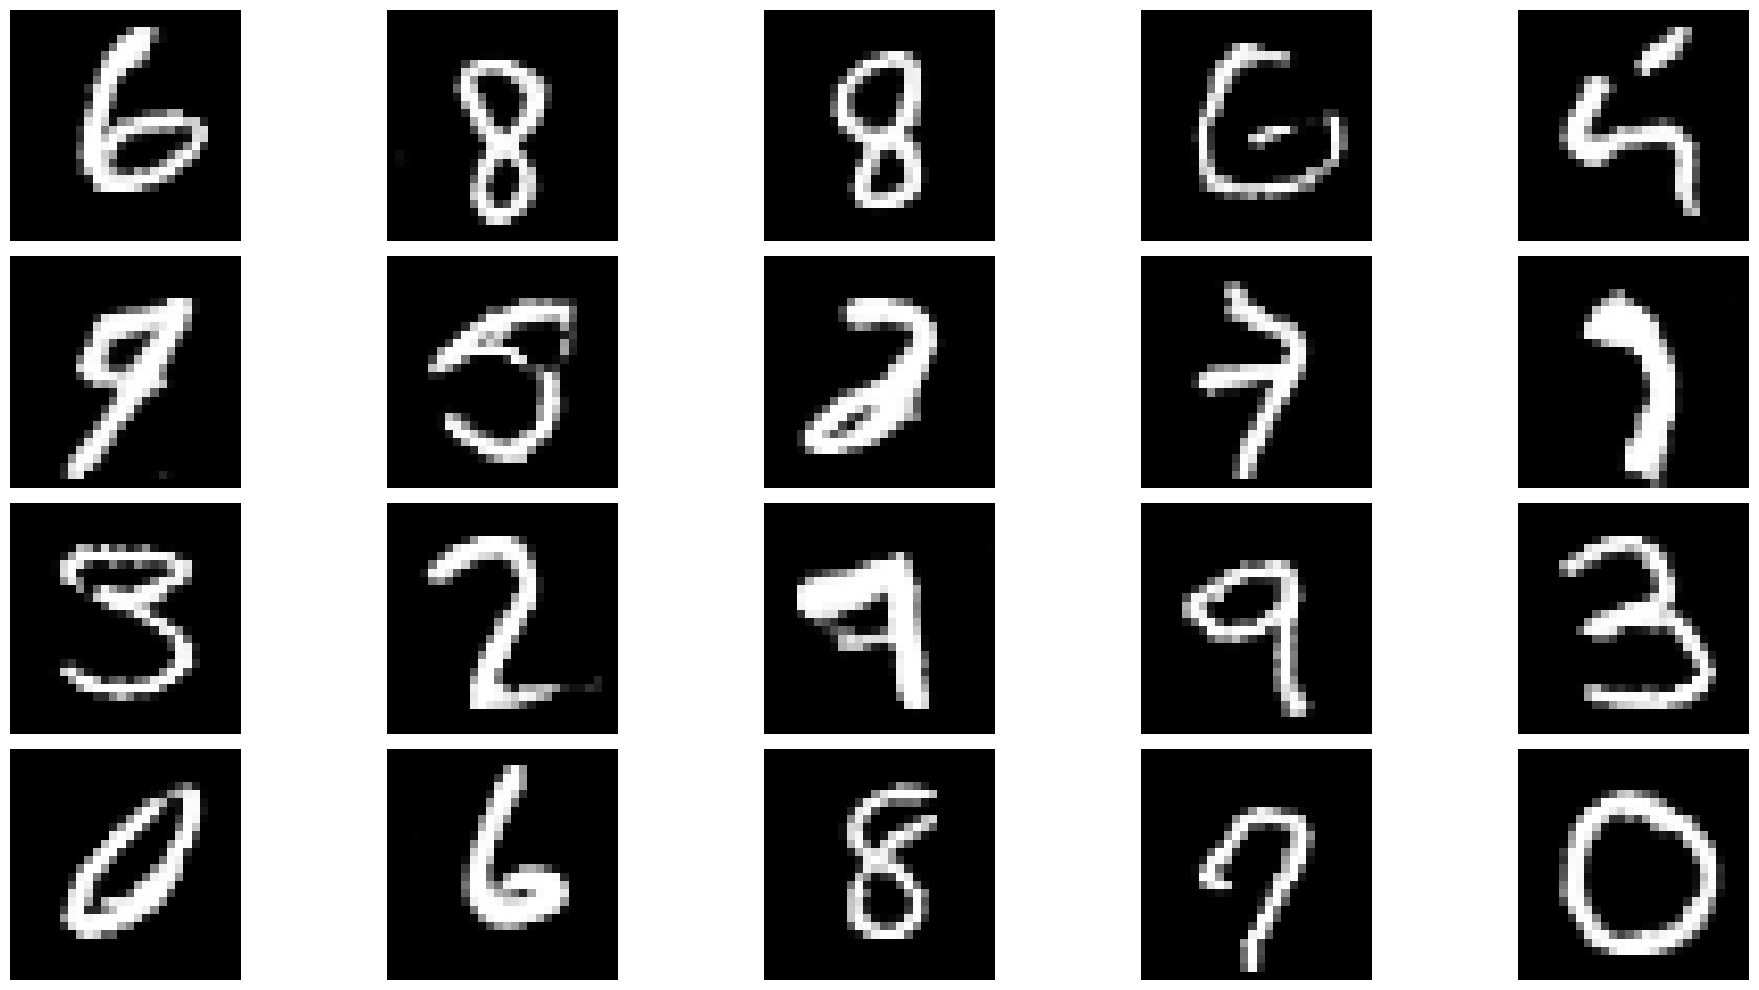

📈 Epoch 50 Summary:
   Train D Loss: 0.8384, Val D Loss: 1.1849
   Train G Loss: 1.6184, Val G Loss: 1.6522

📊 Epoch 51/100
----------------------------------------
Epoch: 51 [0/60000 (0%)]	D_loss: 0.804418	G_loss: 1.168108
Epoch: 51 [6400/60000 (11%)]	D_loss: 0.755347	G_loss: 2.043145
Epoch: 51 [12800/60000 (21%)]	D_loss: 0.874098	G_loss: 1.629936
Epoch: 51 [19200/60000 (32%)]	D_loss: 0.931996	G_loss: 1.218865
Epoch: 51 [25600/60000 (43%)]	D_loss: 0.853707	G_loss: 1.143059
Epoch: 51 [32000/60000 (53%)]	D_loss: 0.998901	G_loss: 1.890364
Epoch: 51 [38400/60000 (64%)]	D_loss: 0.887730	G_loss: 1.773162
Epoch: 51 [44800/60000 (75%)]	D_loss: 0.814715	G_loss: 3.176405
Epoch: 51 [51200/60000 (85%)]	D_loss: 0.805293	G_loss: 1.108706
Epoch: 51 [57600/60000 (96%)]	D_loss: 1.029069	G_loss: 3.121282
====> Epoch: 51 Train D_loss: 0.8357, Train G_loss: 1.6428
====> Epoch: 51 Val D_loss: 1.1732, Val G_loss: 1.6289
📈 Epoch 51 Summary:
   Train D Loss: 0.8357, Val D Loss: 1.1732
   Train G Loss: 1.6428

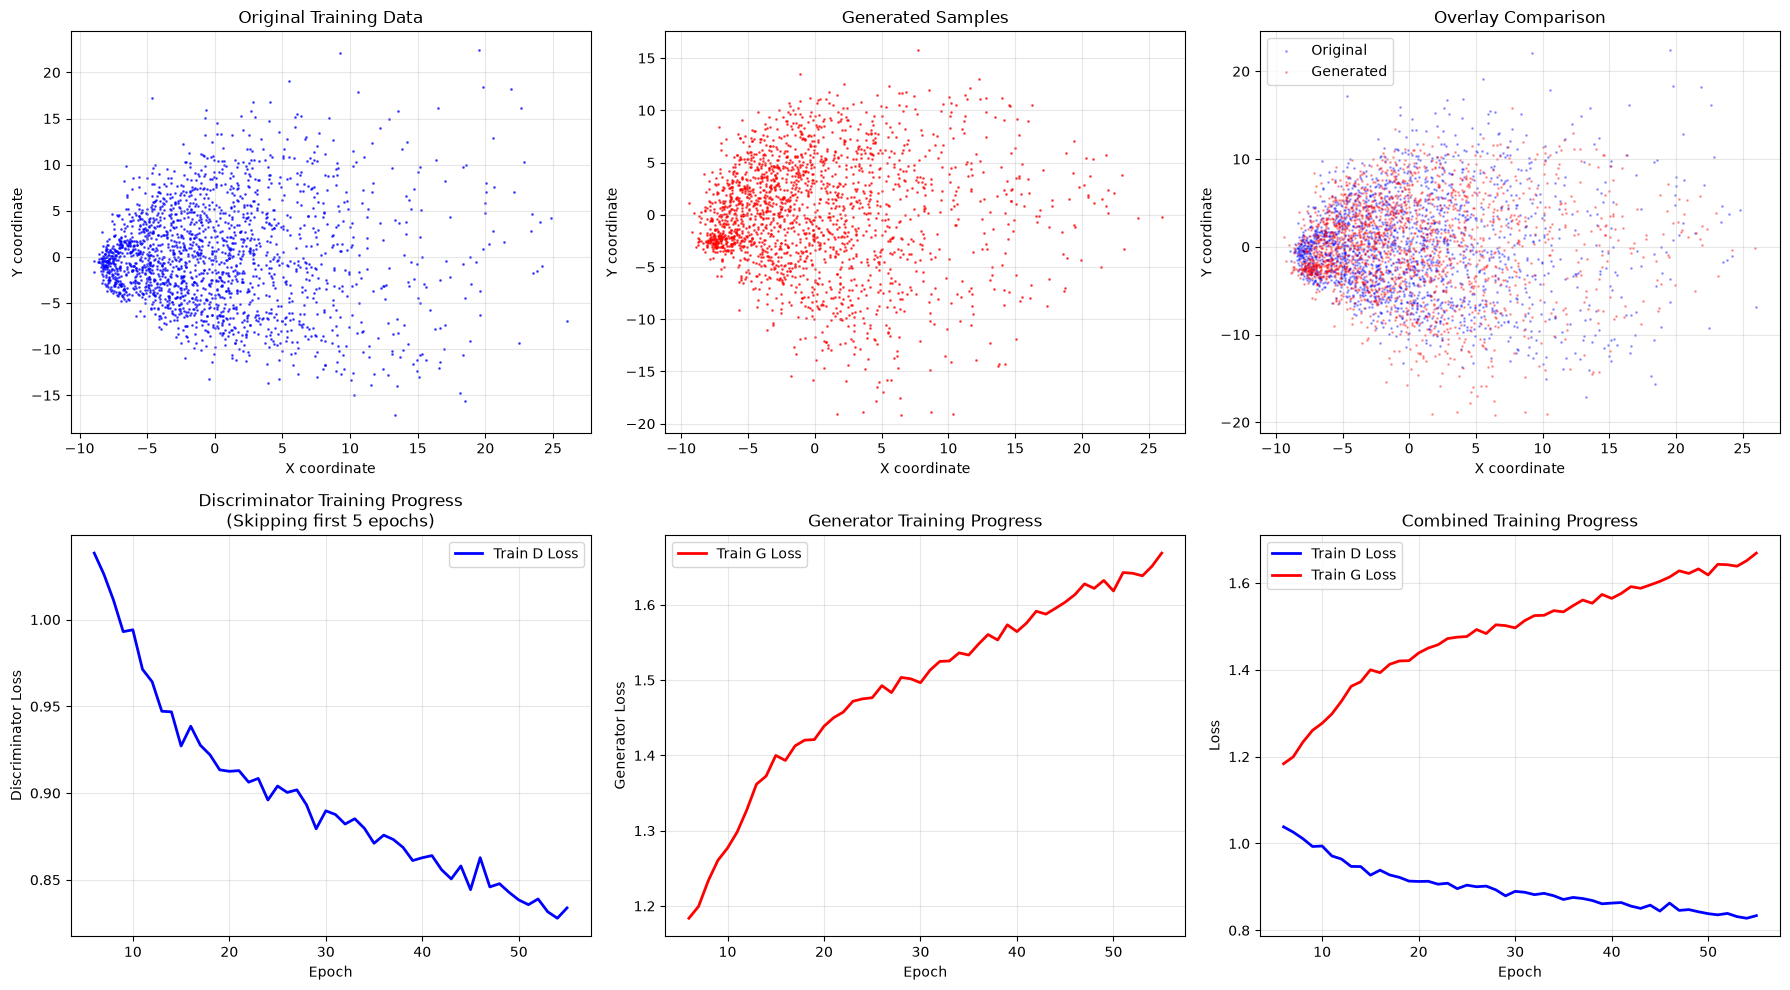

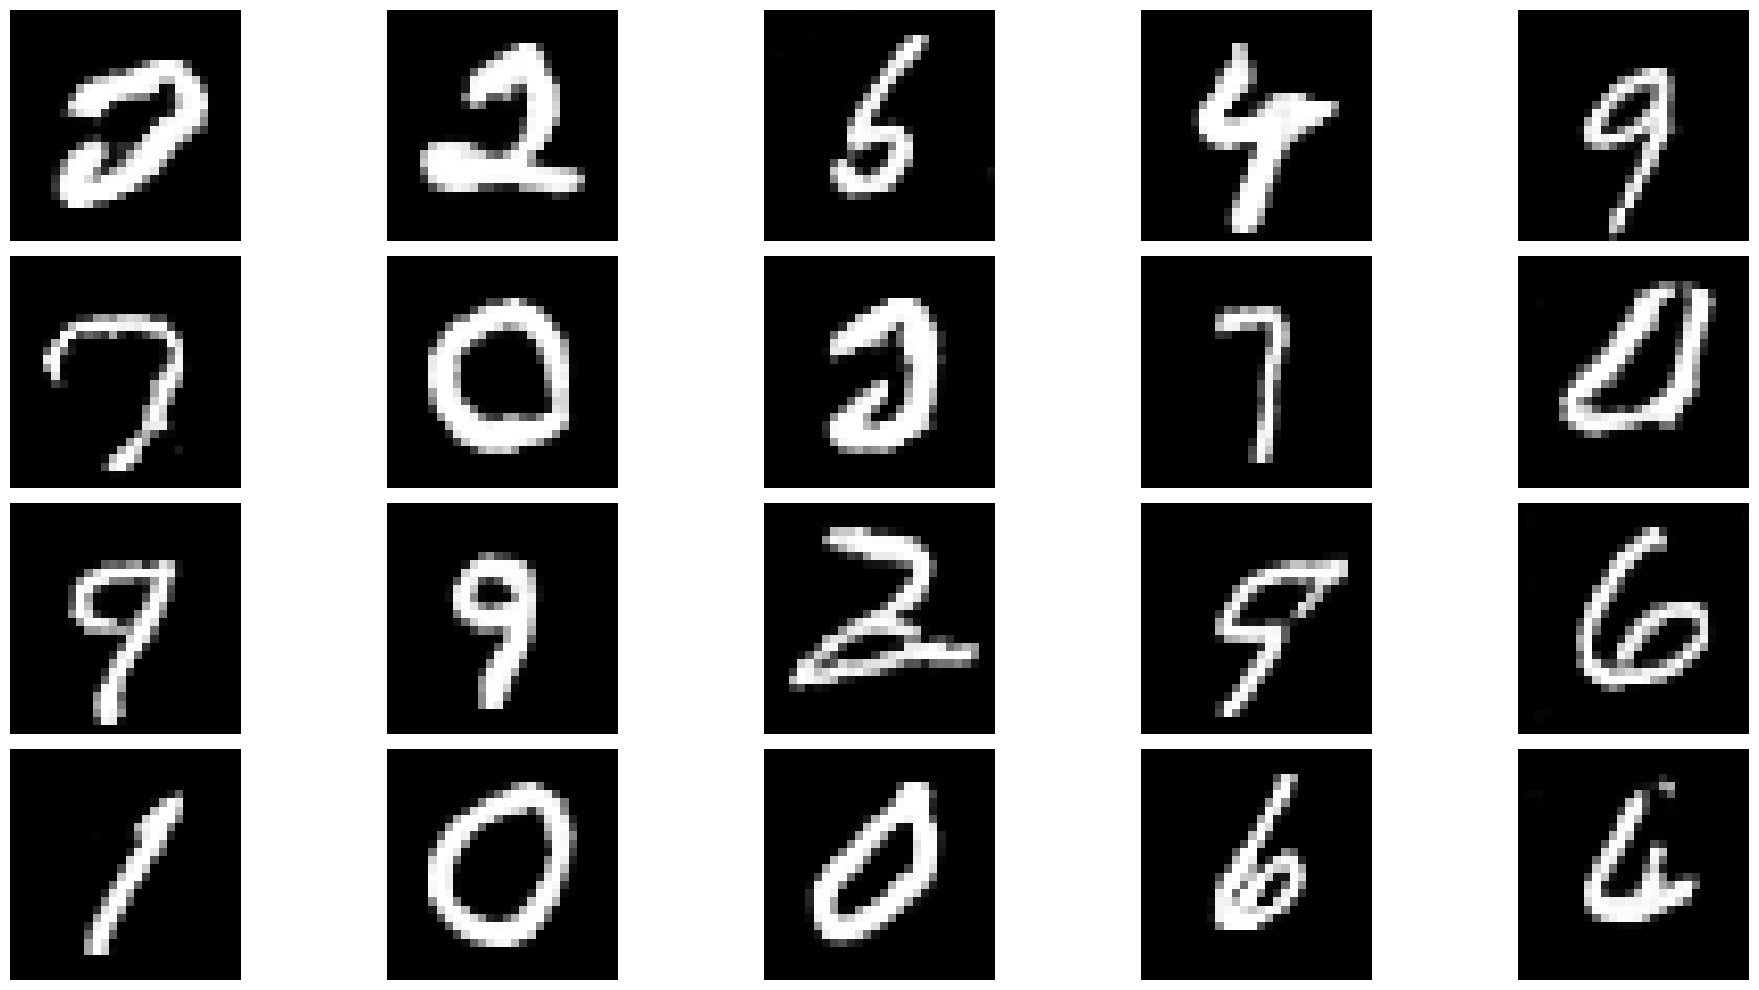

📈 Epoch 55 Summary:
   Train D Loss: 0.8338, Val D Loss: 1.2183
   Train G Loss: 1.6686, Val G Loss: 1.7416

📊 Epoch 56/100
----------------------------------------
Epoch: 56 [0/60000 (0%)]	D_loss: 0.773114	G_loss: 1.352446
Epoch: 56 [6400/60000 (11%)]	D_loss: 0.728850	G_loss: 1.831256
Epoch: 56 [12800/60000 (21%)]	D_loss: 0.652395	G_loss: 1.629435
Epoch: 56 [19200/60000 (32%)]	D_loss: 0.968547	G_loss: 1.402596
Epoch: 56 [25600/60000 (43%)]	D_loss: 0.683204	G_loss: 1.394612
Epoch: 56 [32000/60000 (53%)]	D_loss: 0.693868	G_loss: 1.608521
Epoch: 56 [38400/60000 (64%)]	D_loss: 0.749286	G_loss: 2.011425
Epoch: 56 [44800/60000 (75%)]	D_loss: 0.775052	G_loss: 1.453515
Epoch: 56 [51200/60000 (85%)]	D_loss: 1.267576	G_loss: 2.754032
Epoch: 56 [57600/60000 (96%)]	D_loss: 0.662529	G_loss: 1.573931
====> Epoch: 56 Train D_loss: 0.8208, Train G_loss: 1.6665
====> Epoch: 56 Val D_loss: 1.1140, Val G_loss: 1.0910
📈 Epoch 56 Summary:
   Train D Loss: 0.8208, Val D Loss: 1.1140
   Train G Loss: 1.6665

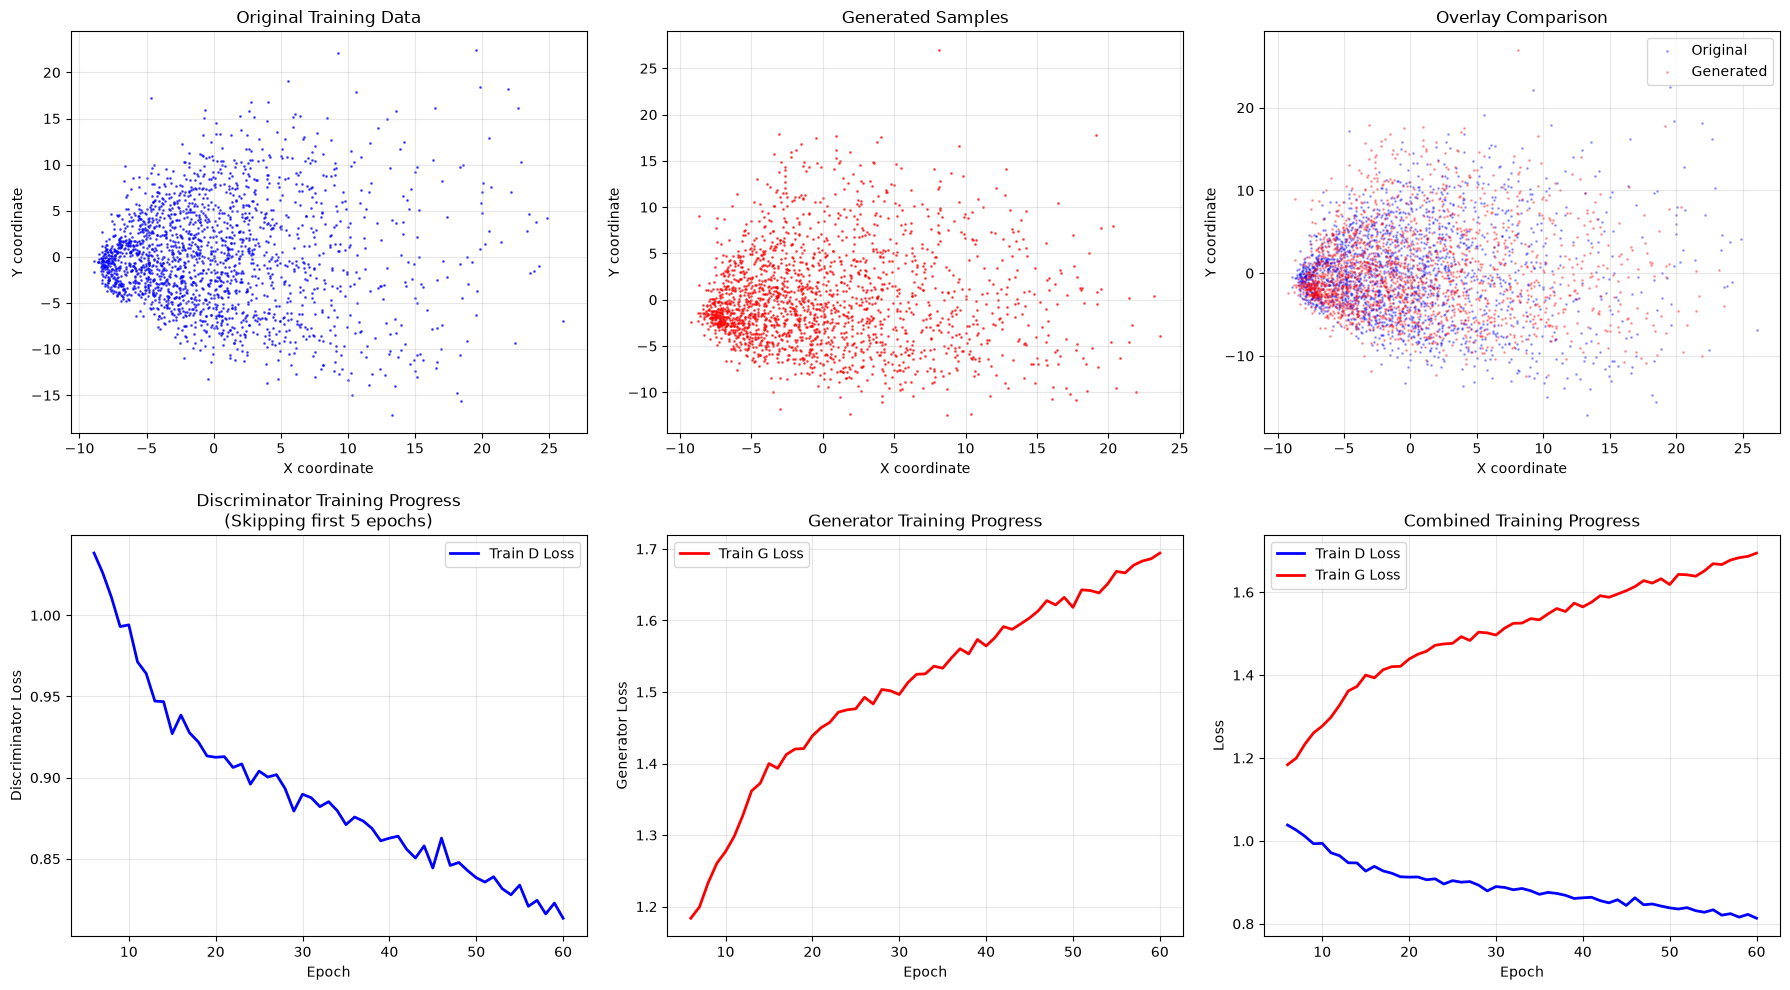

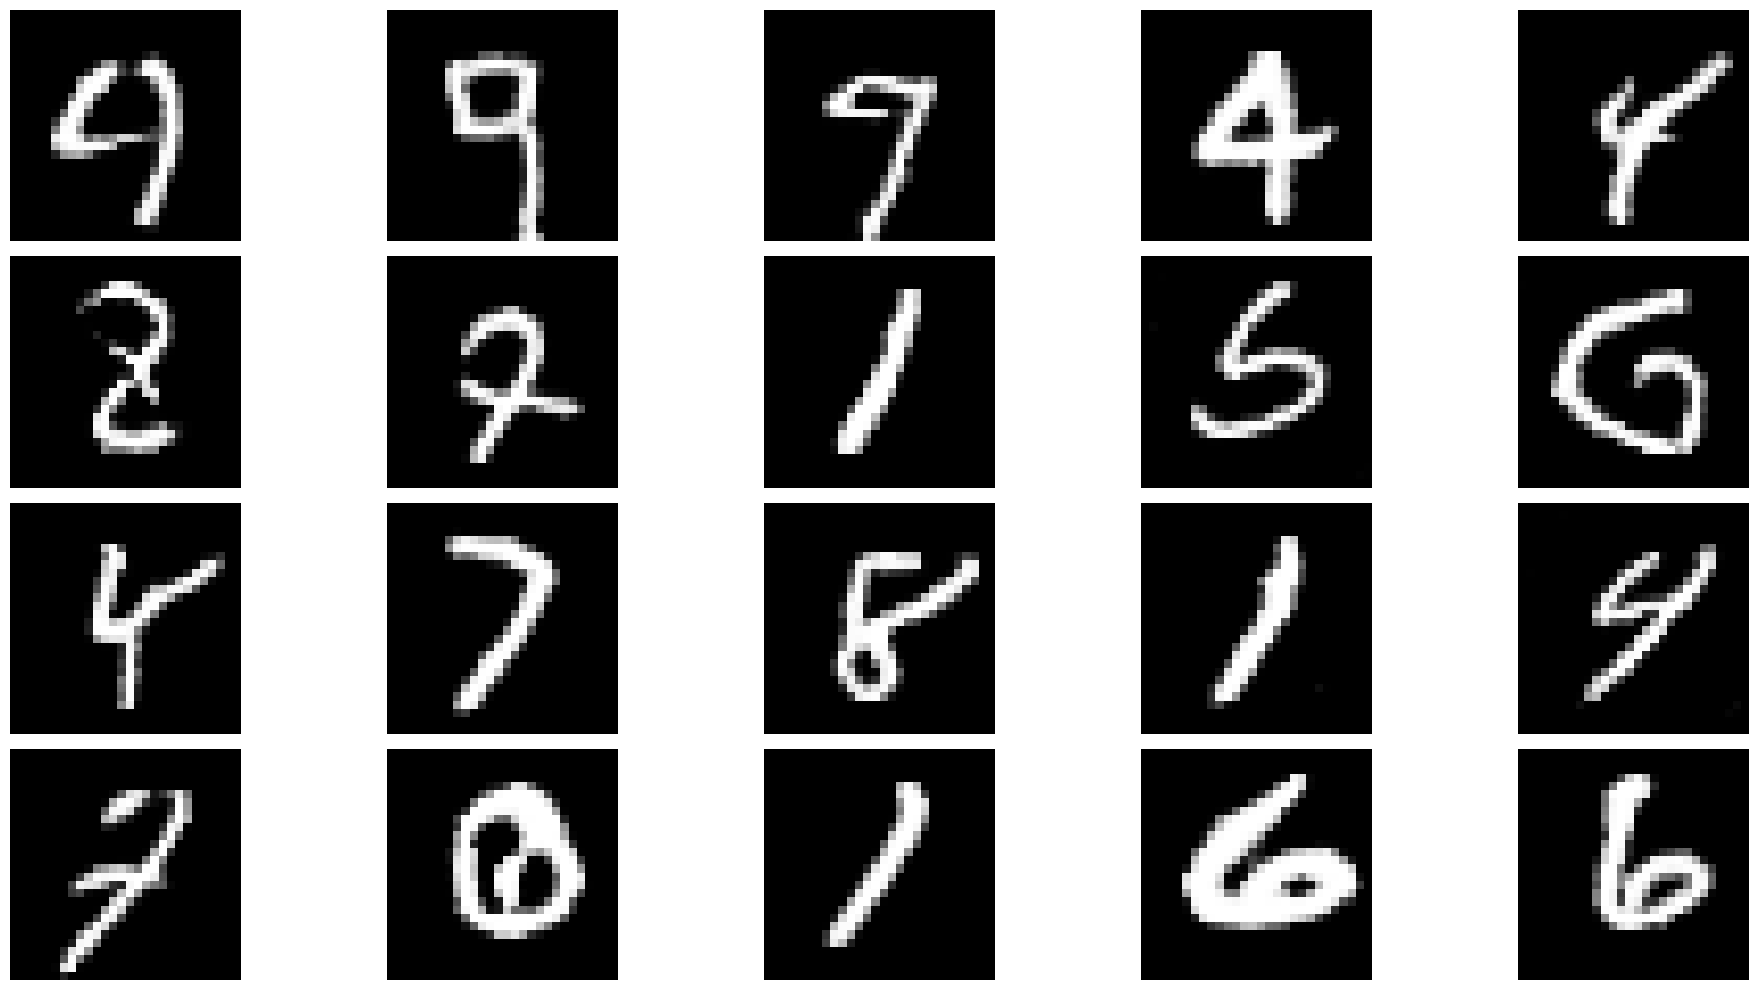

📈 Epoch 60 Summary:
   Train D Loss: 0.8134, Val D Loss: 1.8414
   Train G Loss: 1.6942, Val G Loss: 0.3487

📊 Epoch 61/100
----------------------------------------
Epoch: 61 [0/60000 (0%)]	D_loss: 1.099088	G_loss: 2.206351
Epoch: 61 [6400/60000 (11%)]	D_loss: 0.846608	G_loss: 2.030982
Epoch: 61 [12800/60000 (21%)]	D_loss: 0.758215	G_loss: 1.634430
Epoch: 61 [19200/60000 (32%)]	D_loss: 0.753884	G_loss: 1.765718
Epoch: 61 [25600/60000 (43%)]	D_loss: 0.782988	G_loss: 1.291292
Epoch: 61 [32000/60000 (53%)]	D_loss: 0.652278	G_loss: 1.618179
Epoch: 61 [38400/60000 (64%)]	D_loss: 0.743886	G_loss: 1.857411
Epoch: 61 [44800/60000 (75%)]	D_loss: 0.749529	G_loss: 1.756378
Epoch: 61 [51200/60000 (85%)]	D_loss: 0.728870	G_loss: 1.968873
Epoch: 61 [57600/60000 (96%)]	D_loss: 0.860508	G_loss: 1.038549
====> Epoch: 61 Train D_loss: 0.8100, Train G_loss: 1.7164
====> Epoch: 61 Val D_loss: 1.1343, Val G_loss: 1.3420
📈 Epoch 61 Summary:
   Train D Loss: 0.8100, Val D Loss: 1.1343
   Train G Loss: 1.7164

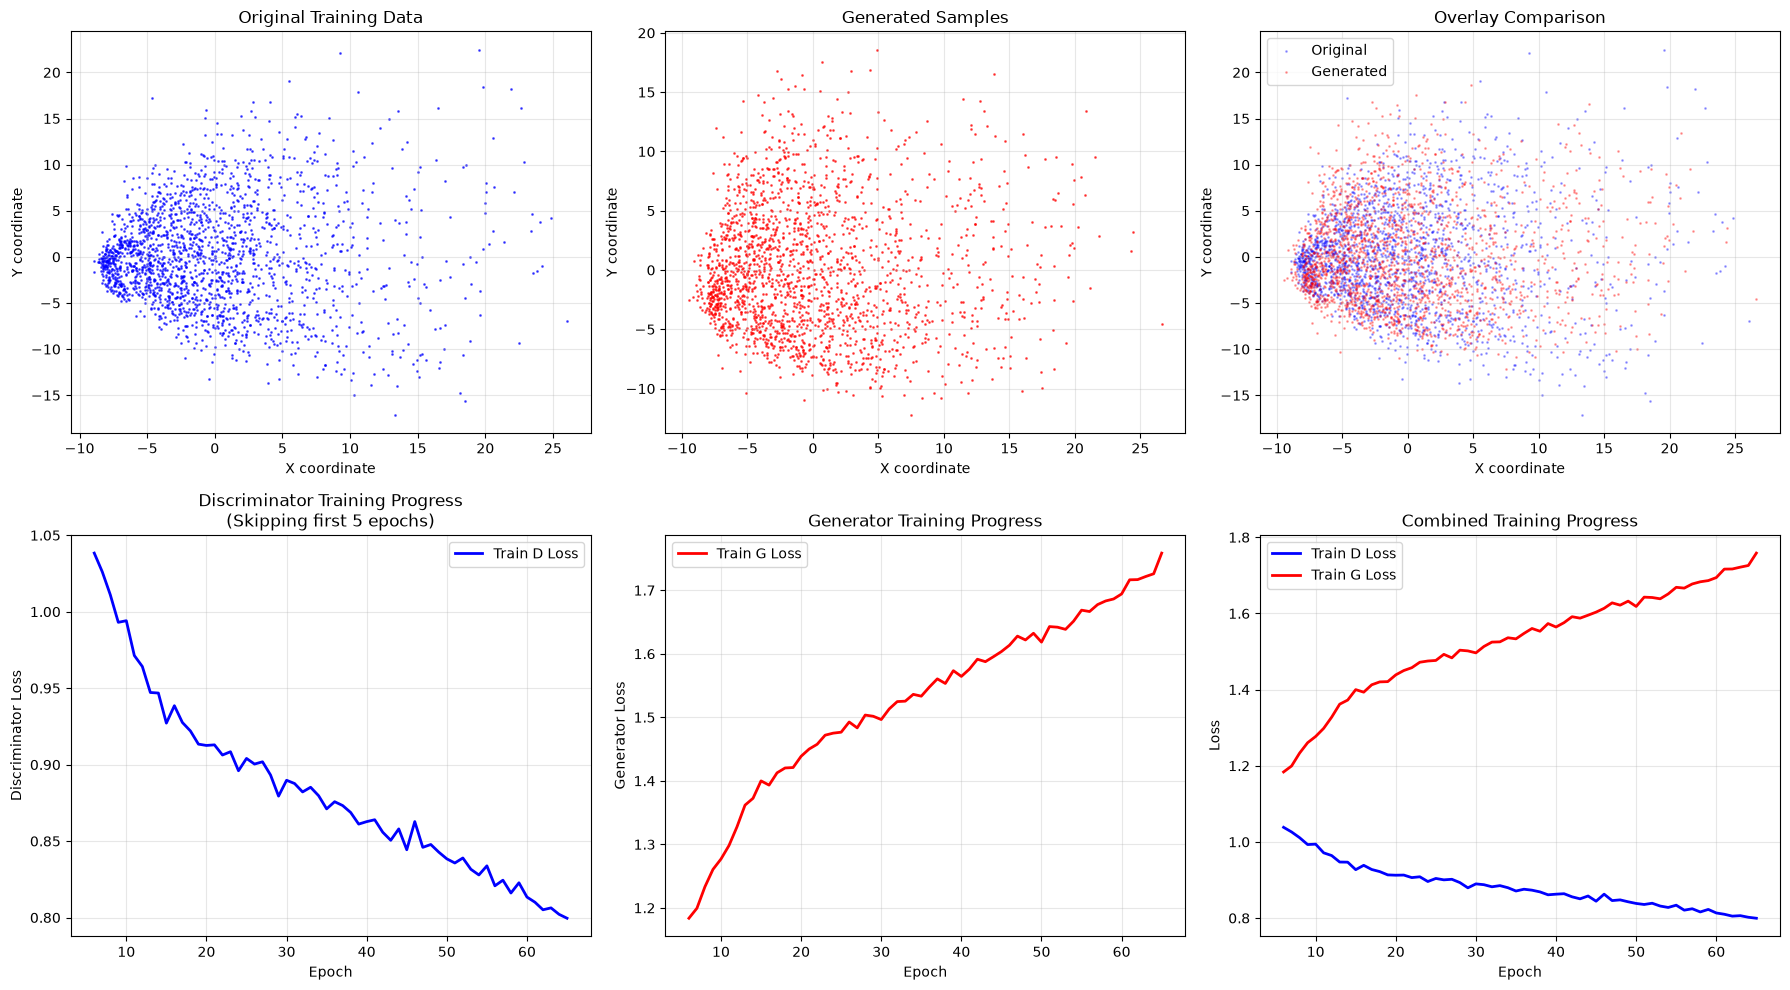

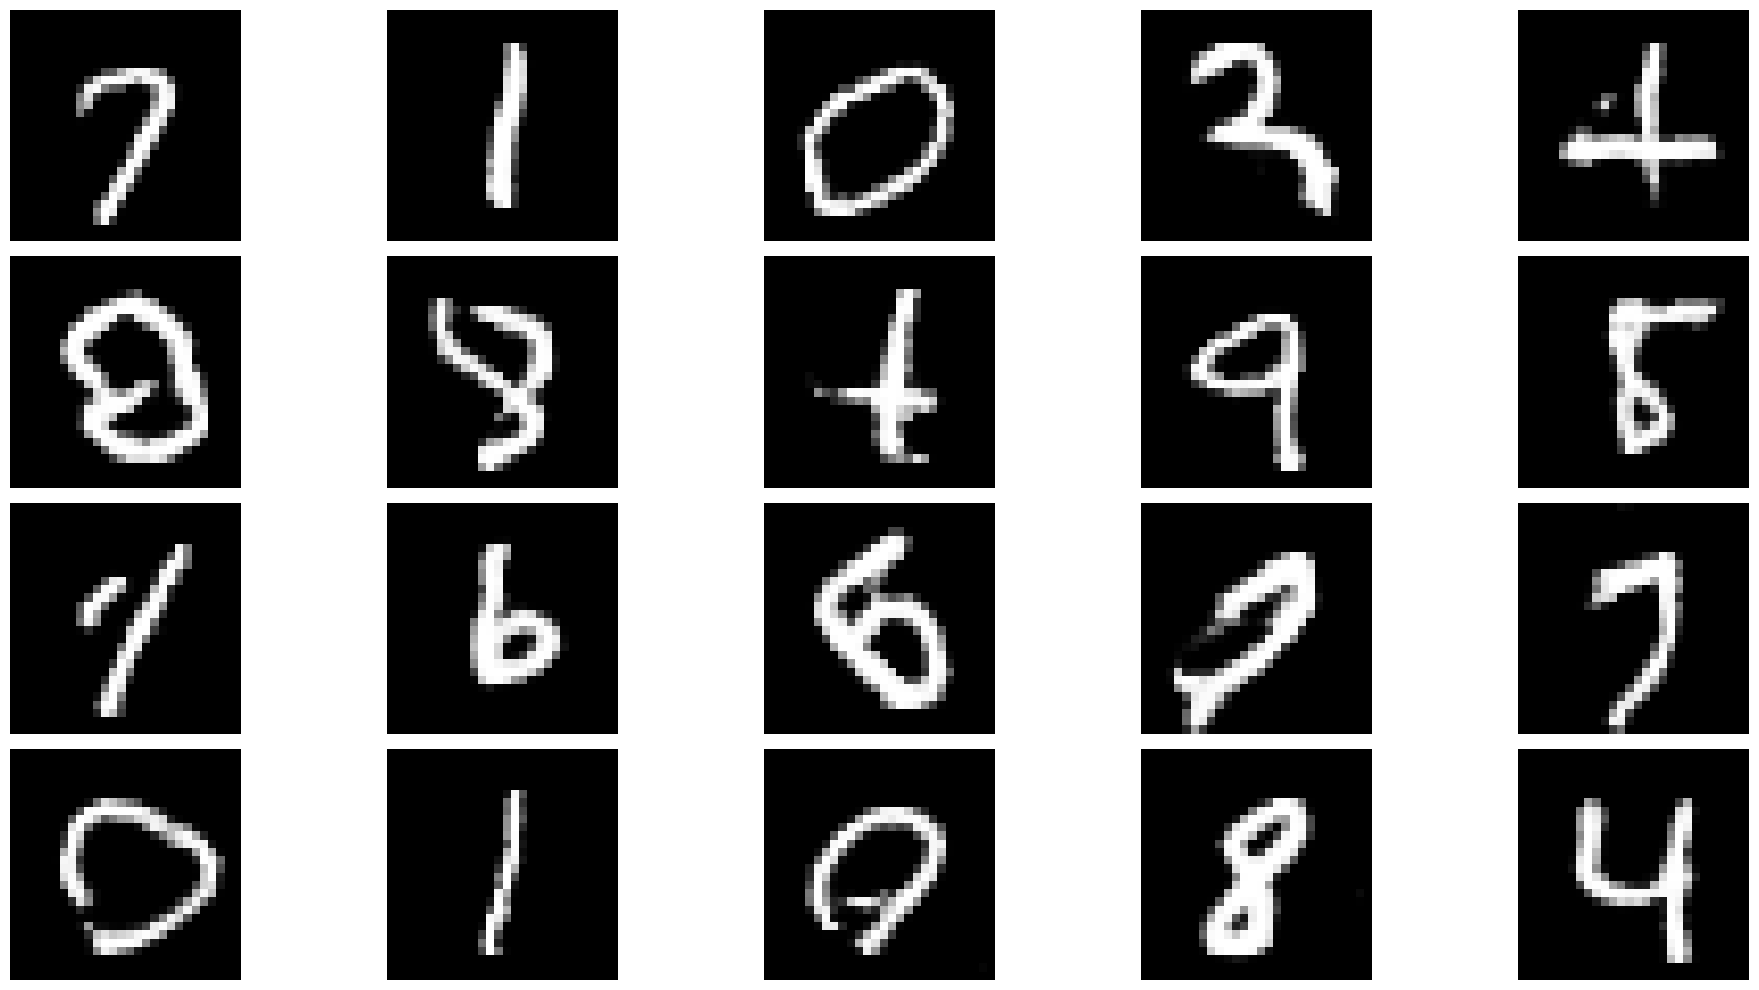

📈 Epoch 65 Summary:
   Train D Loss: 0.7996, Val D Loss: 1.2954
   Train G Loss: 1.7585, Val G Loss: 1.7522

📊 Epoch 66/100
----------------------------------------
Epoch: 66 [0/60000 (0%)]	D_loss: 0.858721	G_loss: 1.594576
Epoch: 66 [6400/60000 (11%)]	D_loss: 0.773243	G_loss: 2.661580
Epoch: 66 [12800/60000 (21%)]	D_loss: 0.880995	G_loss: 1.159590
Epoch: 66 [19200/60000 (32%)]	D_loss: 0.771813	G_loss: 1.144735
Epoch: 66 [25600/60000 (43%)]	D_loss: 0.758996	G_loss: 2.237814
Epoch: 66 [32000/60000 (53%)]	D_loss: 0.761598	G_loss: 1.484677
Epoch: 66 [38400/60000 (64%)]	D_loss: 0.741821	G_loss: 1.314456
Epoch: 66 [44800/60000 (75%)]	D_loss: 0.816817	G_loss: 1.415445
Epoch: 66 [51200/60000 (85%)]	D_loss: 0.684247	G_loss: 1.484981
Epoch: 66 [57600/60000 (96%)]	D_loss: 0.792201	G_loss: 2.329261
====> Epoch: 66 Train D_loss: 0.7987, Train G_loss: 1.7646
====> Epoch: 66 Val D_loss: 1.1527, Val G_loss: 1.5803
📈 Epoch 66 Summary:
   Train D Loss: 0.7987, Val D Loss: 1.1527
   Train G Loss: 1.7646

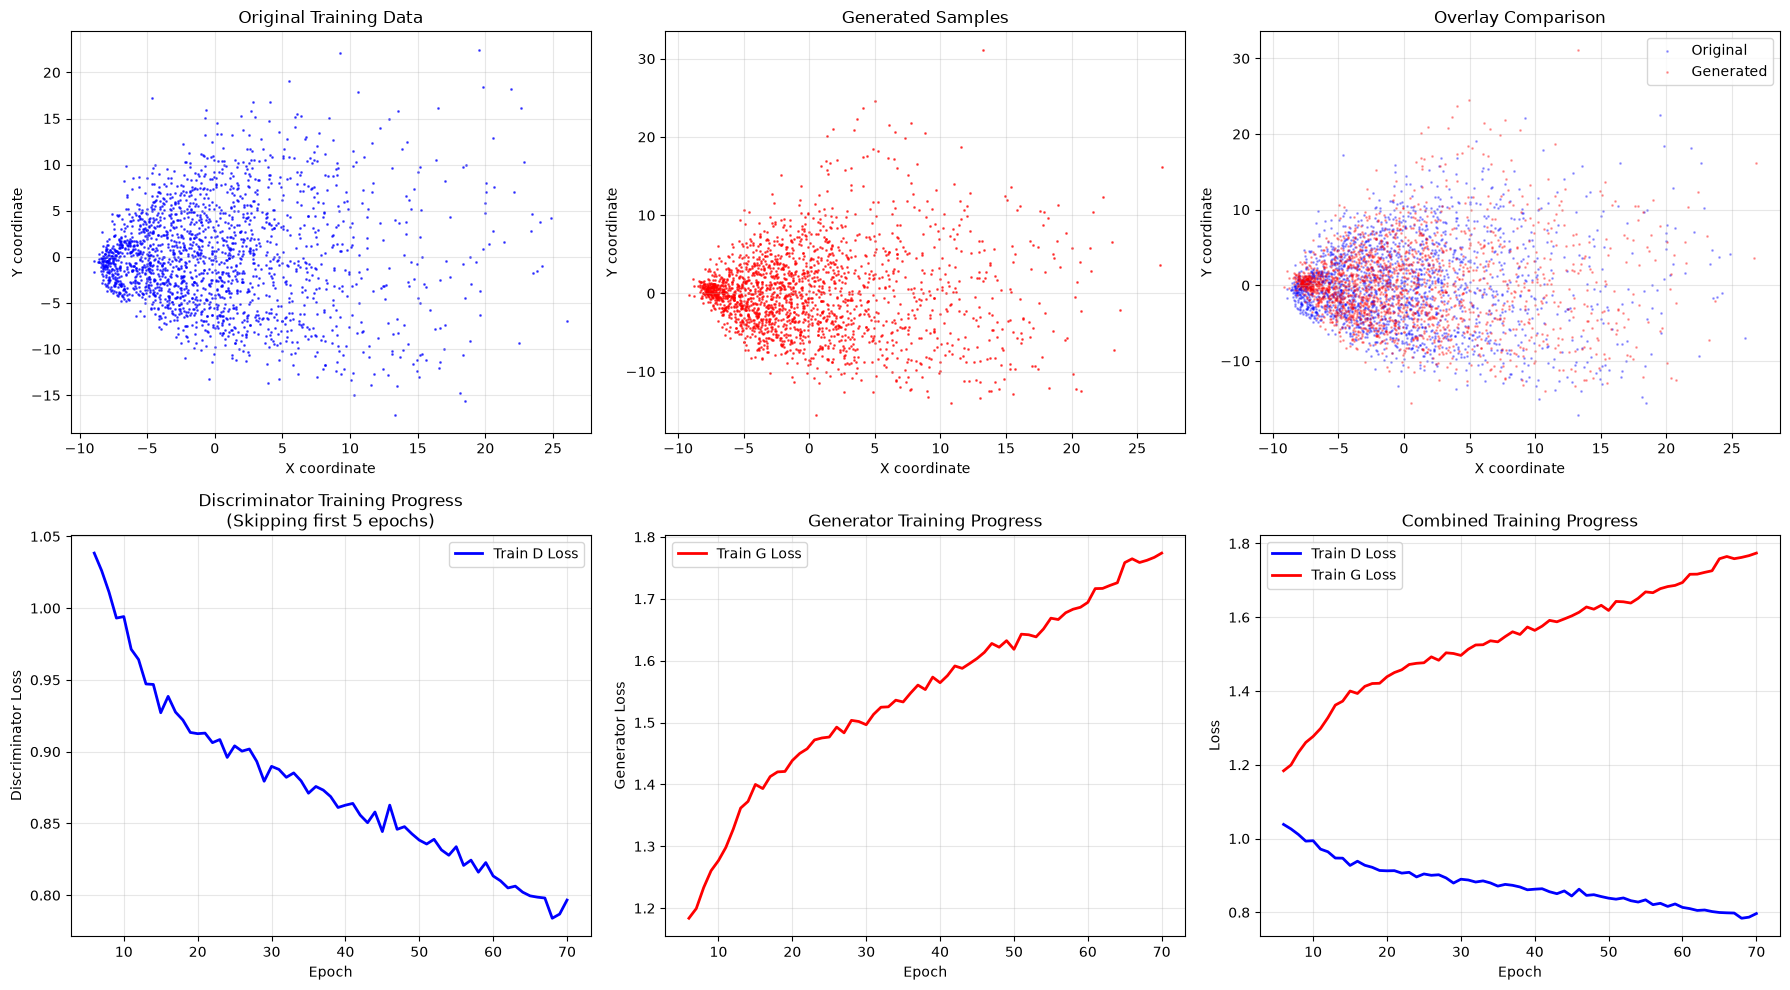

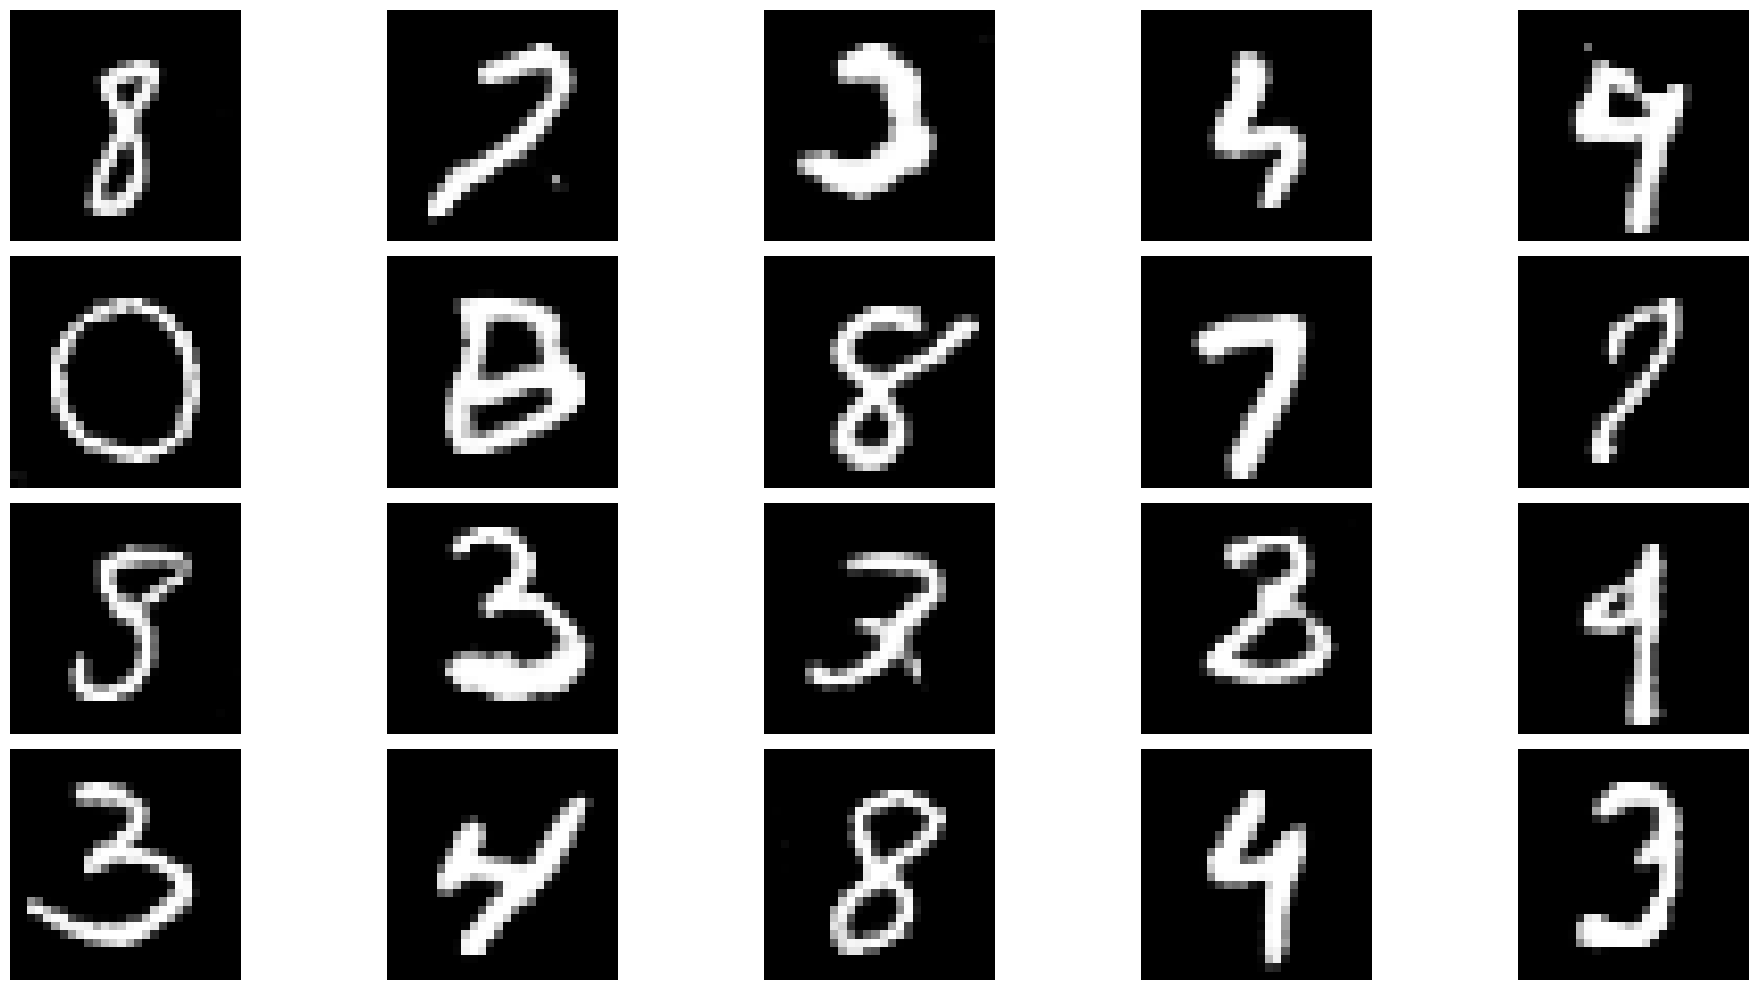

📈 Epoch 70 Summary:
   Train D Loss: 0.7966, Val D Loss: 1.0939
   Train G Loss: 1.7738, Val G Loss: 1.1857

📊 Epoch 71/100
----------------------------------------
Epoch: 71 [0/60000 (0%)]	D_loss: 0.800022	G_loss: 1.980396
Epoch: 71 [6400/60000 (11%)]	D_loss: 0.747712	G_loss: 1.705733
Epoch: 71 [12800/60000 (21%)]	D_loss: 0.931128	G_loss: 1.633684
Epoch: 71 [19200/60000 (32%)]	D_loss: 0.736199	G_loss: 1.188965
Epoch: 71 [25600/60000 (43%)]	D_loss: 0.781101	G_loss: 1.262332
Epoch: 71 [32000/60000 (53%)]	D_loss: 0.727737	G_loss: 1.583241
Epoch: 71 [38400/60000 (64%)]	D_loss: 0.723880	G_loss: 1.968997
Epoch: 71 [44800/60000 (75%)]	D_loss: 0.790768	G_loss: 1.141914
Epoch: 71 [51200/60000 (85%)]	D_loss: 0.781184	G_loss: 2.639461
Epoch: 71 [57600/60000 (96%)]	D_loss: 0.653830	G_loss: 1.656588
====> Epoch: 71 Train D_loss: 0.7761, Train G_loss: 1.7887
====> Epoch: 71 Val D_loss: 1.4518, Val G_loss: 2.3601
📈 Epoch 71 Summary:
   Train D Loss: 0.7761, Val D Loss: 1.4518
   Train G Loss: 1.7887

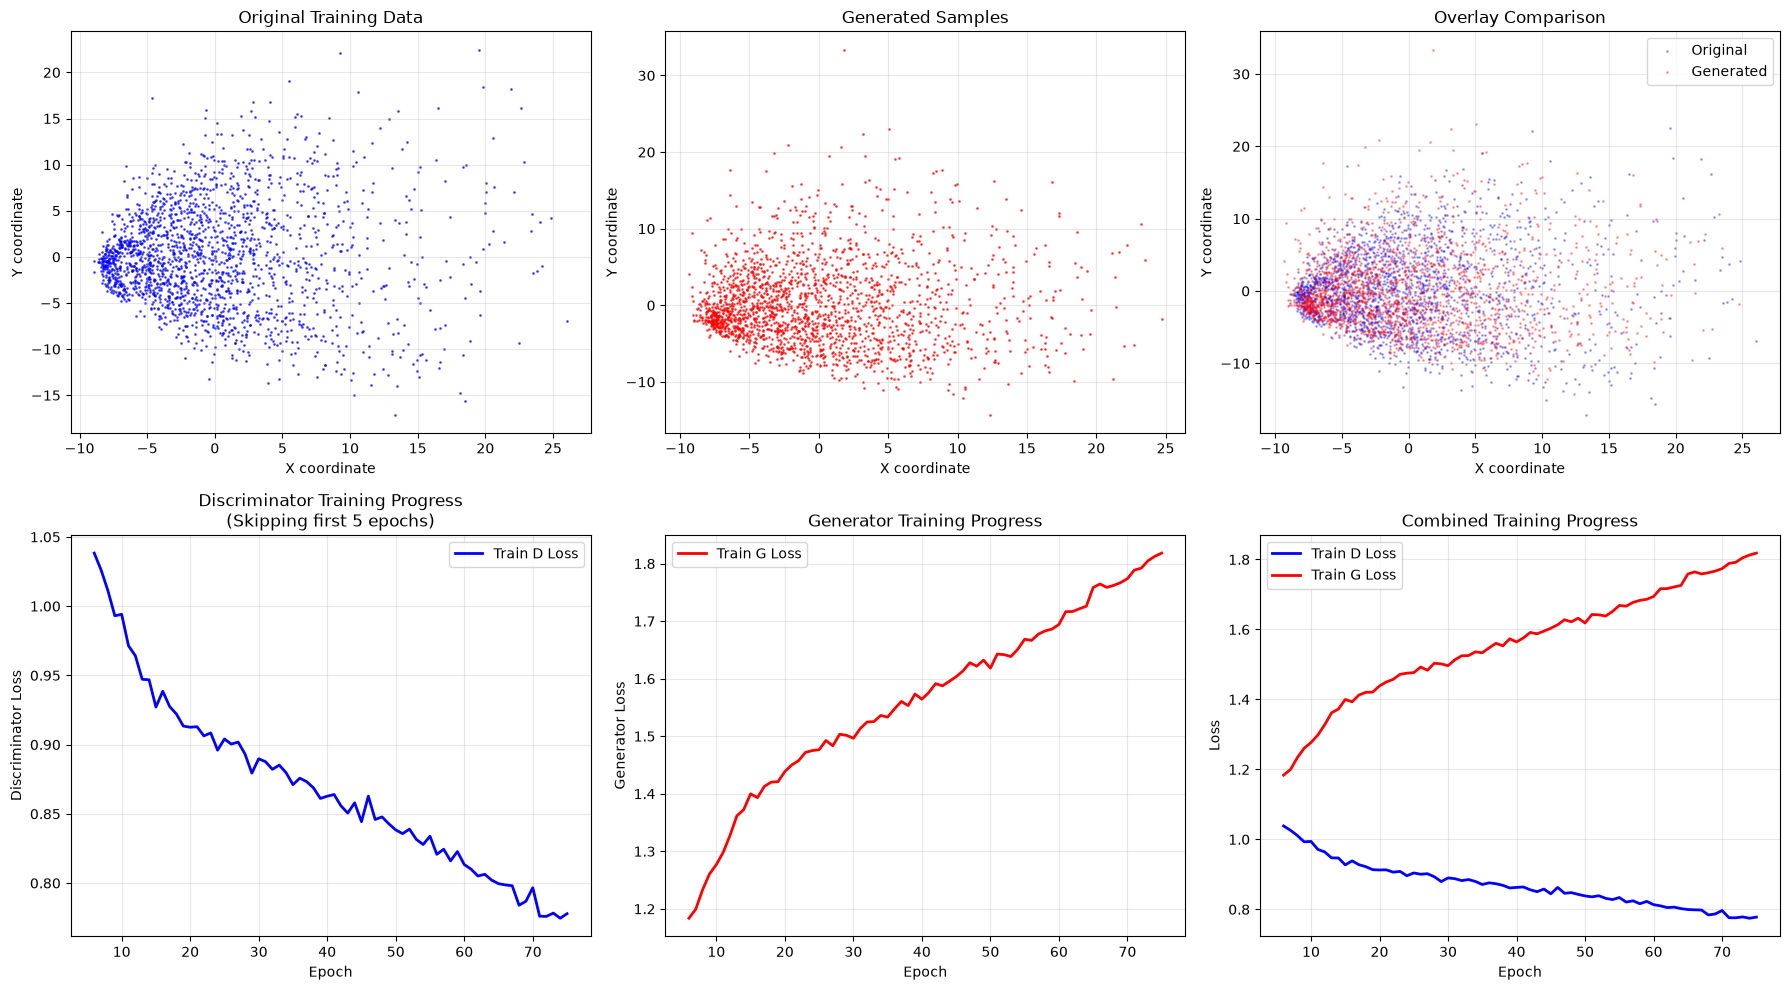

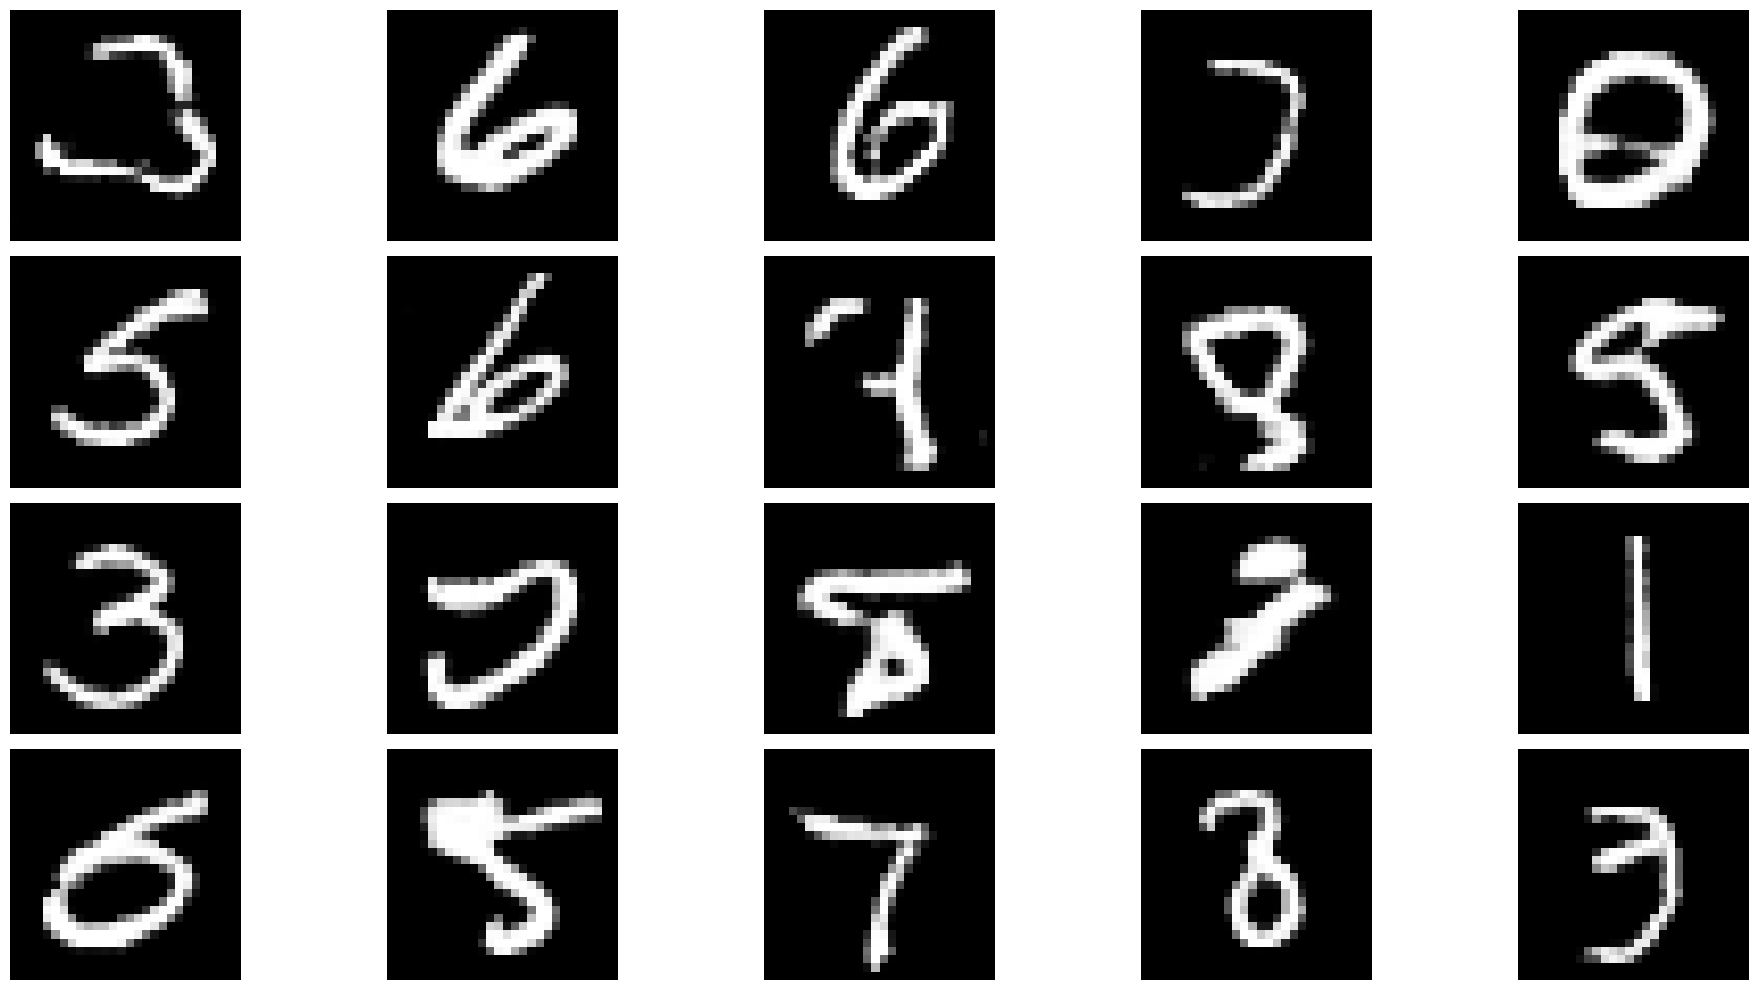

📈 Epoch 75 Summary:
   Train D Loss: 0.7779, Val D Loss: 1.1772
   Train G Loss: 1.8183, Val G Loss: 1.6066

📊 Epoch 76/100
----------------------------------------
Epoch: 76 [0/60000 (0%)]	D_loss: 0.746841	G_loss: 1.878424
Epoch: 76 [6400/60000 (11%)]	D_loss: 0.912305	G_loss: 1.260308
Epoch: 76 [12800/60000 (21%)]	D_loss: 0.818023	G_loss: 1.601937
Epoch: 76 [19200/60000 (32%)]	D_loss: 0.880127	G_loss: 1.135123
Epoch: 76 [25600/60000 (43%)]	D_loss: 0.795801	G_loss: 1.986591
Epoch: 76 [32000/60000 (53%)]	D_loss: 0.759324	G_loss: 1.684137
Epoch: 76 [38400/60000 (64%)]	D_loss: 0.610582	G_loss: 2.136272
Epoch: 76 [44800/60000 (75%)]	D_loss: 0.791613	G_loss: 2.144814
Epoch: 76 [51200/60000 (85%)]	D_loss: 0.721066	G_loss: 1.844980
Epoch: 76 [57600/60000 (96%)]	D_loss: 0.735703	G_loss: 1.834057
====> Epoch: 76 Train D_loss: 0.7667, Train G_loss: 1.8308
====> Epoch: 76 Val D_loss: 1.5225, Val G_loss: 2.4904
📈 Epoch 76 Summary:
   Train D Loss: 0.7667, Val D Loss: 1.5225
   Train G Loss: 1.8308

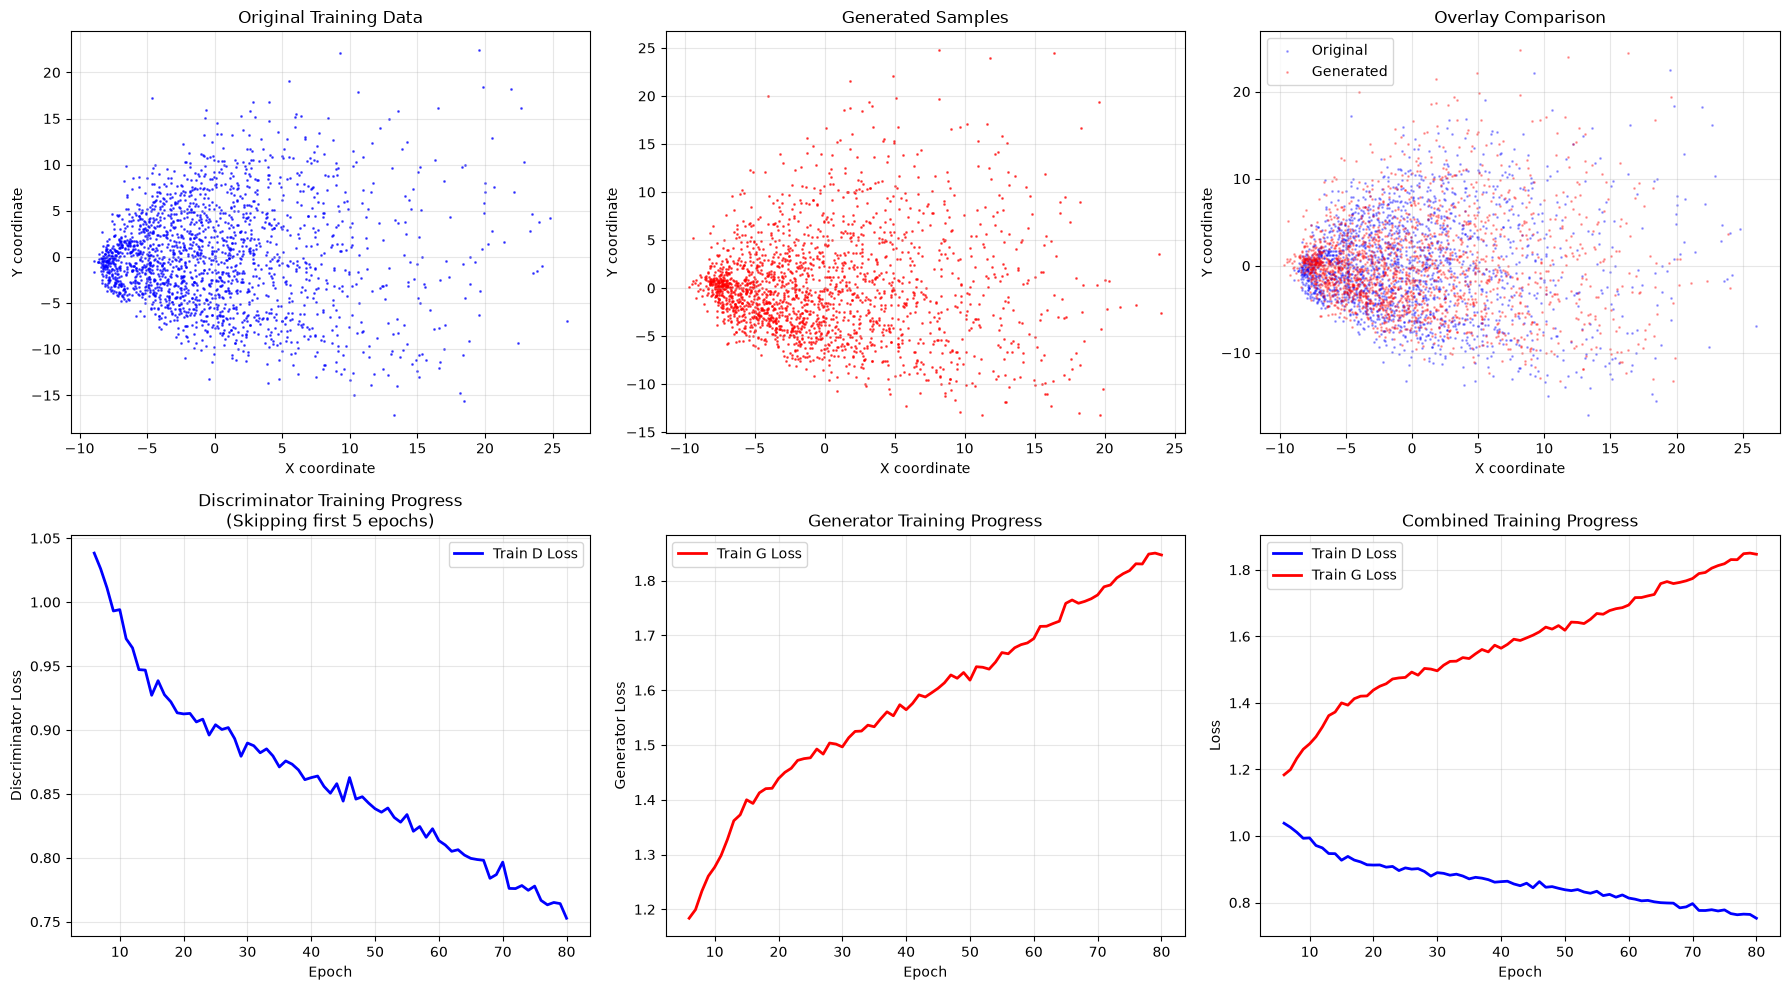

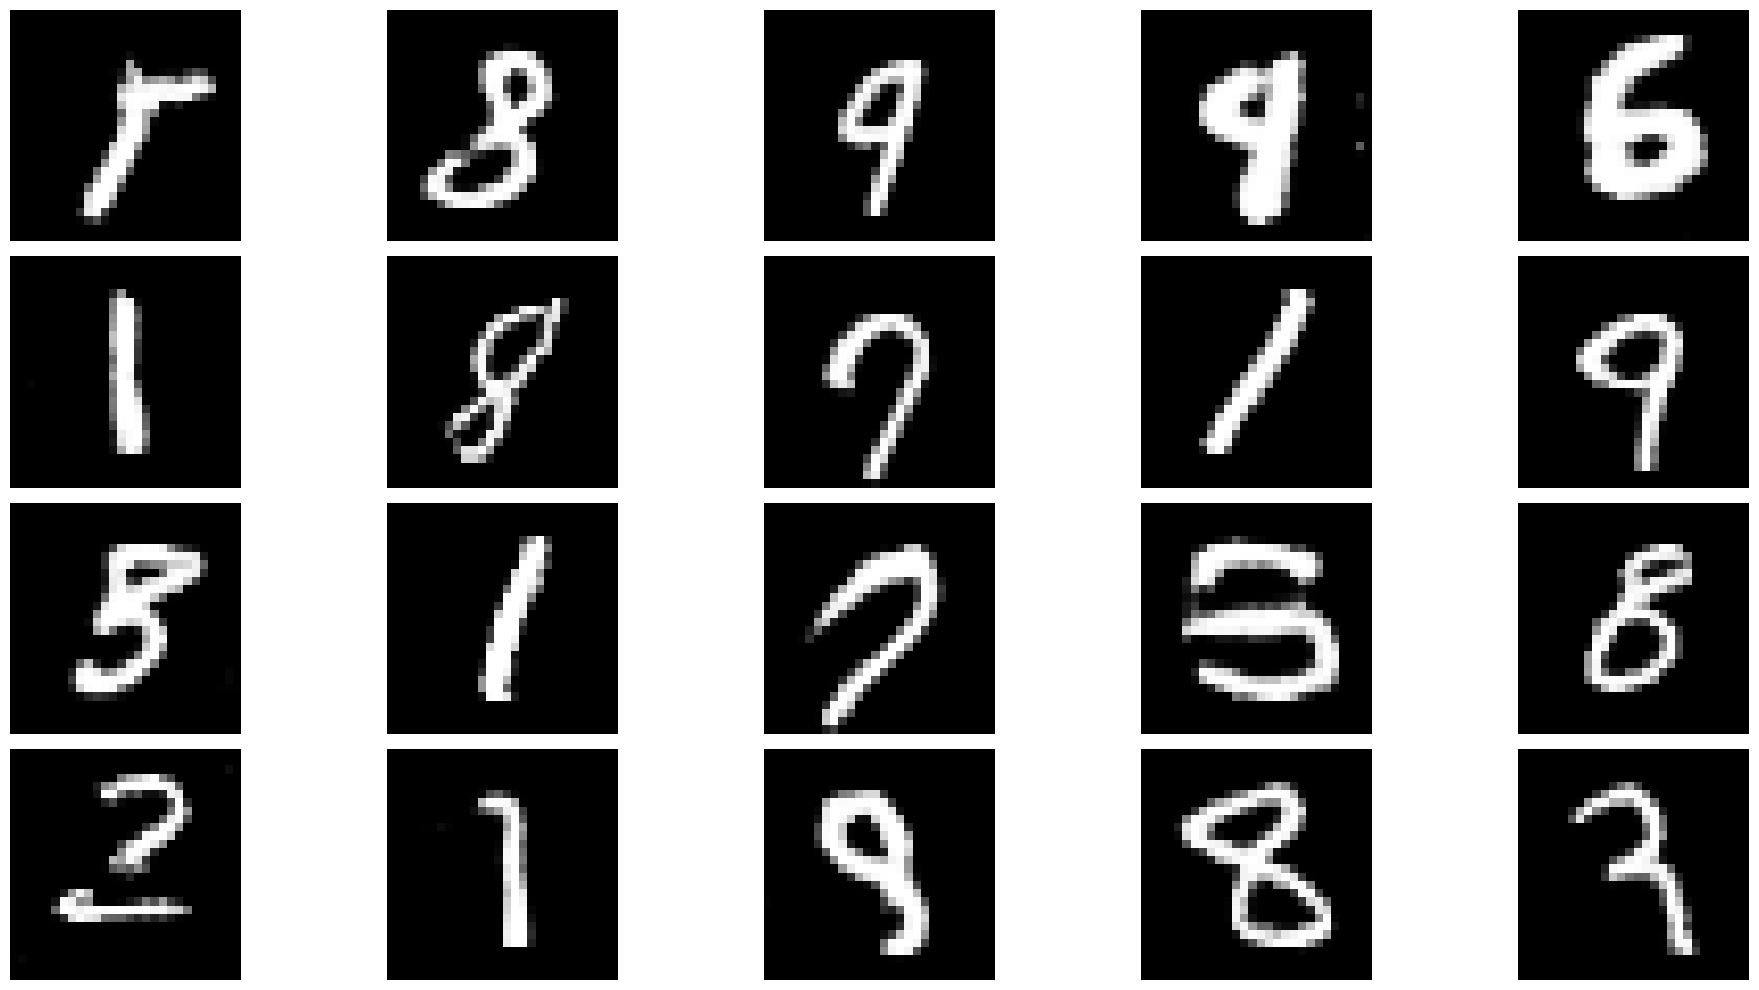

📈 Epoch 80 Summary:
   Train D Loss: 0.7527, Val D Loss: 1.3254
   Train G Loss: 1.8468, Val G Loss: 2.1072

📊 Epoch 81/100
----------------------------------------
Epoch: 81 [0/60000 (0%)]	D_loss: 0.757765	G_loss: 1.466547
Epoch: 81 [6400/60000 (11%)]	D_loss: 0.748791	G_loss: 1.823931
Epoch: 81 [12800/60000 (21%)]	D_loss: 0.723606	G_loss: 1.746538
Epoch: 81 [19200/60000 (32%)]	D_loss: 0.926060	G_loss: 1.069997
Epoch: 81 [25600/60000 (43%)]	D_loss: 0.603585	G_loss: 1.649985
Epoch: 81 [32000/60000 (53%)]	D_loss: 0.639350	G_loss: 1.581501
Epoch: 81 [38400/60000 (64%)]	D_loss: 1.528424	G_loss: 0.550603
Epoch: 81 [44800/60000 (75%)]	D_loss: 0.774618	G_loss: 1.604486
Epoch: 81 [51200/60000 (85%)]	D_loss: 0.714787	G_loss: 1.776632
Epoch: 81 [57600/60000 (96%)]	D_loss: 0.840814	G_loss: 1.753012
====> Epoch: 81 Train D_loss: 0.7493, Train G_loss: 1.8703
====> Epoch: 81 Val D_loss: 2.3078, Val G_loss: 0.2321
📈 Epoch 81 Summary:
   Train D Loss: 0.7493, Val D Loss: 2.3078
   Train G Loss: 1.8703

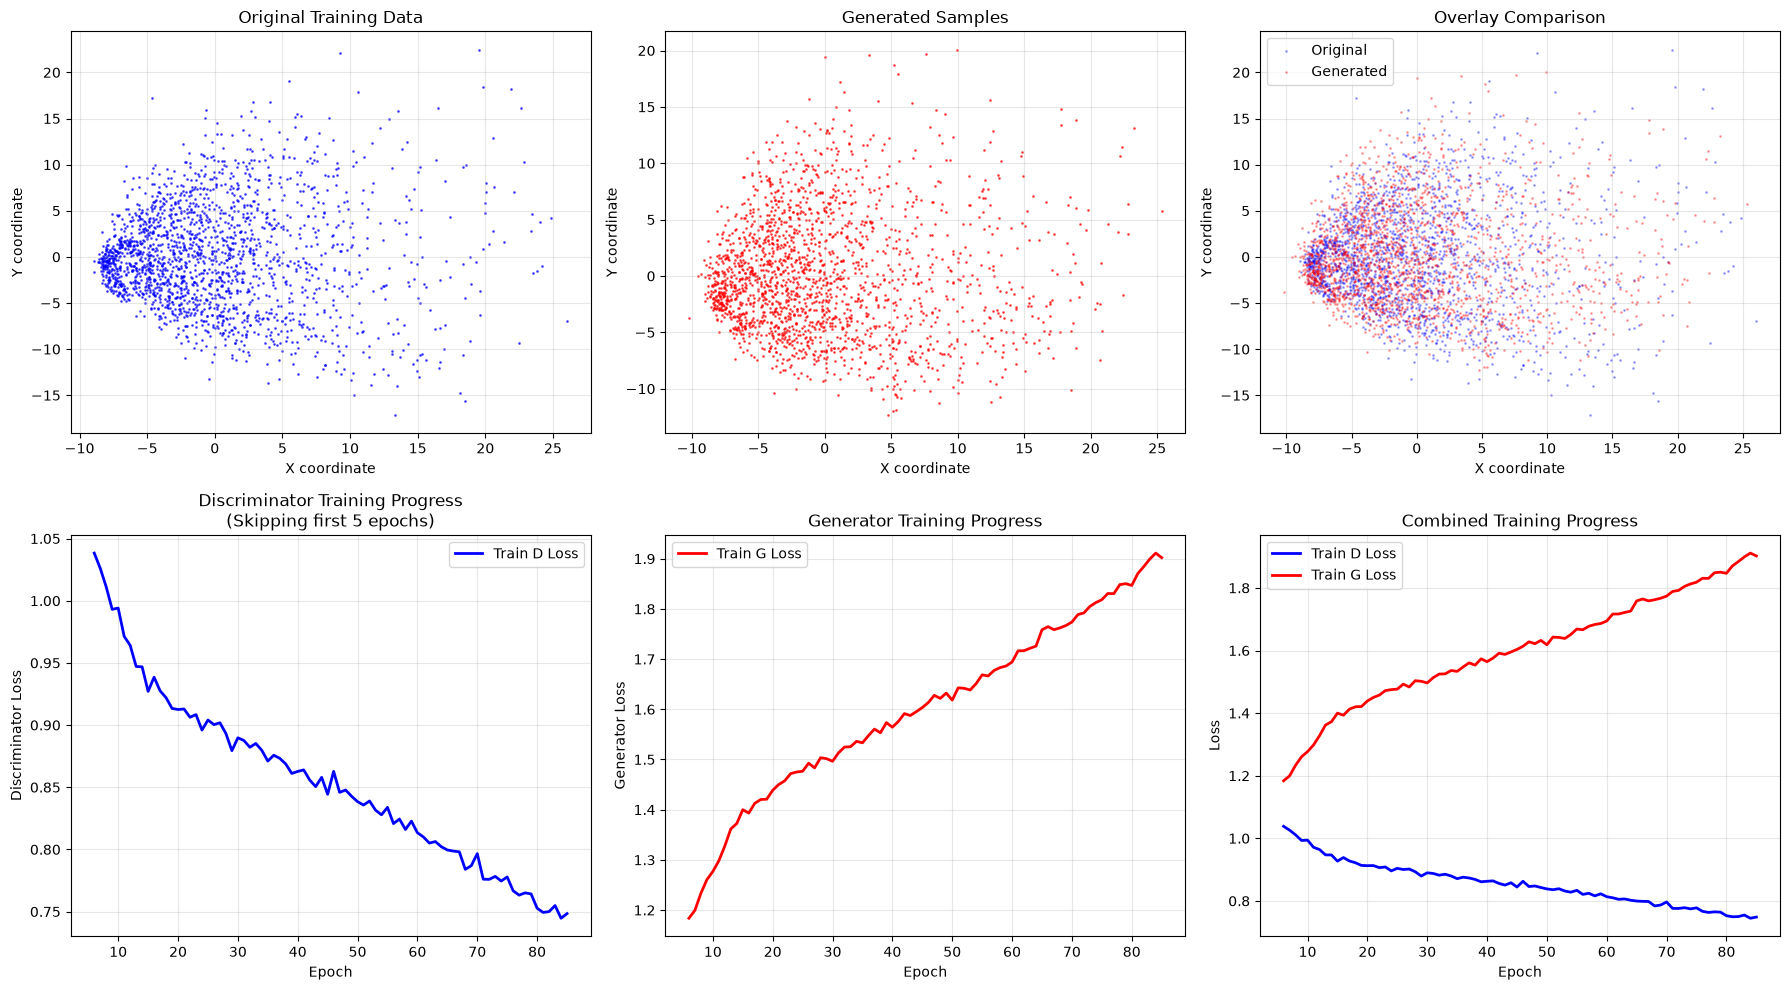

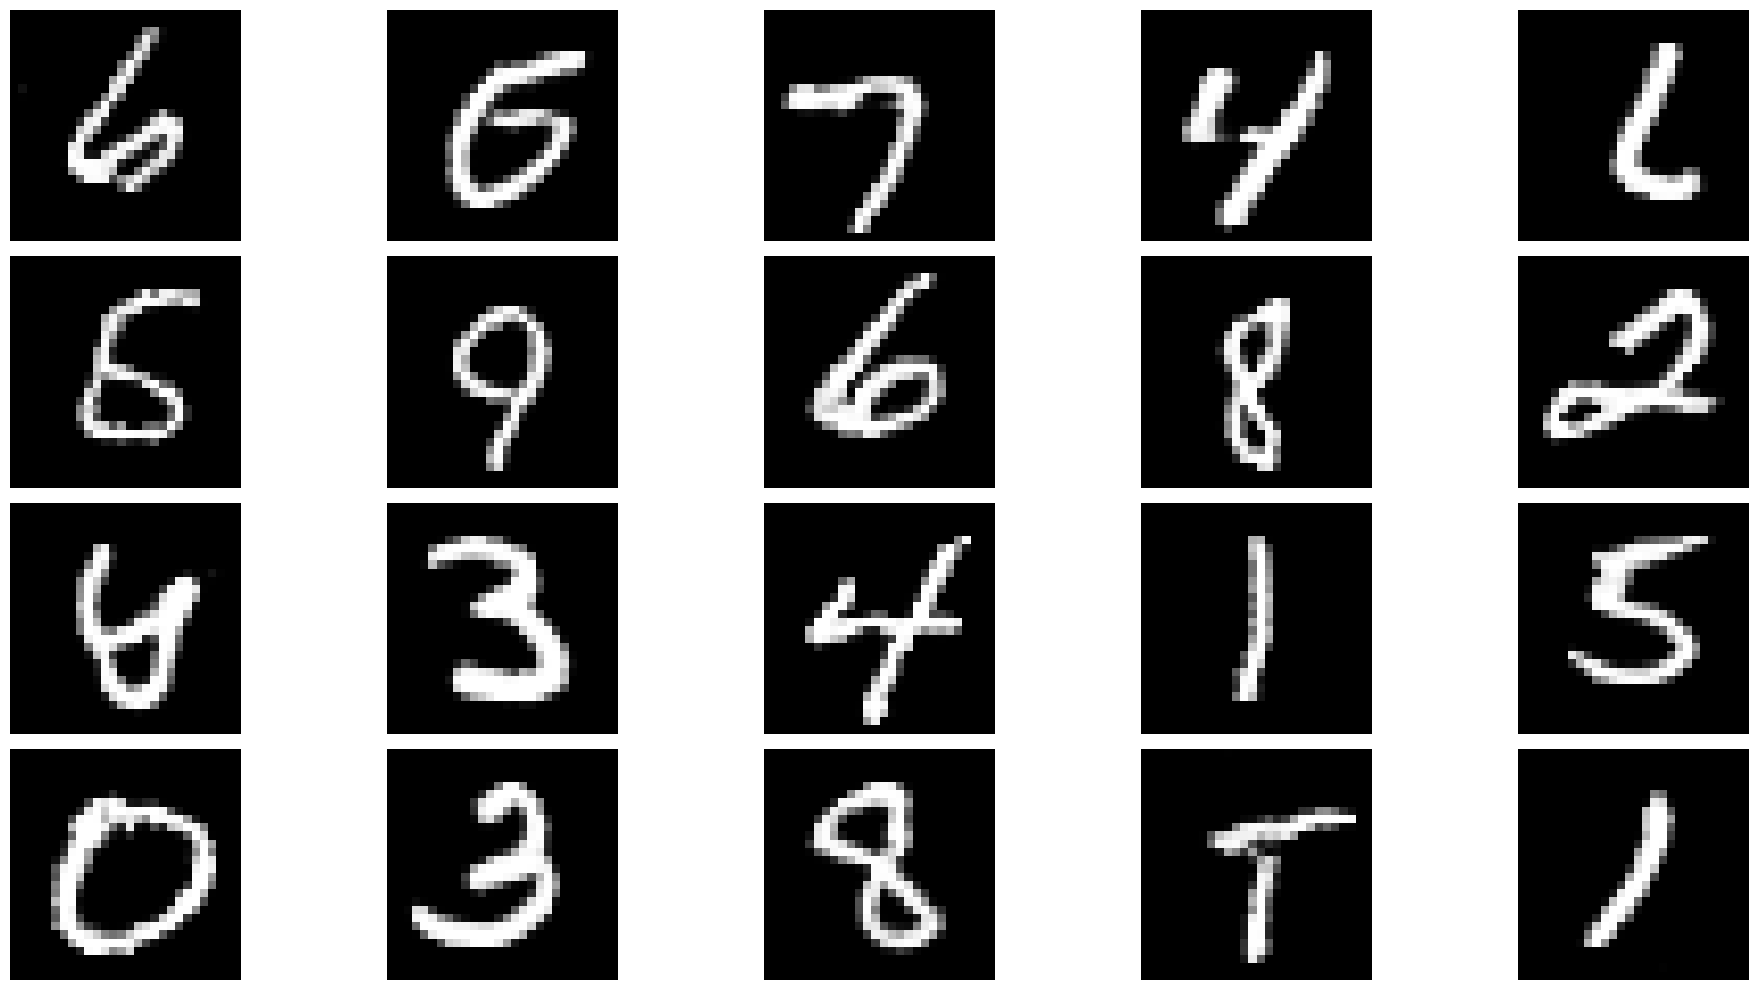

📈 Epoch 85 Summary:
   Train D Loss: 0.7484, Val D Loss: 1.7401
   Train G Loss: 1.9021, Val G Loss: 2.9376

📊 Epoch 86/100
----------------------------------------
Epoch: 86 [0/60000 (0%)]	D_loss: 0.682020	G_loss: 1.847965
Epoch: 86 [6400/60000 (11%)]	D_loss: 0.559697	G_loss: 1.868775
Epoch: 86 [12800/60000 (21%)]	D_loss: 0.751444	G_loss: 2.354489
Epoch: 86 [19200/60000 (32%)]	D_loss: 0.919785	G_loss: 0.876914
Epoch: 86 [25600/60000 (43%)]	D_loss: 1.351808	G_loss: 0.599537
Epoch: 86 [32000/60000 (53%)]	D_loss: 0.718251	G_loss: 1.895284
Epoch: 86 [38400/60000 (64%)]	D_loss: 0.612728	G_loss: 2.037034
Epoch: 86 [44800/60000 (75%)]	D_loss: 0.770287	G_loss: 2.019443
Epoch: 86 [51200/60000 (85%)]	D_loss: 0.692039	G_loss: 1.590270
Epoch: 86 [57600/60000 (96%)]	D_loss: 0.867252	G_loss: 0.962923
====> Epoch: 86 Train D_loss: 0.7325, Train G_loss: 1.9047
====> Epoch: 86 Val D_loss: 1.5092, Val G_loss: 2.4385
📈 Epoch 86 Summary:
   Train D Loss: 0.7325, Val D Loss: 1.5092
   Train G Loss: 1.9047

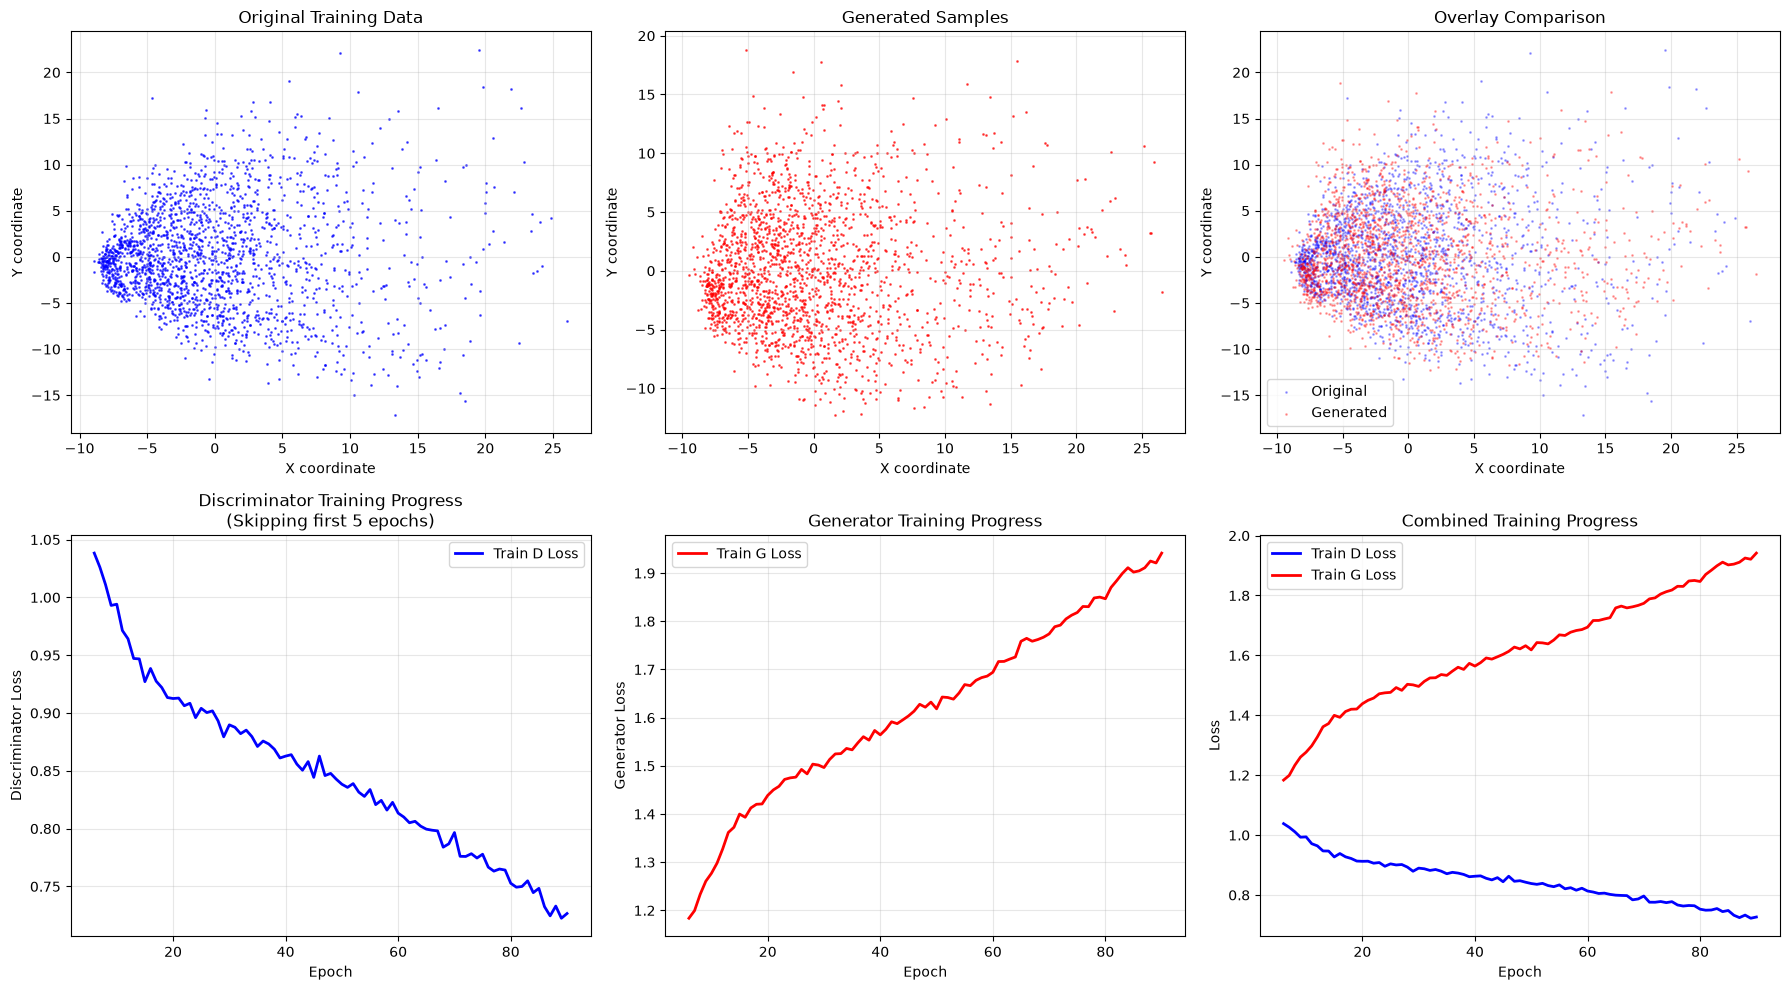

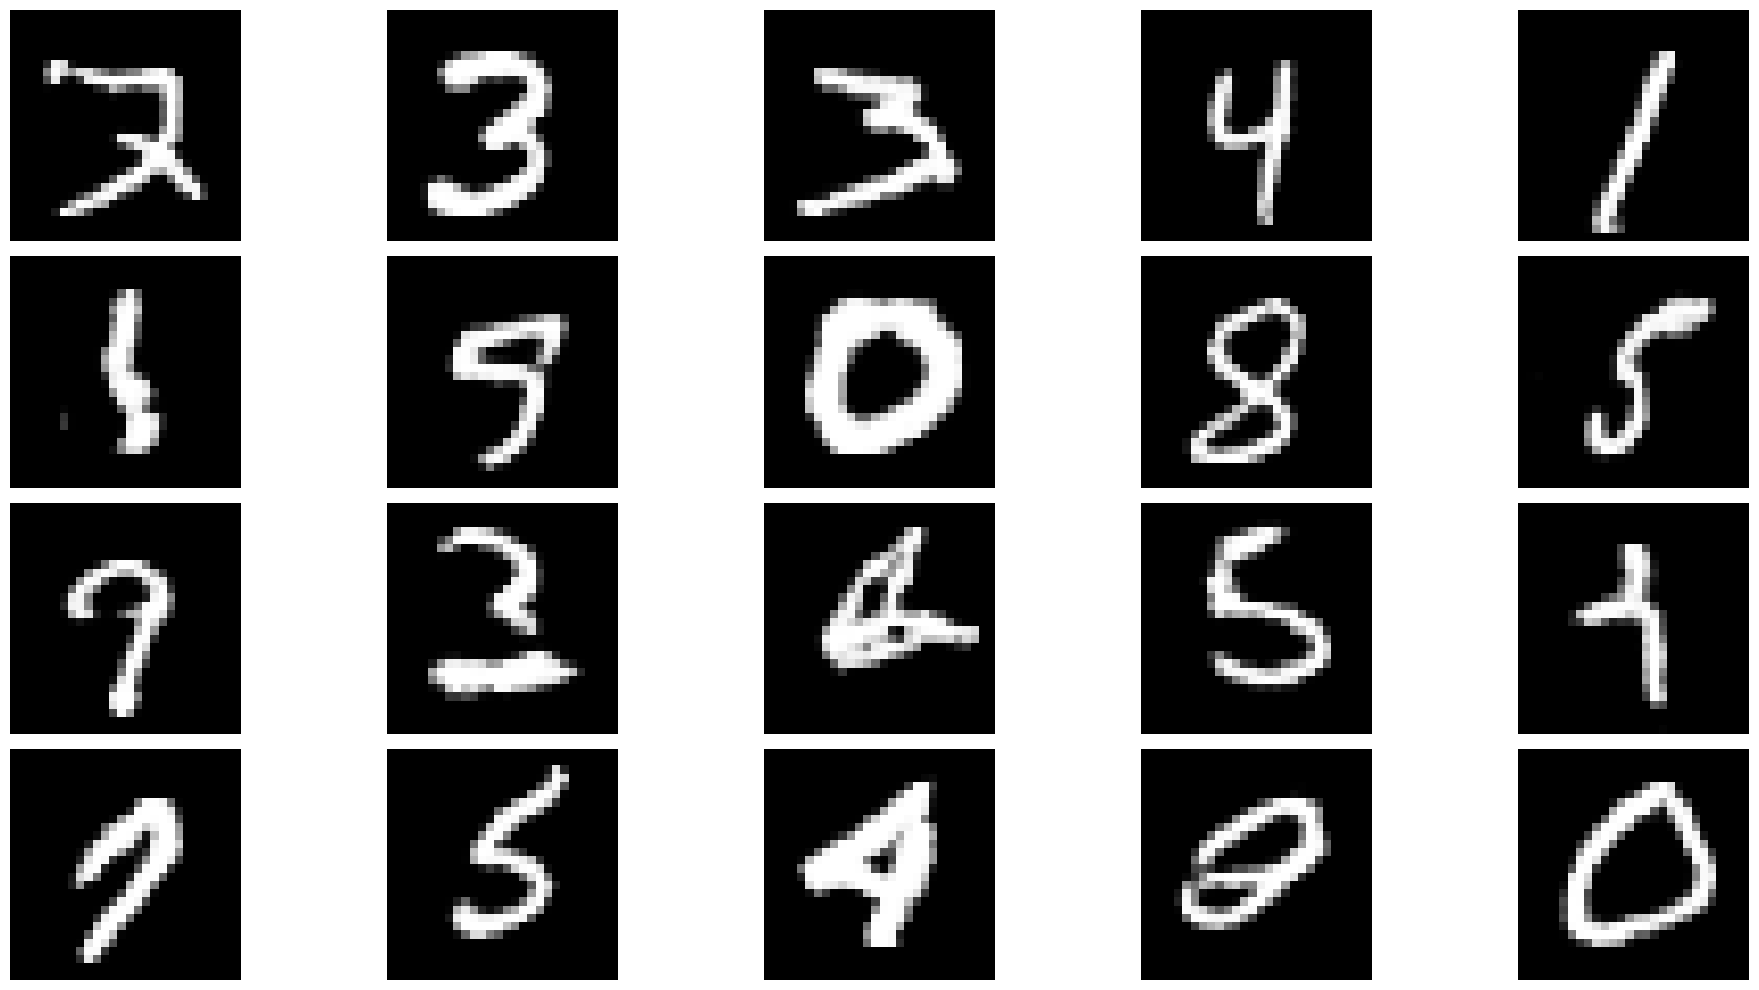

📈 Epoch 90 Summary:
   Train D Loss: 0.7266, Val D Loss: 1.2012
   Train G Loss: 1.9416, Val G Loss: 1.7888

📊 Epoch 91/100
----------------------------------------
Epoch: 91 [0/60000 (0%)]	D_loss: 0.629888	G_loss: 1.191198
Epoch: 91 [6400/60000 (11%)]	D_loss: 0.796682	G_loss: 2.198073
Epoch: 91 [12800/60000 (21%)]	D_loss: 0.609879	G_loss: 2.072111
Epoch: 91 [19200/60000 (32%)]	D_loss: 0.614633	G_loss: 1.836147
Epoch: 91 [25600/60000 (43%)]	D_loss: 1.077765	G_loss: 0.845794
Epoch: 91 [32000/60000 (53%)]	D_loss: 0.621199	G_loss: 1.379048
Epoch: 91 [38400/60000 (64%)]	D_loss: 0.749447	G_loss: 2.765818
Epoch: 91 [44800/60000 (75%)]	D_loss: 0.690060	G_loss: 2.231688
Epoch: 91 [51200/60000 (85%)]	D_loss: 0.799248	G_loss: 1.160563
Epoch: 91 [57600/60000 (96%)]	D_loss: 0.736400	G_loss: 1.266919
====> Epoch: 91 Train D_loss: 0.7280, Train G_loss: 1.9640
====> Epoch: 91 Val D_loss: 1.1586, Val G_loss: 1.7143
📈 Epoch 91 Summary:
   Train D Loss: 0.7280, Val D Loss: 1.1586
   Train G Loss: 1.9640

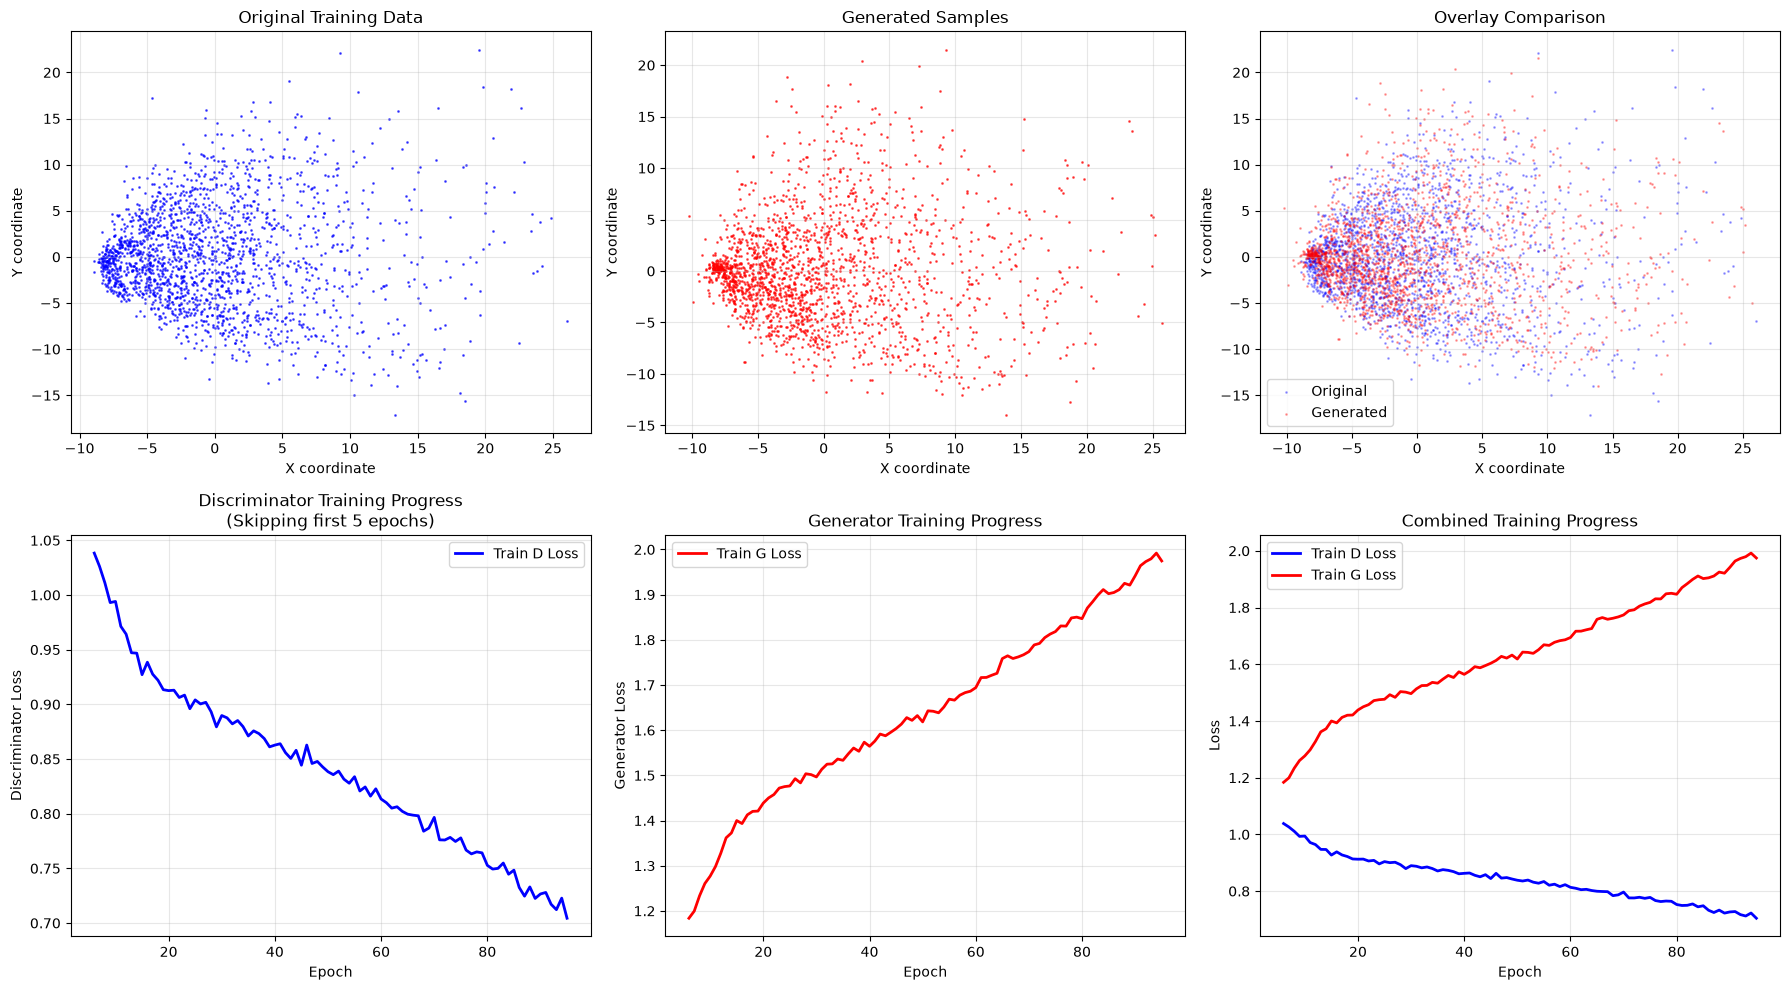

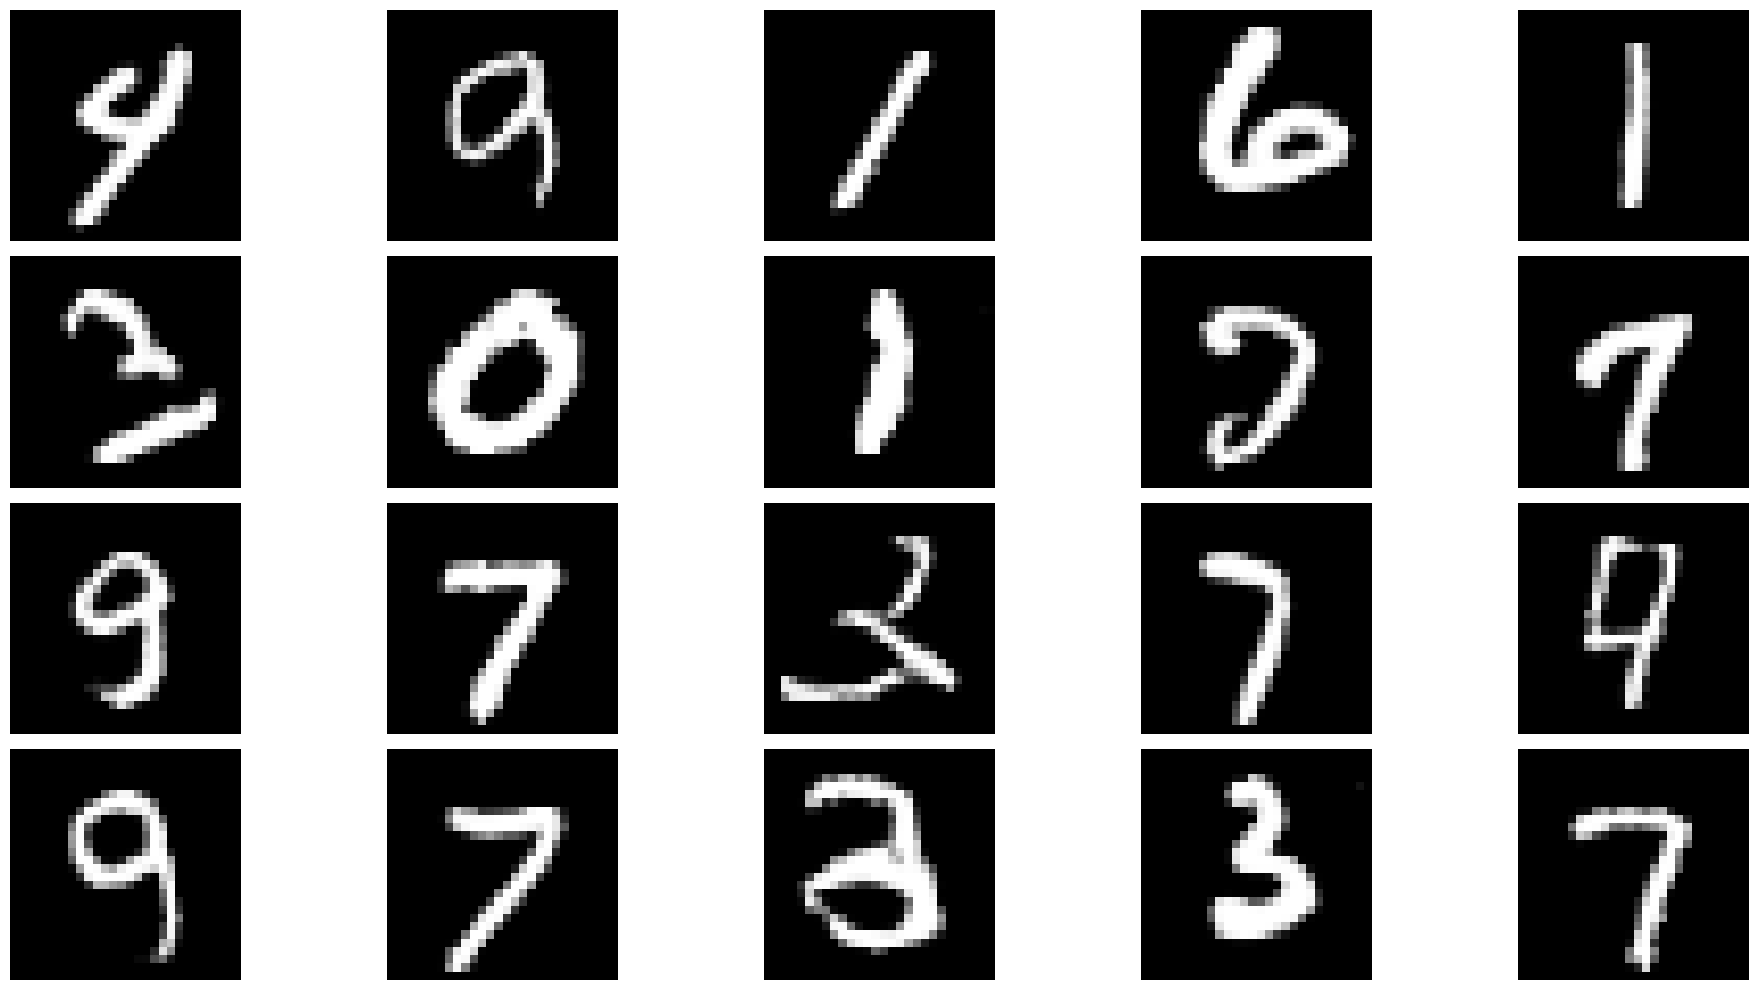

📈 Epoch 95 Summary:
   Train D Loss: 0.7044, Val D Loss: 1.2046
   Train G Loss: 1.9746, Val G Loss: 1.7702

📊 Epoch 96/100
----------------------------------------
Epoch: 96 [0/60000 (0%)]	D_loss: 0.776271	G_loss: 2.259244
Epoch: 96 [6400/60000 (11%)]	D_loss: 0.574074	G_loss: 1.515692
Epoch: 96 [12800/60000 (21%)]	D_loss: 0.840291	G_loss: 1.651087
Epoch: 96 [19200/60000 (32%)]	D_loss: 0.611116	G_loss: 1.469515
Epoch: 96 [25600/60000 (43%)]	D_loss: 0.641001	G_loss: 1.842664
Epoch: 96 [32000/60000 (53%)]	D_loss: 0.868678	G_loss: 2.947690
Epoch: 96 [38400/60000 (64%)]	D_loss: 0.659309	G_loss: 1.958987
Epoch: 96 [44800/60000 (75%)]	D_loss: 0.687496	G_loss: 1.821104
Epoch: 96 [51200/60000 (85%)]	D_loss: 0.822050	G_loss: 1.712837
Epoch: 96 [57600/60000 (96%)]	D_loss: 0.742640	G_loss: 1.185199
====> Epoch: 96 Train D_loss: 0.7135, Train G_loss: 1.9936
====> Epoch: 96 Val D_loss: 1.2125, Val G_loss: 1.8961
📈 Epoch 96 Summary:
   Train D Loss: 0.7135, Val D Loss: 1.2125
   Train G Loss: 1.9936

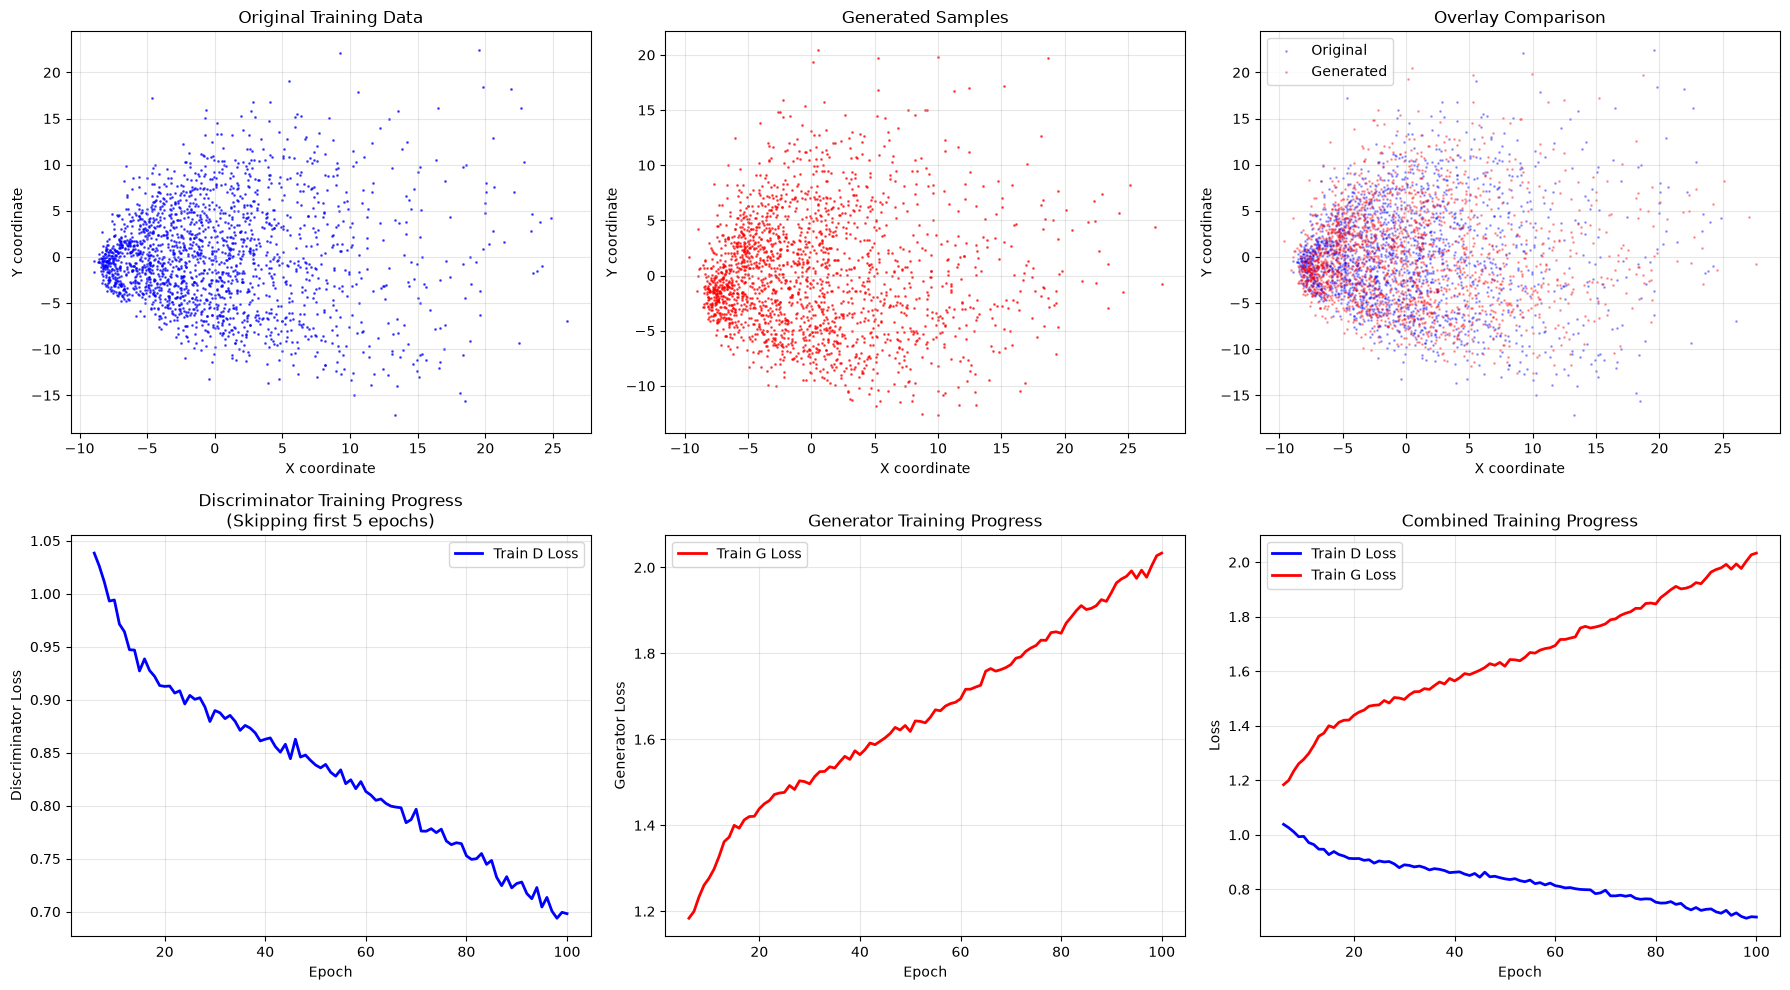

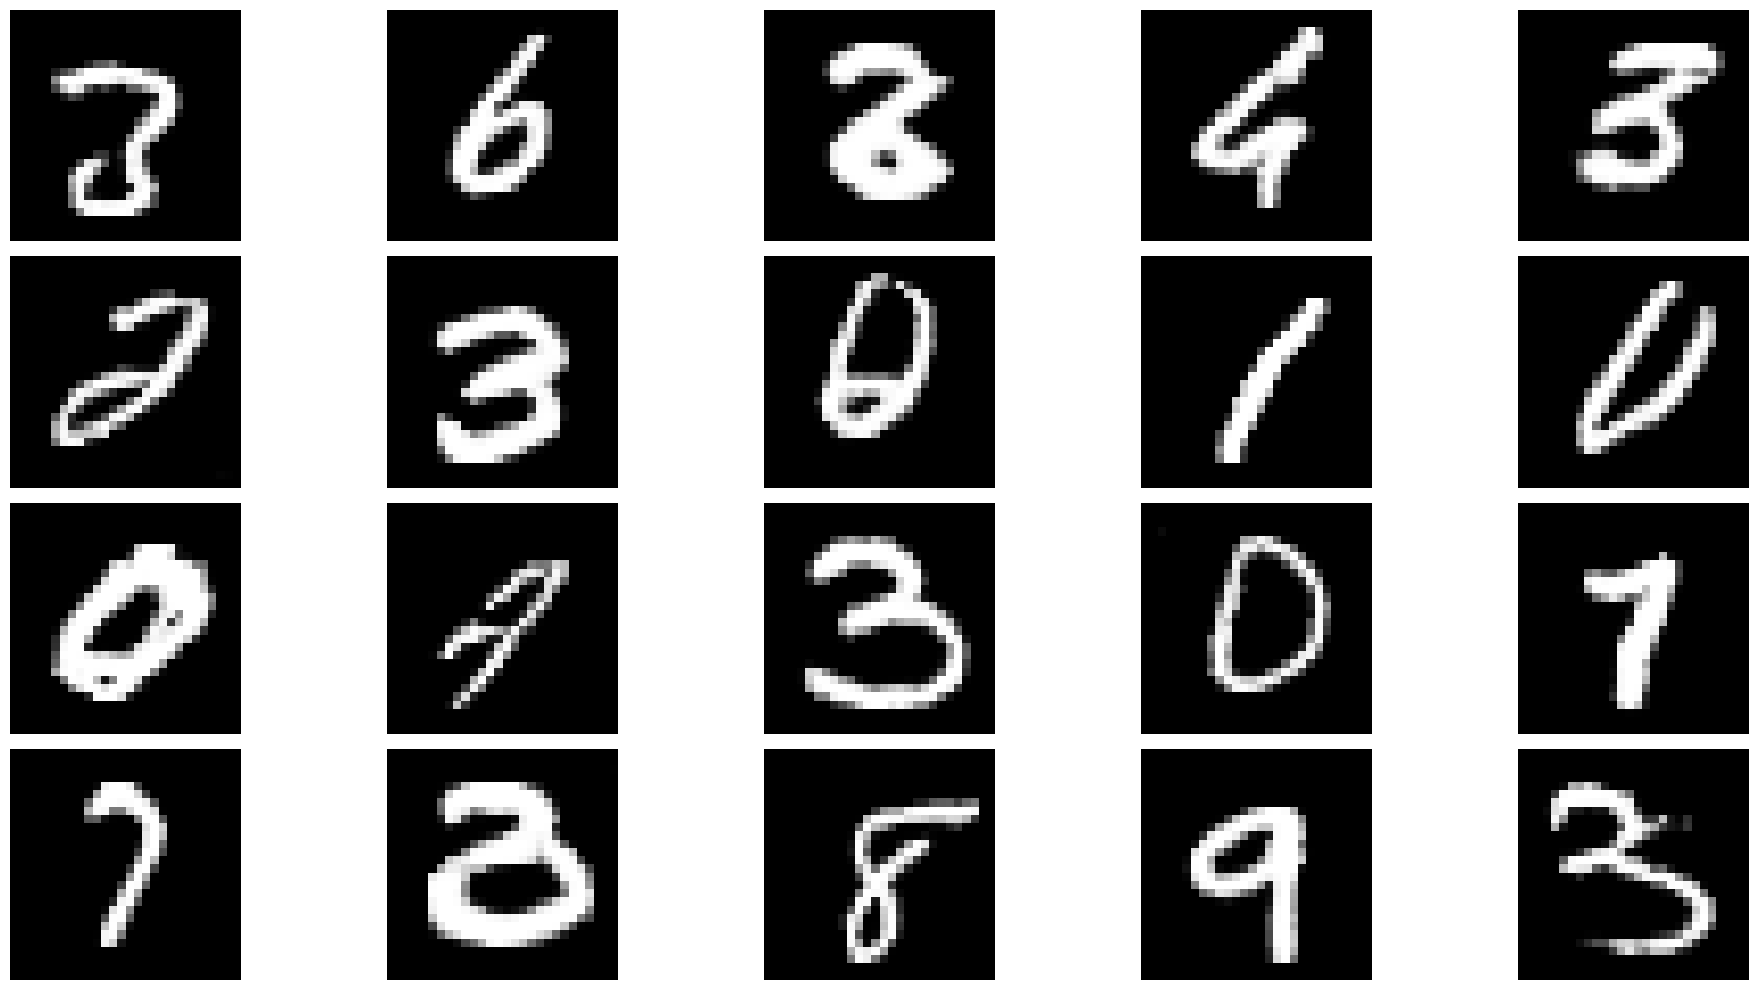

📈 Epoch 100 Summary:
   Train D Loss: 0.6982, Val D Loss: 1.2703
   Train G Loss: 2.0334, Val G Loss: 0.9010

🎉 Training completed!

🎨 Final comprehensive visualization:


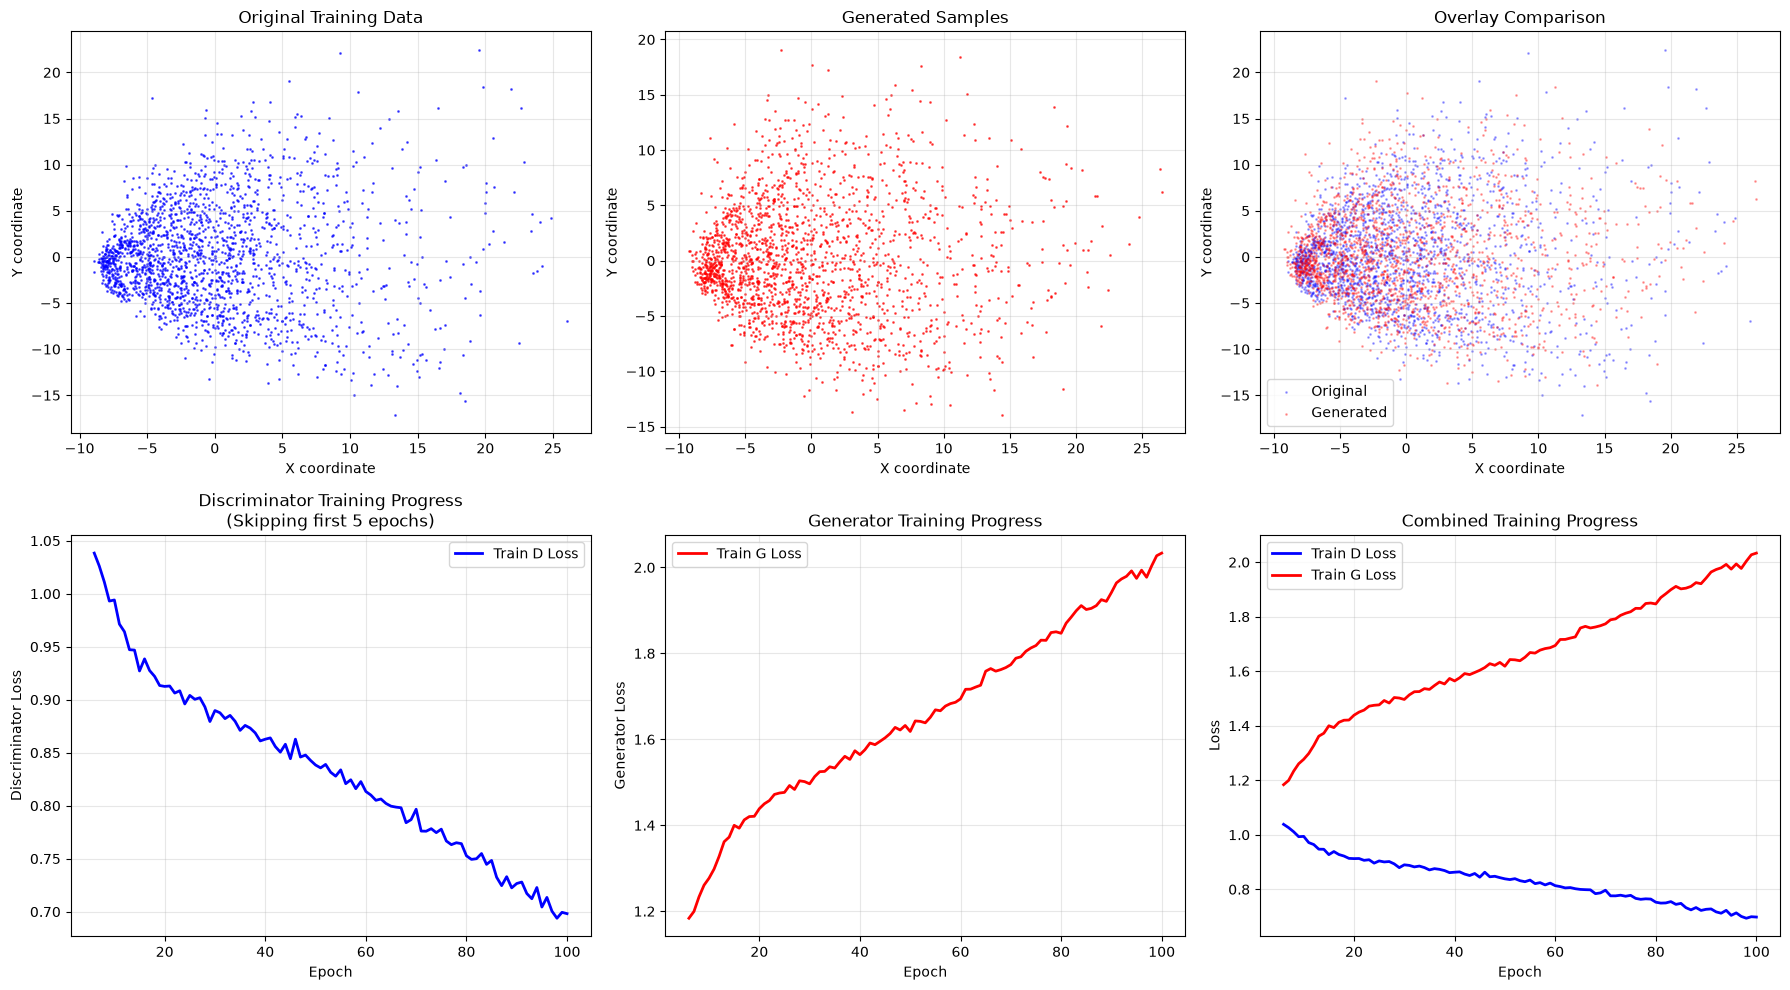

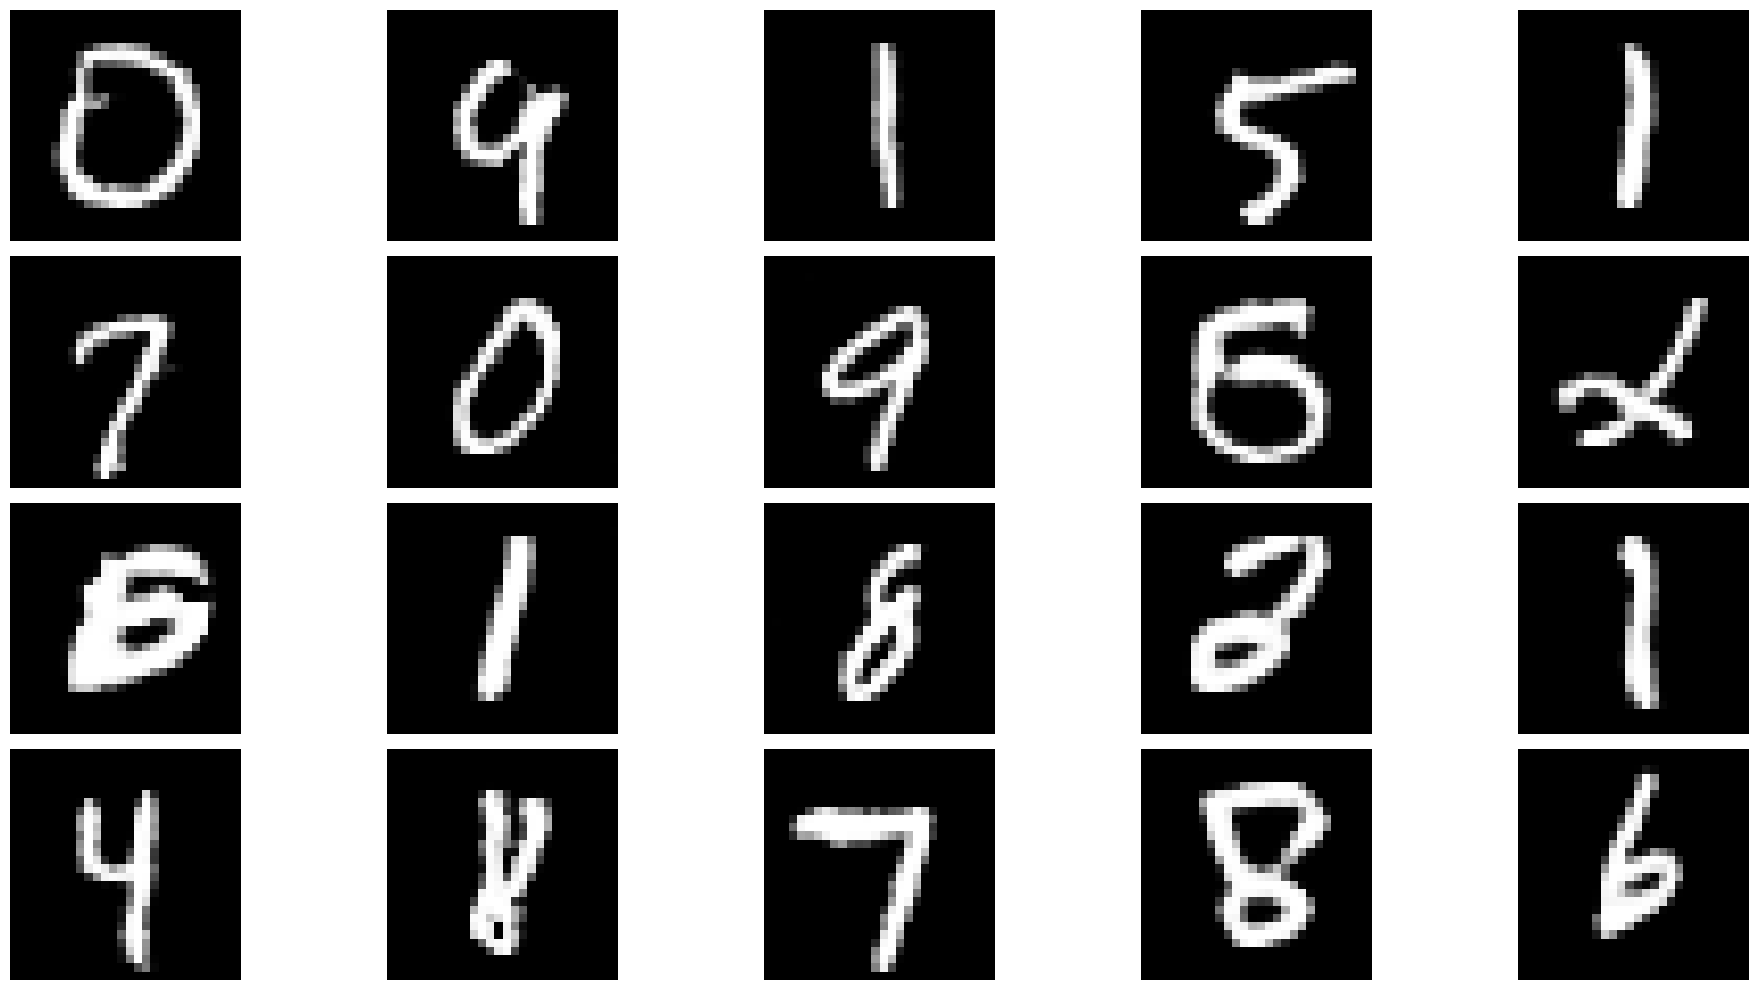

In [14]:
# Training loop
print("🎯 Starting GAN training...")
print("=" * 60)

# Lists to track training progress
train_d_losses = []
train_g_losses = []
val_d_losses = []
val_g_losses = []

# Show initial state (before training)
print("📊 Initial state (before training):")

for epoch in range(1, EPOCHS + 1):
    print(f"\n📊 Epoch {epoch}/{EPOCHS}")
    print("-" * 40)
    
    # Train for one epoch with validation
    train_d_loss, train_g_loss, val_d_loss, val_g_loss = train_epoch_with_validation(epoch)
    
    # Track losses
    train_d_losses.append(train_d_loss)
    train_g_losses.append(train_g_loss)
    val_d_losses.append(val_d_loss)
    val_g_losses.append(val_g_loss)
    
    # Visualize progress every 5 epochs
    if epoch % SAVE_PLT_INTERVAL == 0:
        print(f"\n🎨 Visualizing progress at epoch {epoch}...")
        visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses)
    
    print(f"📈 Epoch {epoch} Summary:")
    print(f"   Train D Loss: {train_d_loss:.4f}, Val D Loss: {val_d_loss:.4f}")
    print(f"   Train G Loss: {train_g_loss:.4f}, Val G Loss: {val_g_loss:.4f}")

print("\n🎉 Training completed!")
print("=" * 60)

# Save the trained models
# torch.save(generator.state_dict(), 'generator.pth')
# torch.save(discriminator.state_dict(), 'discriminator.pth')
# print("💾 Models saved as 'generator.pth' and 'discriminator.pth'")

# Final comprehensive visualization
print("\n🎨 Final comprehensive visualization:")
visualize_training_progress(EPOCHS, train_d_losses, train_g_losses, val_d_losses, val_g_losses)


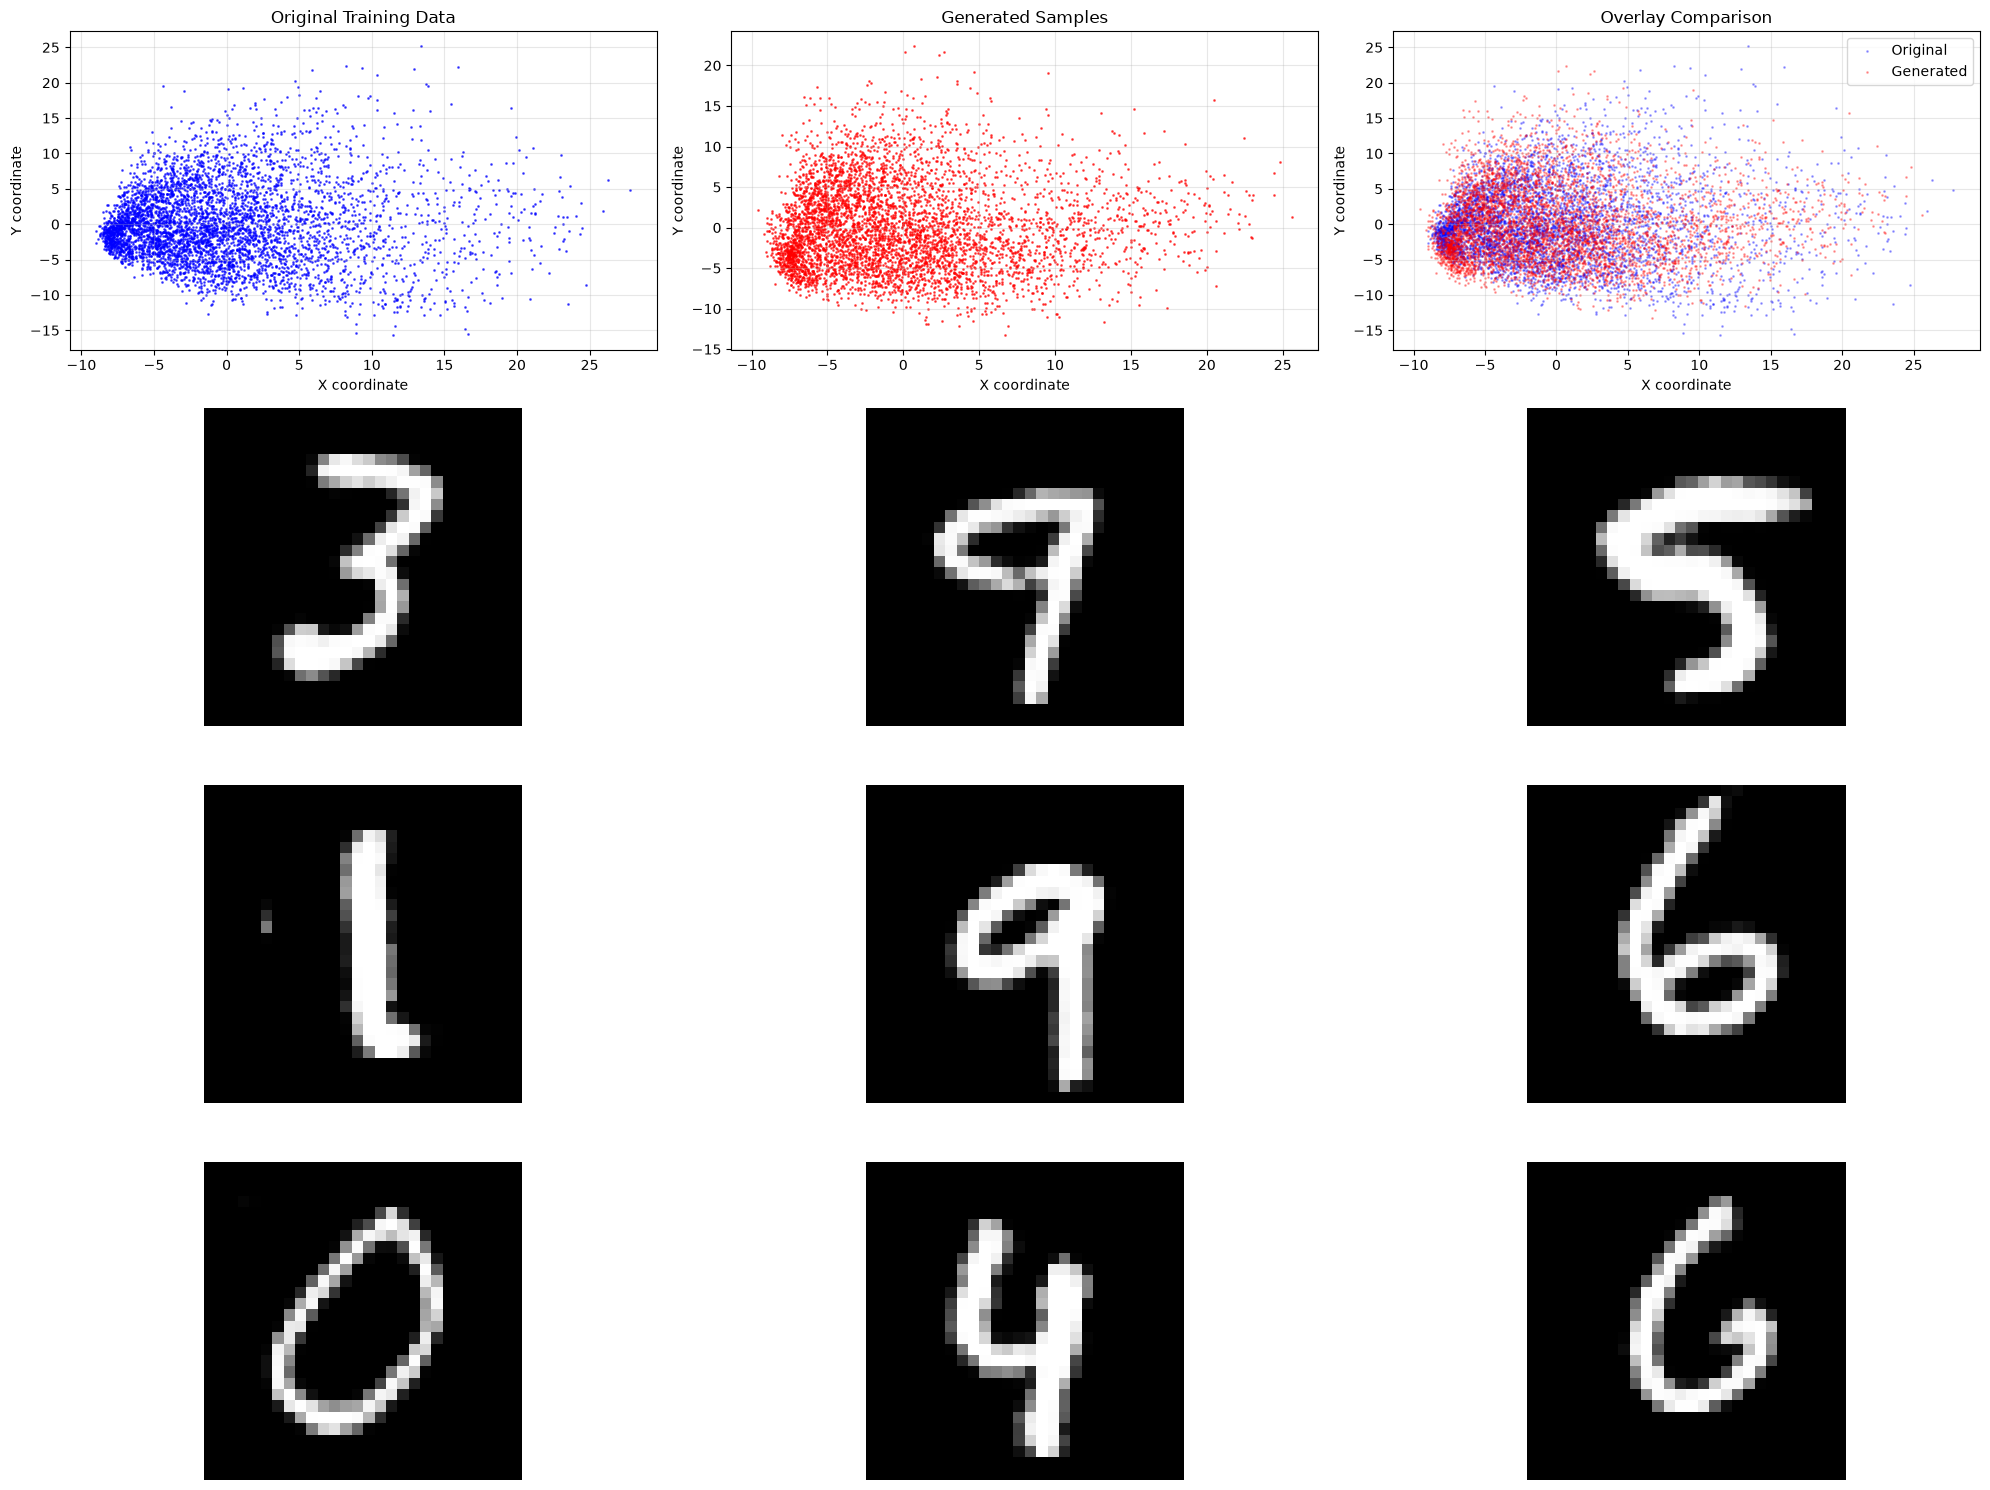

Real data confidence: 0.873
Fake data confidence: 0.502


In [15]:
# Generate a large number of samples
generated_samples = generate_samples(5000)

# Create comprehensive visualization
plt.figure(figsize=(20, 15))

train_data_reshaped = np.reshape(train_data.data[:5000], [5000, INPUT_DIM])
data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
x_transformed = pca_fit(generated_samples).transform(generated_samples)

# Original training data
plt.subplot(4, 3, 1)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
plt.title('Original Training Data')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Generated samples
plt.subplot(4, 3, 2)
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
plt.title('Generated Samples')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Overlay comparison
plt.subplot(4, 3, 3)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
plt.title('Overlay Comparison')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.legend()
plt.grid(True, alpha=0.3)


for i in range(9):
    plt.subplot(4, 3, 3 + i + 1)
    plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()


generator.eval()
discriminator.eval()
with torch.no_grad():
    # Test on real data
    real_batch = train_data.data[:100].unsqueeze(1).to(device).float() / 255.0
    real_pred = discriminator(real_batch).mean().item()

    # Test on fake data
    noise = torch.randn(100, NOISE_DIM).to(device)
    fake_batch = generator(noise)
    fake_pred = discriminator(fake_batch).mean().item()

print(f'Real data confidence: {real_pred:.3f}')
print(f'Fake data confidence: {fake_pred:.3f}')
